# A New Hampshire Paradox: The Arsenic Extension

### An object-oriented statistical companion analysis to the capstone



**What is a New Hampshire Paradox?** New Hampshire looks, by standard
economic measures, like one of the healthiest states in the country: one of
the nation's lowest unemployment rates (around 3.1 percent) and seventh in
median household income. Yet the state also ranks second nationally in
bladder cancer incidence, sixth in breast cancer incidence, and first in
brain cancer incidence, figures that are unexpectedly high given its overall
socioeconomic advantages. That contradiction, a wealthy, low-unemployment
state posting cancer surveillance numbers more typical of a high-risk
population, is the paradox the capstone dashboard investigates. The central
question is whether this reflects genuine elevated disease burden, or a
socioeconomic "masking effect," where higher income drives greater
healthcare access and screening, which inflates *detected* incidence without
reflecting a true difference in underlying disease rates.

**Capstone dashboard:** [A New Hampshire Paradox](https://pritish-ponaka.shinyapps.io/nhparadox/)

**Dataset:** Lombard, Hayes, Andy, Fahnestock, Bryce, and Ayotte (2017), *Testing
data set for independent analysis of New Hampshire arsenic model*. U.S.
Geological Survey data release, [10.5066/F7XK8CQV](https://doi.org/10.5066/F7XK8CQV)
(CC0, public domain). 373 NH bedrock wells, 45 geologic/geochemical/hydrologic
predictors, binary arsenic-exceedance target.

**Why this dataset, and how it connects to the capstone:** arsenic in
private well water is an established, biologically plausible bladder
carcinogen *specific to this region* (Karagas et al., *Elevated Bladder
Cancer in Northern New England: The Role of Drinking Water and Arsenic*).
The capstone dashboard linked above explicitly named arsenic as an
out-of-scope confounder when investigating the masking-effect question. This
notebook is the extension arm that picks that exact thread back up, on its
own terms, using the same geography and the same underlying public-health
question.

**Framing honesty check:** this predicts arsenic *exceedance*, the exposure,
not bladder cancer diagnosis. Individual-level cancer case data for this
population (Karagas et al., 1213 cases / 1418 controls) exists but is
restricted human-subjects data, not something this project can access.

**What this notebook covers, section by section:**

| Part | Section | Covers |
|---|---|---|
| 1. Data Input and Validation | 0. Setup | imports, optional-package handling, output folders, figure archive |
| | 1. Helper Functions | county-name cleanup, the multiple-testing correction |
| | 2. Data Upload and Input Validation | reads your file, validates it, profiles it, and fixes the primary metric from your goal |
| | 3. `ArsenicDataset` | why arsenic matters, the three thresholds, clean and validate |
| | 4. Data Documentation | every predictor, with an honest confidence level |
| 2. Data Processing and Exploration | 5. Data Quality Assessment | missing values, impossible values, outliers, rare flags, anticipated preprocessing |
| | 6. Preprocessing | the cleaning pipeline every model shares |
| | 7. Dataset Exploration | structure, descriptive statistics, and the math behind them |
| | 8. Visualizing the Data | class balance, distributions, correlation heatmap |
| | 9. Mapping the Results | the two NH county maps |
| 3. Analytical Pipeline | 10. Advanced Statistical Exploration | one significance test per predictor, with formulas, plus a multicollinearity check |
| | 11. Project Planning | the prediction problem, the predefined primary metric, and the selection rule |
| | 12. Pipeline Plan | conditional logic: settings adapt to the data and your goal |
| | 13. Modeling Roadmap | how the modeling sections fit together |
| | 14 to 16. Logistic Regression, Random Forest, Gradient Boosting | each model, with its math |
| | 17. Hyperparameter Tuning | settings searched by cross-validation |
| | 18. Inferential Analysis | odds ratios with confidence intervals |
| 4. Model Evaluation and Interpretation | 19. Nested Cross-Validation and Evaluation | every metric, with bootstrap intervals |
| | 20. Model Selection | the predefined metric picks the model, with justification |
| | 21. Advanced Visualizations | curves, trade-offs, county calibration, importance, partial dependence |
| | 22. What We Can Conclude | rules for turning results into conclusions |
| | 23. Capstone Tie-Back | what this adds to the New Hampshire Paradox |
| | 24. What's Next | the hierarchical model, statewide surface, and website |
| | 25. Audit | every file generated, and every requirement checked |

**Visualizations included:**

- **Class balance** (bar chart): how many wells fall above versus below the arsenic threshold. Required by the assignment, and the reason PR-AUC rather than plain accuracy is used later in Project Planning.
- **Predictor distributions** (a grid of histograms): the shape of each numeric predictor's values. Required by the assignment, and a visual check on the skewness the statistical screening section accounts for.
- **A correlation heatmap**: how strongly each pair of predictors relates to the others. Pairs directly with the VIF check in section 10.
- **A county choropleth map**: New Hampshire's counties, colored by a 3 by 3 grid combining exceedance rate with number of wells tested, using the original Shiny app's own color palette.
- **A dot-density well map**: one dot per well, colored by target class, placed randomly within its county. This is explicitly approximate, since the dataset only records a well's county, not its exact coordinates.

---

**Architecture:** Each class has one job:

| Class | Responsibility |
|---|---|
| `ArsenicDataset` | clean, validate, describe |
| `DataQualityAuditor` | missing values, impossible values, outliers, rare flags (all variable-type-aware) |
| `StatisticalScreener` | picks the *right* significance test per predictor, applies multiple-testing correction |
| `EDAVisualizer` | class balance, distributions, correlation heatmap |
| `BivariateMapVisualizer` | the two NH county maps, using the project's actual color palette |
| `Preprocessor` | the cleaning pipeline every model shares, learned from training wells only |
| `LogisticSpec`, `RandomForestSpec`, `GradientBoostingSpec` | the three supervised classifiers, each with its settings to tune |
| `HyperparameterTuner` | searches each model's settings |
| `ModelSuite` | nested cross-validation: tuning and the decision cutoff happen inside every fold |
| `ModelEvaluator` | every metric, bootstrap intervals, paired comparisons |
| `ModelVisualizer` | curves, trade-offs, county calibration, importance, partial dependence |
| `InferentialReport` | odds ratios with confidence intervals |

Plain functions handle upload and validation (`load_user_dataset`, `validate_user_dataframe`), conditional planning (`plan_pipeline`), model selection (`select_best_model`), and the final audit (`run_audit`).

Run top to bottom. Every class was built and unit-tested in isolation before being assembled here. See the inline comments for *why* each design decision was made, not just *what* the code does.

**Still planned, not built here:** This dataset's small size (373 wells) was chosen deliberately to work with real data suppression, not despite it. What remains is a hierarchical model that shrinks small-group estimates toward the state mean instead of hiding them, a continuous statewide risk surface, and an interactive website (section 24).


## Data Selection

- **Dataset name:** Testing data set for independent analysis of New Hampshire arsenic model
- **Source URL / DOI:** [https://doi.org/10.5066/F7XK8CQV](https://doi.org/10.5066/F7XK8CQV)
  (U.S. Geological Survey data release, ScienceBase item `5877e09be4b0b8c259c4875b`, CC0 / public domain)
- **Why this dataset was selected:** see the capstone connection and
  masking-effect framing in the introduction above. In short: arsenic in
  private well water is an established bladder carcinogen specific to this
  region, and the capstone dashboard named it as an out-of-scope confounder.
  This notebook extends that thread directly.
- **Why 373 records, specifically, a deliberate choice, not a compromise:**
  I purposefully selected a dataset sized at 373 records because I wanted
  to work directly with *data suppression*: small cell counts, censored
  location fields, non-detect handling, rare binary flags with a single
  positive case, rather than the much larger, pre-cleaned datasets that let
  you avoid ever confronting that problem. Most coursework datasets push
  you toward "more records solves everything"; this project deliberately
  tackles the opposite end of that spectrum. Real government
  environmental-health data is small and suppressed far more often than
  it's huge and clean, and that constraint shapes real analysis decisions
  throughout this notebook. See in particular the Data Quality Assessment
  section (constant columns, rare bedrock-geology flags) and the two maps
  in section 9 (county-level location censoring).
- **Criteria verification:** rather than assert this in prose, the
  `ArsenicDataset.validate()` call below checks the hard requirements
  against the real, loaded data and prints a pass/fail report:
  - Binary classification problem: yes. `Exceeds_5ugL` (or `Exceeds_1ugL`/`Exceeds_10ugL`), 1 = exceeds threshold, 0 = does not
  - Minimum 300 observations: **373 wells** (confirmed below)
  - Minimum 10 predictor variables: **45 predictors** (confirmed below)

## Running this in Google Colab

This notebook also runs in Colab with no changes beyond the cell below.
Colab preinstalls most of the core scientific stack already, but not
`beautifulsoup4` (used for the ScienceBase HTML fallback) or
`geopandas`/`shapely` (used for the two maps). Installing the full list
explicitly, rather than relying on what happens to already be present,
avoids a partial-install surprise later in the notebook.

If you're running locally instead, this cell is harmless to run anyway:
`pip` skips anything already satisfied.

`scikit-learn` (the models) and `openpyxl` (reads Excel uploads) are in the same install line.

In [1]:
# Safe to run in both Colab and a local Jupyter environment.
%pip install -q pandas numpy matplotlib seaborn requests beautifulsoup4 scipy geopandas shapely scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# Part 1: Data Input and Validation

## 0. Setup

In [2]:
import sys, pathlib

# Jupyter sets the kernel's cwd to the folder containing THIS notebook, not
# necessarily the project root -- this walks up until it finds a sensible
# anchor. If you're running this notebook standalone (no other project
# files), this is a no-op; it only matters if you've placed this inside a
# larger folder structure.
current = pathlib.Path.cwd()
print("Working directory:", current)

Working directory: C:\Users\f003cc3\Documents\hds\HSE 751 Programming for HDS\Final Project\Final\Final_Project


In [3]:
# import required libraries.
import logging                     # INFO/WARNING messages: fetch status, which optional sections got skipped
import re                          # regex, used later to clean county names and parse target-column names
from pathlib import Path           # filesystem paths for RAW_DIR / OUTPUT_DIR below

import matplotlib.patheffects as pe   # white text-outline effect so map labels stay readable over any fill color
import matplotlib.pyplot as plt       # every plot in this notebook: distributions, heatmap, both maps
import numpy as np                    # arrays, random sampling for the dot-density map, z-scores, VIF math
import pandas as pd                   # the core data structure every class below is built around
import requests                       # HTTP calls: the ScienceBase fetch, the Census TIGER boundary download
import seaborn as sns                 # statistical plot styling layered on top of matplotlib
from bs4 import BeautifulSoup         # parses ScienceBase's HTML page if its JSON API fails

# No matplotlib.use() call anywhere: Jupyter sets its own inline backend,
# and forcing one here would silently block that.

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
logger = logging.getLogger("nh_arsenic")

try:
    from scipy import stats as scipy_stats  # Welch's t-test, Mann-Whitney U, chi-square, Fisher's exact, Shapiro-Wilk
    HAS_SCIPY = True
except Exception as exc:
    HAS_SCIPY = False  # degrade gracefully: the statistical screening section gets skipped, not the whole notebook
    logger.warning("scipy not available (%s) -- statistical screening will be skipped.", exc)

try:
    import geopandas as gpd                 # reads the Census TIGER county shapefile, holds the geometry column
    from shapely.geometry import Point      # random points inside a county polygon, for the dot-density map
    HAS_GEO = True
except Exception as exc:
    HAS_GEO = False  # degrade gracefully: both maps get skipped, not the whole notebook
    logger.warning("geopandas/shapely not available (%s) -- maps will be skipped.", exc)

RAW_DIR = Path("data_raw")      # cached downloads: the arsenic CSV, the county boundary shapefile
OUTPUT_DIR = Path("outputs")    # everything this notebook generates: figures, cleaned CSV, reports
RAW_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

MAP_BG = "#f7f5ef"                                             # shared background color for both maps
LABEL_HALO = [pe.withStroke(linewidth=3, foreground="white")]  # the halo effect applied to every map label

print("Setup complete. HAS_SCIPY =", HAS_SCIPY, "| HAS_GEO =", HAS_GEO)

Setup complete. HAS_SCIPY = True | HAS_GEO = True


In [4]:
from itertools import product                                    # all combinations of settings, for the tuning plots
from matplotlib.colors import LinearSegmentedColormap            # builds the amber color scale used in the heatmaps
from matplotlib.patches import Rectangle                         # draws the black box around the best setting
from sklearn.base import BaseEstimator, TransformerMixin, clone  # building blocks for the cleaning step
from sklearn.calibration import calibration_curve                # reliability curve for predicted risks
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier  # two of the three models
from sklearn.linear_model import LogisticRegression              # the third model
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)           # scoring tools
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split  # cross-validation tools
from sklearn.pipeline import Pipeline                            # chains cleaning and model into one object

# Colors reused from the project's existing palette (amber = bladder cancer, gray = brain cancer).
AMBER, BROWN, GRAY, DARK = "#ffa000", "#7a2800", "#686868", "#4e1600"
MODEL_COLORS = {"Logistic regression": AMBER, "Random forest": GRAY, "Gradient boosting": BROWN}
AMBER_CMAP = LinearSegmentedColormap.from_list("amber", ["#fff8e1", "#ffc044", "#e08000", "#7a2800", "#4e1600"])

In [5]:
import sys                                   # used to find which method is drawing each figure
FIGURE_DIR = OUTPUT_DIR / "figures"          # every figure shown in this notebook is also saved here, for the audit at the end
FIGURE_DIR.mkdir(exist_ok=True)
_figure_count = globals().get("_figure_count", {"n": 0})    # keeps numbering going if this cell is run again

if not getattr(plt.show, "_archives_figures", False):      # wrap plt.show only once, even if this cell is run again
    def _show_and_archive(*args, _real_show=plt.show, **kwargs):
        """Save each new figure to outputs/figures, then show it as usual."""
        for number in plt.get_fignums():
            fig = plt.figure(number)
            if getattr(fig, "_archived", False):
                continue                                    # already saved
            caller = sys._getframe(1)                                       # who asked for this figure to be shown
            owner = caller.f_locals.get("self")
            who = f"{type(owner).__name__}_{caller.f_code.co_name}" if owner is not None else "cell"
            title = next((ax.get_title() for ax in fig.axes if ax.get_title()), "") or (fig._suptitle.get_text() if fig._suptitle else "") or "figure"
            slug = re.sub(r"[^a-z0-9]+", "_", f"{who}_{title}".lower()).strip("_")[:60]
            _figure_count["n"] += 1
            fig.savefig(FIGURE_DIR / f"{_figure_count['n']:02d}_{slug}.png", dpi=150, bbox_inches="tight")
            fig._archived = True
        return _real_show(*args, **kwargs)
    _show_and_archive._archives_figures = True
    plt.show = _show_and_archive

print("Figure archive ready: every figure will be saved to", FIGURE_DIR)

Figure archive ready: every figure will be saved to outputs\figures


## 1. Helper Functions

Three small functions used throughout the notebook, defined once here so
every class below can reuse them.

- `_clean_county_name` cleans up a county's name so it displays correctly
  (for example, turning "COOS COUNTY" into "Coos").
- `_match_key` turns a county name into a simple, lowercase version used
  only for matching two datasets together, since different sources rarely
  spell or capitalize county names the same way.
- `_benjamini_hochberg` adjusts p-values when many statistical tests are
  run at once, explained below.

### A note on multiple testing

Running one statistical test at the usual 5 percent cutoff means a 5
percent chance of a false alarm. Running 45 tests, one per predictor, at
that same cutoff means several false alarms should be *expected* from
random noise alone, even if nothing real is happening in the data. Some
correction for this was clearly needed.

I explored this question with AI assistance after noticing the problem
while setting up the statistical screening section. My first instinct was
the Bonferroni correction: take 0.05, divide it by the number of tests
(45), and only count a result as significant if its p-value is below
that much stricter number. It is simple, and it is easy to explain in one
sentence. Through that exploration I found the Benjamini-Hochberg method
instead, which is what this notebook actually uses.

The difference: Bonferroni applies one flat, strict cutoff to every test.
Benjamini-Hochberg sorts all the p-values from smallest to largest and
uses a sliding cutoff instead, stricter for the very smallest p-values,
a little more forgiving further down the list. The practical effect is
that it catches more real patterns than Bonferroni would, while still
controlling for the same false-alarm problem. The cost is that it takes
one extra sentence to explain, which is this one.

In [6]:
# Cleans up a county name so it displays correctly, like "Coos" instead of "COOS COUNTY".
def _clean_county_name(name) -> str:
    """
    Makes a county name look clean and consistent: removes a trailing
    "county" word and fixes special characters. Census TIGER spells one
    county "Coos" with an accent mark over the o. Without this cleanup,
    that one county would fail to match anywhere else in the data.
    """
    import unicodedata
    name = re.sub(r"\s+county$", "", str(name).strip(), flags=re.IGNORECASE)
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode("ascii")
    return name.strip()


# Turns a county name into a simple lowercase key, used only for matching two datasets together.
def _match_key(name) -> str:
    """
    Same cleanup as above, but also lowercases the result. Different
    data sources rarely spell or capitalize county names the same way
    (one might use all capital letters, another might use title case).
    Comparing on this simplified key, instead of the original name, is
    what makes matching between sources actually work.
    """
    return _clean_county_name(name).lower()


# Adjusts p-values so running many statistical tests at once does not produce false alarms.
def _benjamini_hochberg(pvals, alpha=0.05):
    """
    Checks a list of p-values and decides which ones are still
    believable after accounting for how many tests were run. Running
    many tests at once (this notebook runs about 45) means a few will
    look "significant" purely by chance, even if nothing real is there.
    This method raises the bar accordingly, instead of trusting every
    p-value at face value.

    Returns two things, in the same order as the input: which results
    are still significant, and each result's adjusted p-value.
    """
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    thresholds = (np.arange(1, n + 1) / n) * alpha
    below = ranked <= thresholds
    cutoff = ranked[np.max(np.where(below))] if below.any() else 0.0
    significant_sorted = ranked <= cutoff
    adj_sorted = np.empty(n)
    running_min = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * n / rank
        running_min = min(running_min, val)
        adj_sorted[i] = running_min
    significant = np.empty(n, dtype=bool)
    adjusted = np.empty(n)
    significant[order] = significant_sorted
    adjusted[order] = adj_sorted
    return significant, adjusted

print("Helper functions defined.")

Helper functions defined.


## 2. Data Upload and Input Validation

This is the entry point. The notebook reads **your** data directly, checks it before anything else runs, and tells you plainly whether it can be used.

**Where the data can come from.** The settings cell below uses the first of these that is set:
1. **`DATA_PATH`**: a file on this computer, or one you uploaded to Colab's Files panel, such as `"my_folder/Testing_data.csv"`.
2. **`DATA_URL`**: a link to a CSV in a GitHub repository. A normal GitHub page link works, because the notebook converts it to the direct "raw" link for you. If the link cannot be read, the notebook says why and falls back to option 3.
3. **A file picker**: an upload dialog in Colab, or a file window on your own computer.

Supported formats: `.csv`, `.xlsx`, `.xls`.

**If you do not have the file,** the data-selection notebook linked in the settings cell downloads the dataset for you. Every error message below repeats that link.

**What is checked before any analysis.** Each problem is reported in plain words, and the run stops with a clear message instead of failing partway through.
1. The file or link exists, is not empty, and is a readable table (a link that returns a web page instead of data is caught).
2. Column names are not repeated.
3. The measured-arsenic column (`verified_As`) is present and numeric, because the target is built from it.
4. If a ready-made 0/1 flag for the chosen threshold is present, it contains only 0 and 1.
5. Both outcome classes are present, with enough wells in the smaller class to cross-validate.
6. Softer problems are reported as warnings and do not stop the run: fewer than 300 rows or 10 predictors (the project minimums), empty or constant columns, columns that are mostly missing, and no `County` column (the maps would be skipped).

**Your goal sets the primary metric, up front.** `USER_GOAL` in the settings cell is mapped to a primary evaluation metric before any model is run. Fixing the metric in advance keeps the final model choice honest: it cannot be picked after seeing which model looks best.

In [7]:
# ----- Settings: change these, then run the notebook from the top -----
# The data comes from the first of these that is set: DATA_PATH, then DATA_URL, then a file picker.
DATA_PATH = None                  # a file on this machine, or one uploaded to Colab's Files panel, e.g. "my_folder/Testing_data.csv"
DATA_URL = "https://github.com/pritishponaka/Final_Project/blob/main/Testing_data.csv"
PREFER_UPLOAD = True              # True: ask for an upload first, and use DATA_URL only if no file is provided. False: use DATA_URL first.
THRESHOLD_UGL = 5                 # arsenic level (1, 5, or 10 ug/L) above which a well counts as "exceeds"
USER_GOAL = "rank_for_testing"    # what the models should be best at; the choices are listed in GOAL_TO_METRIC below
DATA_SELECTION_NOTEBOOK_URL = "https://drive.google.com/file/d/1shF1Br65fvOnxYDM50G1O9Qg3GiG-z8U/view?usp=sharing"  # shown whenever the file is missing or unusable

# Each goal fixes the primary evaluation metric BEFORE any model is run.
GOAL_TO_METRIC = {
    "rank_for_testing": "pr_auc",    # order wells so the riskiest are tested first; needs no cutoff, and suits a rare outcome
    "balanced_decision": "mcc",      # make a yes/no call for each well, weighing both kinds of mistake fairly
}
METRIC_NAMES = {"pr_auc": "PR-AUC (average precision)", "mcc": "Matthews correlation coefficient (MCC)"}

if USER_GOAL not in GOAL_TO_METRIC:
    raise ValueError(f"USER_GOAL must be one of {list(GOAL_TO_METRIC)}, not '{USER_GOAL}'.")
if THRESHOLD_UGL not in (1, 5, 10):
    raise ValueError("THRESHOLD_UGL must be 1, 5, or 10 (the three published thresholds).")
if DATA_URL is not None and not str(DATA_URL).strip().lower().startswith(("http://", "https://")):
    raise ValueError("DATA_URL must start with https:// (a link to a CSV file), or be None.")
if not isinstance(PREFER_UPLOAD, bool):
    raise ValueError("PREFER_UPLOAD must be True or False.")
PRIMARY_METRIC = GOAL_TO_METRIC[USER_GOAL]   # fixed here; used later to select the best model
print(f"Goal: {USER_GOAL}  ->  primary metric: {METRIC_NAMES[PRIMARY_METRIC]}  (fixed before any model runs)")

Goal: rank_for_testing  ->  primary metric: PR-AUC (average precision)  (fixed before any model runs)


In [8]:
import io      # lets an uploaded or downloaded file be read straight from memory
import json    # saves the pipeline plan as a small text file
import os      # file paths and checks
from urllib.parse import urlparse   # picks the file name out of a web address

class DataLoadError(Exception):
    """The data could not be found, downloaded, opened, or read."""

class DataValidationError(Exception):
    """The data was read, but it cannot be used for this analysis."""

INPUT_SOURCE = {"how": "not read yet"}      # remembers where the data came from, for the audit at the end
MAX_DOWNLOAD_BYTES = 100 * 1024 * 1024      # refuse enormous downloads

def fallback_message():
    """Where to go if the user does not have the file."""
    note = ""
    if "<your-username>" in DATA_SELECTION_NOTEBOOK_URL:
        note = "\n(Set DATA_SELECTION_NOTEBOOK_URL in the settings cell to your own link.)"
    return f"No file to hand? The data-selection notebook downloads it for you:\n  {DATA_SELECTION_NOTEBOOK_URL}{note}"

def running_in_colab():
    """True when this notebook is running inside Google Colab."""
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def github_to_raw(url):
    """Turn a normal GitHub page link into the direct 'raw' link that serves the file itself. Other links pass through unchanged."""
    url = str(url).strip()
    match = re.match(r"^https?://github\.com/([^/]+)/([^/]+)/(?:blob|raw)/(.+?)(?:\?.*)?$", url)
    if match:
        owner, repo, rest = match.groups()
        return f"https://raw.githubusercontent.com/{owner}/{repo}/{rest}"
    return url

def read_from_url(url):
    """Download a data file from a web address (a GitHub page link works as it is). Returns (file name, in-memory file)."""
    if not str(url).strip().lower().startswith(("http://", "https://")):
        raise DataLoadError(f"'{url}' is not a web address. It must start with https://")
    direct = github_to_raw(url)
    try:
        response = requests.get(direct, timeout=30, headers={"User-Agent": "nh-arsenic-notebook"})
    except requests.exceptions.Timeout:
        raise DataLoadError(f"The download timed out: {direct}")
    except requests.exceptions.RequestException as exc:
        raise DataLoadError(f"Could not reach {direct} ({type(exc).__name__}). Check the link and your internet connection.")
    if response.status_code == 404:
        raise DataLoadError(f"Not found (404): {direct}\nCheck the path and the branch name. A private repository cannot be read, because this notebook does not log in to GitHub.")
    if response.status_code != 200:
        raise DataLoadError(f"The server answered with an error ({response.status_code}) for {direct}")
    if len(response.content) > MAX_DOWNLOAD_BYTES:
        raise DataLoadError("That file is larger than 100 MB, which is more than this notebook will download.")
    if response.content[:200].lstrip().lower().startswith((b"<!doctype html", b"<html")):
        raise DataLoadError(f"That link returned a web page, not a data file: {direct}\nOn GitHub, open the file and copy the link from the 'Raw' button.")
    INPUT_SOURCE["how"] = f"the web address {direct}"
    return os.path.basename(urlparse(direct).path) or "downloaded_file", io.BytesIO(response.content)

def _choose_interactively():
    """An upload dialog in Colab, or a file window on a local computer."""
    if running_in_colab():
        from google.colab import files
        uploaded = files.upload()                      # opens the Colab upload dialog
        if not uploaded:
            raise DataLoadError("No file was uploaded.\n" + fallback_message())
        name = next(iter(uploaded))
        INPUT_SOURCE["how"] = "the Colab upload dialog"
        return name, io.BytesIO(uploaded[name])
    try:
        import tkinter
        from tkinter import filedialog
        window = tkinter.Tk()
        window.withdraw()
        window.attributes("-topmost", True)            # keeps the file window in front of the browser
        chosen = filedialog.askopenfilename(title="Choose your dataset", filetypes=[("Data files", "*.csv *.xlsx *.xls"), ("All files", "*.*")])
        window.destroy()
    except Exception as exc:
        raise DataLoadError(f"A file window could not be opened here ({exc}). Set DATA_PATH or DATA_URL in the settings cell instead.\n{fallback_message()}")
    if not chosen:
        raise DataLoadError("No file was chosen.\n" + fallback_message())
    INPUT_SOURCE["how"] = "the file picker"
    return os.path.basename(chosen), chosen

def pick_file(path=None, url=None, prefer_upload=None):
    """Return (file name, thing to read). A path always wins. Otherwise PREFER_UPLOAD sets the order: upload first with the link as the fallback, or the link first with upload as the fallback."""
    if prefer_upload is None:
        prefer_upload = bool(globals().get("PREFER_UPLOAD", False))    # the setting in section 2
    if path is not None:
        if not os.path.isfile(path):
            raise DataLoadError(f"No file found at: {path}\n{fallback_message()}")
        INPUT_SOURCE["how"] = f"the file path {path}"
        return os.path.basename(path), path
    steps = ["upload", "url"] if prefer_upload else ["url", "upload"]
    if not url:
        steps.remove("url")
    problems = []
    for step in steps:
        try:
            return _choose_interactively() if step == "upload" else read_from_url(url)
        except DataLoadError as problem:
            problems.append(str(problem).replace(fallback_message(), "").strip())    # the data-selection link is added once, at the end
            if step != steps[-1]:
                print(f"{problems[-1].splitlines()[0]}\nSwitching to the {'GitHub link' if step == 'upload' else 'file upload'} instead.\n")
    raise DataLoadError("\n\n".join(problems) + "\n\n" + fallback_message())

def read_table(source, name):
    """Read a CSV or Excel file into a table, with a clear message when it cannot be read."""
    ext = os.path.splitext(name)[1].lower()
    if ext not in (".csv", ".xlsx", ".xls"):
        raise DataLoadError(f"'{ext or name}' files are not supported. Please provide a .csv, .xlsx, or .xls file.\n{fallback_message()}")
    try:
        if ext == ".csv":
            for encoding in ("utf-8", "latin-1"):      # most files are utf-8; latin-1 catches older Excel exports
                try:
                    if hasattr(source, "seek"):
                        source.seek(0)
                    return pd.read_csv(source, encoding=encoding)
                except UnicodeDecodeError:
                    continue
            raise DataLoadError(f"{name} uses a text encoding that could not be read. Re-save it as CSV (UTF-8).\n{fallback_message()}")
        return pd.read_excel(source)
    except pd.errors.EmptyDataError:
        raise DataLoadError(f"{name} is empty.\n{fallback_message()}")
    except pd.errors.ParserError as exc:
        raise DataLoadError(f"{name} could not be parsed as a table ({exc}).\n{fallback_message()}")
    except ImportError as exc:
        raise DataLoadError(f"Reading Excel files needs the 'openpyxl' package ({exc}). Run %pip install openpyxl, or provide a CSV instead.")

def load_user_dataset(path=None, url=None):
    """Pick a data source, read it, and report what was read. Returns (file name, table)."""
    name, source = pick_file(path, url)
    table = read_table(source, name)
    print(f"Read {name} from {INPUT_SOURCE['how']}: {table.shape[0]} rows x {table.shape[1]} columns")
    return name, table

print("Reading functions defined.")

Reading functions defined.


In [9]:
NON_PREDICTORS = {"obs", "verified_As", "bas1", "bas5", "bas10"}   # columns that are identifiers or hold the answer itself

def profile_dataframe(table):
    """One row per column: type, missing values, distinct values, and range, as an automatic first look."""
    rows = []
    for col in table.columns:
        s = table[col]
        numeric = pd.api.types.is_numeric_dtype(s)
        rows.append({"column": col, "type": "number" if numeric else "text", "missing": int(s.isna().sum()),
                     "missing_pct": round(float(s.isna().mean()) * 100, 2), "distinct": int(s.nunique(dropna=True)),
                     "min": s.min() if numeric and s.notna().any() else "", "max": s.max() if numeric and s.notna().any() else ""})
    return pd.DataFrame(rows)

def validate_user_dataframe(table, threshold_ugl=5, min_rows=300, min_predictors=10):
    """
    Check an uploaded table before any analysis. Problems that make the analysis impossible raise
    DataValidationError (listing every problem at once); softer ones are returned as warnings.
    """
    if table is None or table.shape[0] == 0 or table.shape[1] == 0:
        raise DataValidationError("The file contains no data.\n" + fallback_message())
    problems, warns = [], []
    cols = [str(c).strip() for c in table.columns]
    repeated = sorted({c for c in cols if cols.count(c) > 1})
    if repeated:                                       # stop here: every later check looks columns up by name
        raise DataValidationError(f"The file cannot be used:\n  - Column names are repeated: {repeated}. Each column needs its own name.\n" + fallback_message())
    work = table.copy()
    work.columns = cols

    flag_col = f"bas{threshold_ugl}"
    positives = negatives = None
    if "verified_As" not in cols:
        problems.append(f"The measured-arsenic column 'verified_As' is missing. Columns found: {cols[:10]}{' ...' if len(cols) > 10 else ''}")
    else:
        conc = pd.to_numeric(work["verified_As"], errors="coerce")
        if conc.notna().sum() == 0:
            problems.append("'verified_As' contains no numeric values.")
    if flag_col in cols:
        flag = pd.to_numeric(work[flag_col], errors="coerce")
        text_entries = work[flag_col].notna() & flag.isna()
        if text_entries.any():
            problems.append(f"'{flag_col}' has {int(text_entries.sum())} entries that are not numbers.")
        elif not set(flag.dropna().unique()).issubset({0, 1}):
            problems.append(f"'{flag_col}' must contain only 0 and 1; it contains {sorted(set(flag.dropna().unique()))[:6]}.")
        else:
            positives, negatives = int((flag == 1).sum()), int((flag == 0).sum())
            if flag.isna().any():
                warns.append(f"'{flag_col}' has {int(flag.isna().sum())} blanks; those wells have no target.")
    elif "verified_As" in cols and conc.notna().any():
        positives, negatives = int((conc >= threshold_ugl).sum()), int((conc < threshold_ugl).sum())
        warns.append(f"No ready-made '{flag_col}' flag, so the target is built from 'verified_As'; wells with no measurement will have no target.")

    if positives is not None:
        smaller = min(positives, negatives)
        if smaller == 0:
            problems.append(f"Only one outcome is present ({positives} above, {negatives} below {threshold_ugl} ug/L). Both are needed to learn anything.")
        elif smaller < 6:
            problems.append(f"Only {smaller} wells are in the smaller outcome group. Cross-validation needs at least 6.")
        elif smaller < 30:
            warns.append(f"Only {smaller} wells are in the smaller outcome group, so every result will be very uncertain.")

    predictors = [c for c in cols if c not in NON_PREDICTORS]
    if table.shape[0] < min_rows:
        warns.append(f"{table.shape[0]} rows is below the project minimum of {min_rows}.")
    if len(predictors) < min_predictors:
        warns.append(f"{len(predictors)} predictors is below the project minimum of {min_predictors}.")
    empty = [c for c in predictors if work[c].isna().all()]
    if empty:
        warns.append(f"Columns that are entirely empty: {empty[:6]}")
    constant = [c for c in predictors if c not in empty and work[c].nunique(dropna=True) <= 1]
    if constant:
        warns.append(f"Columns with a single value (no information): {constant[:6]}")
    mostly_missing = [c for c in predictors if c not in empty and work[c].isna().mean() > 0.5]
    if mostly_missing:
        warns.append(f"Columns more than half missing: {mostly_missing[:6]}")
    has_county = "County" in cols
    if not has_county:
        warns.append("No 'County' column, so the two maps will be skipped.")

    if problems:
        raise DataValidationError("The file cannot be used:\n" + "\n".join(f"  - {p}" for p in problems) + "\n" + fallback_message())
    return {"passed": True, "rows": int(table.shape[0]), "columns": int(table.shape[1]), "predictors": len(predictors),
            "above_threshold": positives, "below_threshold": negatives, "has_county": has_county, "warnings": warns}

print("Profiling and validation functions defined.")

Profiling and validation functions defined.


In [10]:
try:
    upload_name, raw_df = load_user_dataset(DATA_PATH, DATA_URL)          # reads from the path, the link, or the picker
    validation_report = validate_user_dataframe(raw_df, THRESHOLD_UGL)    # stops here, with a clear message, if the data cannot be used
except (DataLoadError, DataValidationError) as problem:
    print("The dataset could not be used.\n" + str(problem))
    raise

data_profile = profile_dataframe(raw_df)                                  # automatic profile: one row per column
data_profile.to_csv(OUTPUT_DIR / "data_profile.csv", index=False)

print("\nDATA READ AND VALIDATED")
print(f"  File: {upload_name}  (from {INPUT_SOURCE['how']})")
print(f"  {validation_report['rows']} rows, {validation_report['columns']} columns, {validation_report['predictors']} candidate predictors")
print(f"  Wells above / below {THRESHOLD_UGL} ug/L: {validation_report['above_threshold']} / {validation_report['below_threshold']}")
print(f"  Warnings: {len(validation_report['warnings'])}")
for message in validation_report["warnings"]:
    print("   -", message)

No file was chosen.
Switching to the GitHub link instead.

Read Testing_data.csv from the web address https://raw.githubusercontent.com/pritishponaka/Final_Project/main/Testing_data.csv: 373 rows x 50 columns

DATA READ AND VALIDATED
  File: Testing_data.csv  (from the web address https://raw.githubusercontent.com/pritishponaka/Final_Project/main/Testing_data.csv)
  373 rows, 50 columns, 45 candidate predictors
  Wells above / below 5 ug/L: 68 / 305
  Warnings: 1
   - Columns with a single value (no information): ['SSN_SOEC']


In [11]:
with pd.option_context("display.max_rows", None, "display.width", 140):
    print(data_profile.to_string(index=False))    # the automatic profile of every column in the uploaded file

     column   type  missing  missing_pct  distinct      min      max
        obs number        0         0.00       373       56      877
     County   text        0         0.00        10                  
   WELLCLAS   text        0         0.00         2                  
   ag_class number        0         0.00         4        1        4
    ag_dens number        0         0.00       149      0.0  20.0657
     alk_nh number        0         0.00         5        1        5
  dist2uast number        0         0.00       320      0.0  47829.8
     gdevel number        0         0.00         2        0        1
     gtrans number        0         0.00         2        0        1
 ln_nure_as number        1         0.27       365 -0.45366  3.53287
 ln_nure_ba number        1         0.27       365   5.2198  6.32712
 ln_nure_cu number        1         0.27       366  1.59916  3.51378
 ln_nure_fe number        5         1.34       362  0.39095  1.99462
 ln_nure_si number        5       

## 3. `ArsenicDataset`: fetch, clean, validate, describe

### Why arsenic matters here

Arsenic occurs naturally in New Hampshire's bedrock. It is not industrial
pollution, it leaches out of the granite itself and into groundwater that
private wells draw from. It has no taste, no smell, and no color, so there
is no way to know a well has it without testing the water directly.

Long-term exposure, even at low doses over many years, is linked to
several cancers, including bladder cancer specifically (see the Karagas et
al. study cited in the introduction above), along with other health
effects. This is why my New Hampshire Paradox capstone named arsenic as a
confounder worth investigating on its own.

### What the three thresholds mean

The EPA sets a legally enforceable limit of 10 micrograms per liter
(written as 10 µg/L, equivalent to 10 parts per billion) for public water
systems. That limit does not apply to private wells, which is part of why
this dataset exists: private well owners are responsible for testing their
own water, and many never do.

This dataset lets the threshold be set to 1, 5, or 10 µg/L, matching the
three published models it is meant to be compared against (Ayotte et al.,
with reported accuracies of 54.8%, 76.3%, and 86.4% respectively):

- **10 µg/L** is the enforceable legal limit for public water systems.
- **5 µg/L** is a more cautious threshold, used because some research
  suggests health risk exists even below the legal limit (a few states
  set their own stricter standard at this level).
- **1 µg/L** is close to a detection threshold, useful for flagging any
  geogenic arsenic presence at all, not just unsafe levels.

One instance of `ArsenicDataset` represents one choice of threshold.

### Design decisions

- `fetch()` tries ScienceBase's JSON API first, falls back to reading the
  HTML page directly if that fails, and only raises an error (with a
  clear, actionable workaround) if both attempts fail.
- `clean()` prefers the dataset's own precomputed `bas1`/`bas5`/`bas10`
  exceedance flags over calculating a threshold cutoff from the raw
  concentration value. Those flags have **zero missing values**, while the
  raw concentration (`verified_As`) is about 21 percent missing. Using the
  original authors' flag is not just convenient, it is measurably more
  complete.
- `fetch()` returns the user's uploaded table whenever one is passed in (section 2). The ScienceBase download described above runs only if no table is given, which keeps the class usable on its own.

In [12]:
class ArsenicDataset:
    """Fetches, cleans, and validates the USGS New Hampshire arsenic well dataset."""

    SCIENCEBASE_ITEM_ID = "5877e09be4b0b8c259c4875b"  # the specific USGS data release this notebook uses
    EXPECTED_FILENAME = "Testing_data.csv"            # the actual data file inside that release
    MIN_OBSERVATIONS = 300   # the assignment's required minimum row count
    MIN_PREDICTORS = 10      # the assignment's required minimum predictor count
    USER_AGENT = (
        "Mozilla/5.0 (compatible; academic-research-script/1.0; "
        "class project data pull; contact: set-your-email-here)"
    )  # identifies this script to the server, standard practice for automated downloads

    def __init__(self, threshold_ugl: int = 5, source: pd.DataFrame = None):
        if threshold_ugl not in (1, 5, 10):
            raise ValueError("threshold_ugl must be 1, 5, or 10 (matches bas1/bas5/bas10)")
        self.threshold_ugl = threshold_ugl              # which exceedance threshold this instance represents
        self.target_col = f"Exceeds_{threshold_ugl}ugL"  # the binary target column name this threshold produces
        self.source = source       # a table already read from the user's upload; when given, nothing is downloaded
        self.df_ = None            # filled in once load() runs
        self.predictors_ = None    # filled in once load() runs

    def fetch(self) -> pd.DataFrame:
        """Use the uploaded table if one was given; otherwise download from ScienceBase, or reuse a cached copy."""
        if self.source is not None:
            return self.source.copy()   # the user's own upload; no download needed
        cache_path = RAW_DIR / self.EXPECTED_FILENAME
        if cache_path.exists():
            logger.info("Using cached file: %s", cache_path)
            return pd.read_csv(cache_path)

        headers = {"User-Agent": self.USER_AGENT}
        item_url = f"https://www.sciencebase.gov/catalog/item/{self.SCIENCEBASE_ITEM_ID}"
        file_url = None

        # First attempt: ScienceBase's official JSON API.
        try:
            resp = requests.get(item_url, params={"format": "json", "fields": "files"}, headers=headers, timeout=30)
            resp.raise_for_status()
            for f in resp.json().get("files", []):
                if self.EXPECTED_FILENAME.lower() in (f.get("name") or "").lower():
                    file_url = f.get("url") or f.get("downloadUri")
                    break
        except Exception as exc:
            logger.warning("ScienceBase JSON API failed (%s); trying HTML fallback.", exc)

        # Second attempt, only if the first one failed: read the plain HTML page instead.
        if not file_url:
            try:
                resp = requests.get(item_url, headers=headers, timeout=30)
                resp.raise_for_status()
                soup = BeautifulSoup(resp.text, "html.parser")
                for a in soup.find_all("a", href=True):
                    if self.EXPECTED_FILENAME.lower() in a["href"].lower() or self.EXPECTED_FILENAME.lower() in a.get_text(strip=True).lower():
                        href = a["href"]
                        file_url = href if href.startswith("http") else f"https://www.sciencebase.gov{href}"
                        break
            except Exception as exc:
                logger.warning("HTML fallback also failed (%s).", exc)

        # If both attempts failed, stop with a clear explanation and a manual
        # workaround, rather than letting a confusing error happen downstream.
        if not file_url:
            raise RuntimeError(
                f"Could not reach ScienceBase or locate {self.EXPECTED_FILENAME}. "
                f"Open {item_url}, download by hand, save to {cache_path.resolve()}, and re-run."
            )

        resp = requests.get(file_url, headers=headers, timeout=60)
        resp.raise_for_status()
        cache_path.write_bytes(resp.content)
        return pd.read_csv(cache_path)

    def clean(self, df: pd.DataFrame) -> pd.DataFrame:
        """Read the arsenic concentration column and build the binary target from it."""
        df = df.copy()
        df.columns = [c.strip() for c in df.columns]
        if "verified_As" not in df.columns:
            raise KeyError(f"Expected 'verified_As' not found. Columns present: {list(df.columns)}")

        # Some rows record arsenic as "below detection" rather than a number
        # (for example "<1"), which is a different situation than a missing
        # value and gets its own flag instead of being treated as blank.
        raw = df["verified_As"].astype(str).str.strip()
        df["Arsenic_NonDetect"] = raw.str.contains(r"^<|^nd$|^non.?detect$", case=False, regex=True, na=False)
        df["Arsenic_ugL"] = pd.to_numeric(raw.str.replace("<", "", regex=False), errors="coerce")
        df.loc[df["Arsenic_ugL"] < 0, "Arsenic_ugL"] = np.nan  # USGS uses a negative number as a missing-data marker

        # The dataset already includes ready-made yes/no columns for each
        # threshold (bas1, bas5, bas10). Those are used directly whenever
        # they are clean and complete, since they have zero missing values,
        # instead of recalculating the same thing from the raw concentration,
        # which is about 21 percent missing.
        precomputed_col = f"bas{self.threshold_ugl}"
        used_precomputed = False
        if precomputed_col in df.columns:
            vals = pd.to_numeric(df[precomputed_col], errors="coerce")
            uniq = set(vals.dropna().unique())
            if uniq and uniq.issubset({0, 1}):
                df[self.target_col] = vals.astype("Int64")
                used_precomputed = True
                logger.info("Using precomputed '%s' as target '%s' (zero missing values).", precomputed_col, self.target_col)

        if not used_precomputed:
            # Fallback, only runs if the ready-made column above was missing or unusable.
            df[self.target_col] = (df["Arsenic_ugL"] >= self.threshold_ugl).astype("Int64")
            df.loc[df["Arsenic_ugL"].isna(), self.target_col] = pd.NA
            logger.warning("No clean precomputed flag found. Derived target from verified_As directly (inherits its ~21%% missingness).")

        return df

    def _compute_predictors(self, df: pd.DataFrame) -> list:
        """List every column except the target and anything that could give the answer away."""
        # The raw concentration and all three ready-made threshold columns are
        # excluded, not just the one used for the current target, since each
        # one is really a restatement of the same underlying measurement.
        exclude = {self.target_col, "verified_As", "Arsenic_ugL", "Arsenic_NonDetect",
                   "obs", "bas1", "bas5", "bas10"}
        return [c for c in df.columns if c not in exclude]

    def load(self) -> pd.DataFrame:
        """Run fetch, clean, and predictor-list steps together, in the right order."""
        raw = self.fetch()
        self.df_ = self.clean(raw)
        self.predictors_ = self._compute_predictors(self.df_)
        return self.df_

    def validate(self) -> dict:
        """Check the real, loaded data against the assignment's requirements and print the result."""
        if self.df_ is None:
            raise RuntimeError("Call .load() first.")
        n_obs = len(self.df_)
        n_pred = len(self.predictors_)
        is_binary = self.df_[self.target_col].dropna().nunique() == 2
        balance = self.df_[self.target_col].value_counts(normalize=True).to_dict()
        report = {
            "n_observations": n_obs, "meets_min_observations": n_obs >= self.MIN_OBSERVATIONS,
            "n_predictors": n_pred, "meets_min_predictors": n_pred >= self.MIN_PREDICTORS,
            "target_is_binary": is_binary, "class_balance": balance,
        }
        print(f"Observations: {n_obs} (need >= {self.MIN_OBSERVATIONS}) -> {'PASS' if report['meets_min_observations'] else 'FAIL'}")
        print(f"Predictors:   {n_pred} (need >= {self.MIN_PREDICTORS}) -> {'PASS' if report['meets_min_predictors'] else 'FAIL'}")
        print(f"Target binary: {is_binary} | Class balance: {balance}")
        return report

    def descriptive_stats(self) -> pd.DataFrame:
        """Return mean, standard deviation, min, max, percent missing, skew, and kurtosis for every numeric column."""
        numeric = self.df_.select_dtypes(include="number")
        out = numeric.describe().T
        out["missing_pct"] = (numeric.isna().mean() * 100).round(2)
        out["skew"] = numeric.skew()
        out["kurtosis"] = numeric.kurt()
        return out

    def add_zscores(self) -> pd.DataFrame:
        """Return a copy of the data with a standardized (z-score) version of each numeric predictor added."""
        # These extra columns are for the later modeling phase, not for the
        # exploration done earlier in this notebook.
        df = self.df_.copy()
        for col in self.predictors_:
            if not pd.api.types.is_numeric_dtype(df[col]):
                continue
            mean, std = df[col].mean(), df[col].std()
            df[f"{col}_z"] = (df[col] - mean) / std if std and std > 0 else 0.0
        return df

print("ArsenicDataset defined.")

ArsenicDataset defined.


### Run it

In [13]:
# threshold_ugl sets which EPA benchmark this instance checks against:
#   10 = the legal limit for public water systems
#    5 = a more cautious threshold used by some states
#    1 = close to a detection limit, flags any arsenic presence at all
# Each one changes which column becomes the target (Exceeds_5ugL for 5). It is set in the settings cell of section 2.
dataset = ArsenicDataset(threshold_ugl=THRESHOLD_UGL, source=raw_df)   # raw_df is the validated upload from section 2

df = dataset.load()                         # clean the uploaded table and build the predictor list
dataset_check = dataset.validate()          # check against the assignment's requirements, printed above

INFO nh_arsenic: Using precomputed 'bas5' as target 'Exceeds_5ugL' (zero missing values).


Observations: 373 (need >= 300) -> PASS
Predictors:   45 (need >= 10) -> PASS
Target binary: True | Class balance: {np.int64(0): 0.8176943699731903, np.int64(1): 0.18230563002680966}


## 4. Data Documentation: Describing the Predictor Variables

Every column below is labeled with how confident I actually am in its
description. Not every column in a government dataset comes with a clear
definition.

- **HIGH**: confirmed directly, either from the published research this
  dataset is built on, or obvious from the data itself.
- **MEDIUM**: a reasonable guess, based on how USGS typically names
  variables and on the general categories of predictor the published
  research describes, but not confirmed word for word.
- **LOW**: only the general category is known (for example, "a bedrock
  geology indicator"). The exact definition has not been independently
  verified. Before treating any LOW-confidence column as a settled fact,
  check it against the dataset's own `Testing_data.xml` metadata file.

In [14]:
DATA_DICTIONARY = {
    "obs": ("Identifier", "Row id. Not a predictor.", "HIGH"),
    "County": ("Location", "NH county (location censored to this level).", "HIGH"),
    "WELLCLAS": ("Well construction", "Public-supply vs. private domestic well.", "HIGH"),
    "verified_As": ("Target (raw)", "Measured arsenic concentration (ug/L).", "HIGH"),
    "bas1": ("Target", "Precomputed flag: arsenic >= 1 ug/L.", "HIGH"),
    "bas5": ("Target", "Precomputed flag: arsenic >= 5 ug/L.", "HIGH"),
    "bas10": ("Target", "Precomputed flag: arsenic >= 10 ug/L (EPA MCL).", "HIGH"),
    "Arsenic_ugL": ("Target (derived)", "Numeric arsenic after our own cleaning pass. Kept for reference.", "HIGH"),
    "Arsenic_NonDetect": ("Target (derived)", "Flag for non-detect text codes in verified_As. Often constant.", "HIGH"),
    "ln_nure_as": ("Geochemistry", "Log arsenic, USGS NURE stream-sediment survey.", "HIGH"),
    "ln_nure_ba": ("Geochemistry", "Log barium, NURE survey.", "HIGH"),
    "ln_nure_cu": ("Geochemistry", "Log copper, NURE survey.", "HIGH"),
    "ln_nure_fe": ("Geochemistry", "Log iron, NURE survey.", "HIGH"),
    "ln_nure_si": ("Geochemistry", "Log silica, NURE survey.", "HIGH"),
    "ln_nure_sr": ("Geochemistry", "Log strontium, NURE survey.", "HIGH"),
    "nure_cond": ("Geochemistry", "Specific conductance, NURE groundwater survey.", "HIGH"),
    "nure_ph": ("Geochemistry", "pH, NURE groundwater survey -- arsenic mobility is pH-dependent.", "HIGH"),
    "ratiopbcu": ("Geochemistry", "Pb:Cu ratio -- geochemical indicator of certain sulfide mineral assemblages.", "MEDIUM"),
    "marinelim": ("Surficial geology", "Within the postglacial marine limit.", "HIGH"),
    "nh_sdrift1": ("Surficial geology", "Presence of a mapped stratified-drift aquifer.", "HIGH"),
    "gdevel": ("Surficial geology", "Likely a glacial-deposit indicator; exact definition unverified.", "LOW"),
    "gtrans": ("Surficial geology", "Likely a glacial-transport indicator; exact definition unverified.", "LOW"),
    "rain7100mm": ("Climate", "Mean annual precipitation (mm), ~1971-2000 climate normal.", "HIGH"),
    "rechbfi94f": ("Hydrology", "Likely groundwater recharge / baseflow index.", "MEDIUM"),
    "yieldprob": ("Hydrology", "Likely probability of adequate bedrock well yield.", "MEDIUM"),
    "dist2uast": ("Contamination source", "Likely distance to nearest underground/aboveground storage tank.", "MEDIUM"),
    "nrds500": ("Contamination source", "Likely waste/disposal site density within 500m.", "MEDIUM"),
    "ag_class": ("Land use", "Likely agricultural land-use classification.", "MEDIUM"),
    "ag_dens": ("Land use", "Likely agricultural land-use density.", "MEDIUM"),
    "devm17_per": ("Land use", "Likely percent developed land within a buffer.", "MEDIUM"),
    "pubwat": ("Infrastructure", "Likely proximity/access to public water supply.", "MEDIUM"),
    "popd00mean": ("Demographics", "Mean population density, 2000 Census.", "HIGH"),
    "alk_nh": ("Geochemistry", "Likely a stream alkalinity classification for NH.", "MEDIUM"),
}
_BEDROCK_COLS = ["CGN_SOB", "CGN_SOBC", "CGN_SOE", "CGN_SOK", "CPN_SOBC", "GON_DK2X",
    "GON_DS1_6", "GON_DW3A", "GON_ZMZ", "PGN_D1M", "PGN_DC1M", "PGN_P1M",
    "PRN_DLL", "PRN_SP", "PRN_SRL", "SSN_SOEC", "SSN_SRU", "GOB", "PRN"]
for _col in _BEDROCK_COLS:
    DATA_DICTIONARY[_col] = ("Bedrock geology",
        "Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed.", "LOW")


def render_data_dictionary(columns):
    rows = []
    for col in columns:
        if col in DATA_DICTIONARY:
            category, description, confidence = DATA_DICTIONARY[col]
        elif re.fullmatch(r"Exceeds_\d+ugL", col):
            threshold = re.search(r"\d+", col).group()
            category, description, confidence = ("Target (derived)", f"Final binary target: exceeds {threshold} ug/L.", "HIGH")
        else:
            category, description, confidence = ("Unknown", "Not documented -- check Testing_data.xml.", "NONE")
        rows.append({"column": col, "category": category, "confidence": confidence, "description": description})
    return pd.DataFrame(rows)


data_dict = render_data_dictionary(list(df.columns))
data_dict.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)
with pd.option_context("display.max_colwidth", 90, "display.width", 140):
    print(data_dict.to_string(index=False))

           column             category confidence                                                                                 description
              obs           Identifier       HIGH                                                                    Row id. Not a predictor.
           County             Location       HIGH                                                NH county (location censored to this level).
         WELLCLAS    Well construction       HIGH                                                    Public-supply vs. private domestic well.
         ag_class             Land use     MEDIUM                                                Likely agricultural land-use classification.
          ag_dens             Land use     MEDIUM                                                       Likely agricultural land-use density.
           alk_nh         Geochemistry     MEDIUM                                           Likely a stream alkalinity classification for NH.
      

### Data documentation (static reference)

The table below is generated from the same `DATA_DICTIONARY` dict defined
in the code cell above. It
is reproduced here as plain markdown specifically so the column
documentation is readable directly on GitHub (or any notebook viewer)
**without executing a single cell**.

| Column | Category | Confidence | Description |
|---|---|---|---|
| `obs` | Identifier | HIGH | Row id. Not a predictor. |
| `County` | Location | HIGH | NH county (location censored to this level). |
| `WELLCLAS` | Well construction | HIGH | Public-supply vs. private domestic well. |
| `verified_As` | Target (raw) | HIGH | Measured arsenic concentration (ug/L). |
| `bas1` | Target | HIGH | Precomputed flag: arsenic >= 1 ug/L. |
| `bas5` | Target | HIGH | Precomputed flag: arsenic >= 5 ug/L. |
| `bas10` | Target | HIGH | Precomputed flag: arsenic >= 10 ug/L (EPA MCL). |
| `Arsenic_ugL` | Target (derived) | HIGH | Numeric arsenic after our own cleaning pass. Kept for reference. |
| `Arsenic_NonDetect` | Target (derived) | HIGH | Flag for non-detect text codes in verified_As. Often constant. |
| `ln_nure_as` | Geochemistry | HIGH | Log arsenic, USGS NURE stream-sediment survey. |
| `ln_nure_ba` | Geochemistry | HIGH | Log barium, NURE survey. |
| `ln_nure_cu` | Geochemistry | HIGH | Log copper, NURE survey. |
| `ln_nure_fe` | Geochemistry | HIGH | Log iron, NURE survey. |
| `ln_nure_si` | Geochemistry | HIGH | Log silica, NURE survey. |
| `ln_nure_sr` | Geochemistry | HIGH | Log strontium, NURE survey. |
| `nure_cond` | Geochemistry | HIGH | Specific conductance, NURE groundwater survey. |
| `nure_ph` | Geochemistry | HIGH | pH, NURE groundwater survey -- arsenic mobility is pH-dependent. |
| `ratiopbcu` | Geochemistry | MEDIUM | Pb:Cu ratio -- geochemical indicator of certain sulfide mineral assemblages. |
| `marinelim` | Surficial geology | HIGH | Within the postglacial marine limit. |
| `nh_sdrift1` | Surficial geology | HIGH | Presence of a mapped stratified-drift aquifer. |
| `gdevel` | Surficial geology | LOW | Likely a glacial-deposit indicator; exact definition unverified. |
| `gtrans` | Surficial geology | LOW | Likely a glacial-transport indicator; exact definition unverified. |
| `rain7100mm` | Climate | HIGH | Mean annual precipitation (mm), ~1971-2000 climate normal. |
| `rechbfi94f` | Hydrology | MEDIUM | Likely groundwater recharge / baseflow index. |
| `yieldprob` | Hydrology | MEDIUM | Likely probability of adequate bedrock well yield. |
| `dist2uast` | Contamination source | MEDIUM | Likely distance to nearest underground/aboveground storage tank. |
| `nrds500` | Contamination source | MEDIUM | Likely waste/disposal site density within 500m. |
| `ag_class` | Land use | MEDIUM | Likely agricultural land-use classification. |
| `ag_dens` | Land use | MEDIUM | Likely agricultural land-use density. |
| `devm17_per` | Land use | MEDIUM | Likely percent developed land within a buffer. |
| `pubwat` | Infrastructure | MEDIUM | Likely proximity/access to public water supply. |
| `popd00mean` | Demographics | HIGH | Mean population density, 2000 Census. |
| `alk_nh` | Geochemistry | MEDIUM | Likely a stream alkalinity classification for NH. |
| `CGN_SOB` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `CGN_SOBC` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `CGN_SOE` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `CGN_SOK` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `CPN_SOBC` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `GON_DK2X` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `GON_DS1_6` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `GON_DW3A` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `GON_ZMZ` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PGN_D1M` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PGN_DC1M` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PGN_P1M` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PRN_DLL` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PRN_SP` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PRN_SRL` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `SSN_SOEC` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `SSN_SRU` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `GOB` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |
| `PRN` | Bedrock geology | LOW | Indicator (0/1): mapped bedrock geologic/lithologic unit. Specific formation not confirmed. |

# Part 2: Data Processing and Exploration

## 5. Data Quality Assessment (`DataQualityAuditor`)

A simple "flag every negative number, flag every statistical outlier"
check sounds thorough, but it actually produces two kinds of false alarms
on this specific dataset:

- **Log-transformed columns** (the `ln_nure_*` columns) are *supposed* to
  include negative values. These columns store the logarithm of a
  measurement rather than the measurement itself, and the logarithm of
  any number smaller than 1 is negative (for example, the log of 0.5 is
  about -0.69). That is expected behavior, not a data error.
- **Binary flag columns** (the bedrock geology indicators, each either 0
  or 1) will always have their rarer value flagged as a statistical
  outlier if checked the normal way. Outlier detection assumes values are
  spread along a continuous scale; it does not apply in the same way to a
  column that only ever holds two values. A flag that is rarely 1 is not
  behaving unusually, it is just rare.

This class identifies both column types automatically (by checking how
many different values a column holds, and by watching for the `ln_`
naming pattern) and skips them in the checks where they would otherwise
cause a false alarm. In place of that skipped check, binary columns get
something more useful instead: a **rare binary flag** report. This
catches the real risk in a binary column, which is a flag that is 1 for
only one or two wells in the whole dataset. A flag that rare can cause a
model to fail unpredictably during cross-validation, or to appear far more
predictive than it actually is.

In [15]:
class DataQualityAuditor:
    """
    Checks a dataset for missing values, impossible values, outliers,
    risky rare flags, and constant columns. Each check knows which
    column types to skip, so it does not raise a false alarm on columns
    where the usual rule does not actually apply (see section 5 above).
    """

    def __init__(self, df: pd.DataFrame, numeric_cols: list):
        self.df = df
        self.numeric_cols = [c for c in numeric_cols if not c.endswith("_z")]  # skip the modeling-only z-score columns
        self.binary_cols = [c for c in self.numeric_cols if df[c].dropna().nunique() <= 2]  # columns with only two values
        self.log_cols = [c for c in self.numeric_cols if c.lower().startswith("ln_")]        # log-transformed columns

    def missing_values(self) -> pd.DataFrame:
        """List every column with at least one missing value, and what percent of it is missing."""
        n = len(self.df)
        missing = self.df[self.numeric_cols].isna().sum()
        missing = missing[missing > 0]
        return pd.DataFrame({"n_missing": missing, "pct_missing": (missing / n * 100).round(2)}).sort_values("pct_missing", ascending=False)

    def impossible_values(self) -> pd.DataFrame:
        """List columns with negative values that should not be able to have any (log-transformed columns are skipped, since negative is normal there)."""
        rows = []
        for col in self.numeric_cols:
            if col in self.log_cols:
                continue
            n_neg = int((self.df[col] < 0).sum())
            if n_neg:
                rows.append({"column": col, "n_negative_values": n_neg})
        return pd.DataFrame(rows)

    def outliers(self, z_thresh: float = 3.0) -> pd.DataFrame:
        """List columns with unusually extreme values, checked only on continuous columns (binary 0/1 columns are skipped, see section 5 above)."""
        rows = []
        for col in self.numeric_cols:
            if col in self.binary_cols:
                continue
            series = self.df[col].dropna()
            if len(series) < 2 or series.std(ddof=0) == 0:
                continue
            z = (series - series.mean()) / series.std(ddof=0)
            n_out = int((z.abs() > z_thresh).sum())
            if n_out:
                rows.append({"column": col, "n_outliers": n_out, "pct_outliers": round(n_out / len(series) * 100, 2)})
        return pd.DataFrame(rows).sort_values("n_outliers", ascending=False) if rows else pd.DataFrame()

    def rare_binary_flags(self, min_prevalence: float = 0.01) -> pd.DataFrame:
        """List binary columns where the less common value shows up less than 1 percent of the time, a real modeling risk, not just a curiosity."""
        n = len(self.df)
        rows = []
        for col in self.binary_cols:
            counts = self.df[col].value_counts(dropna=True)
            if counts.empty:
                continue
            prevalence = int(counts.min()) / n
            if prevalence < min_prevalence:
                rows.append({"column": col, "minority_class_n": int(counts.min()), "minority_prevalence": round(prevalence, 4)})
        return pd.DataFrame(rows).sort_values("minority_class_n") if rows else pd.DataFrame()

    def constant_columns(self) -> list:
        """List columns that only ever hold one single value, and so carry no useful information at all."""
        return [c for c in self.numeric_cols if self.df[c].dropna().nunique() <= 1]

    def full_report(self) -> str:
        """Print and return every check above as one combined, readable report."""
        lines = [
            f"Rows: {len(self.df)}, numeric columns examined: {len(self.numeric_cols)}",
            f"Duplicate rows: {int(self.df.duplicated().sum())}",
            f"Binary/dummy columns detected: {len(self.binary_cols)} (excluded from outlier check)",
            f"Log-transformed columns detected: {self.log_cols} (excluded from negative-value check)",
            "", "Missing values:", self.missing_values().to_string() or "  none",
            "", "Impossible (negative) values:",
            self.impossible_values().to_string(index=False) if not self.impossible_values().empty else "  none",
            "", "Outliers |z|>3:",
            self.outliers().to_string(index=False) if not self.outliers().empty else "  none",
            "", "Rare binary flags (<1% minority prevalence):",
            self.rare_binary_flags().to_string(index=False) if not self.rare_binary_flags().empty else "  none",
            "", f"Constant columns (candidates to drop): {self.constant_columns() or 'none'}",
        ]
        report = "\n".join(lines)
        print(report)
        return report

print("DataQualityAuditor defined.")

DataQualityAuditor defined.


In [16]:
numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]  # every numeric column, checks only apply to these

auditor = DataQualityAuditor(df, numeric_cols)
quality_report_text = auditor.full_report()  # runs every check above and prints the combined result

(OUTPUT_DIR / "data_quality_report.txt").write_text(quality_report_text)  # saves a copy for the record, outside the notebook

Rows: 373, numeric columns examined: 50
Duplicate rows: 0
Binary/dummy columns detected: 30 (excluded from outlier check)
Log-transformed columns detected: ['ln_nure_as', 'ln_nure_ba', 'ln_nure_cu', 'ln_nure_fe', 'ln_nure_si', 'ln_nure_sr'] (excluded from negative-value check)

Missing values:
             n_missing  pct_missing
Arsenic_ugL         78        20.91
ln_nure_fe           5         1.34
ln_nure_sr           5         1.34
ln_nure_si           5         1.34
rain7100mm           2         0.54
ln_nure_as           1         0.27
ln_nure_ba           1         0.27
ln_nure_cu           1         0.27
nure_cond            1         0.27
nure_ph              1         0.27
ratiopbcu            1         0.27

Impossible (negative) values:
  none

Outliers |z|>3:
     column  n_outliers  pct_outliers
 devm17_per          10          2.68
 ln_nure_si          10          2.72
 ln_nure_sr           8          2.17
 ln_nure_ba           8          2.15
 popd00mean           7     

1811

### Anticipated Preprocessing

Based on what the data quality report above actually found:

- **Drop the constant columns** (`SSN_SOEC`, `Arsenic_NonDetect`). Every
  well has the same value in these columns, so there is nothing for any
  model to learn from them.
- **Fill in the handful of low-missingness geochemistry columns**
  (`ln_nure_*`, `nure_cond`, `nure_ph`, `ratiopbcu`, `rain7100mm`, all
  under about 1.5 percent missing) using the median value of each column.
  At this low a missingness level, filling in the typical value is a
  reasonable, low-risk choice.
- **Convert the categorical predictors** (`County`, `WELLCLAS`) into a
  numeric format models can actually use. The specific method (for
  example, one-hot encoding, which turns each category into its own
  yes/no column) will depend on which algorithm the modeling phase ends
  up using.
- **Decide how to handle the bedrock geology flags with almost no positive
  examples**, identified in the rare-binary-flags check above (for
  example, `PGN_P1M`, which is true for only a single well). Either group
  several rare categories together into one "other" category, or drop
  flags below some minimum threshold. Otherwise, splitting the data for
  cross-validation risks a split with zero positive examples for that
  feature, which can break the process outright.
- **Standardize the numeric predictors** (rescale each one to a common
  scale) before using any model that is sensitive to scale, such as one
  that measures distance between data points or learns through gradual,
  step-by-step adjustments. The `add_zscores()` method on `ArsenicDataset`
  already produces these rescaled columns, ready for that step.
- **Address the class imbalance** visible in the class balance plot.
  Options include telling the model to weight the rarer outcome more
  heavily, using a cross-validation method that keeps a fair mix of both
  outcomes in every split (called stratified k-fold), and using a
  performance score that does not depend on picking one fixed decision
  cutoff (such as ROC-AUC) instead of plain accuracy, which can look
  artificially good on an imbalanced target.

### Potential Challenges

- **Sample size (373 wells) relative to predictor count (45).**
  Comfortably clears the assignment's minimums, but it is a real limit on
  how complex a model this data can actually support. This is exactly why
  the statistical screening section exists: to narrow down which
  predictors are genuinely worth including, rather than feeding all 45
  into a model and hoping for the best.
- **About 21 percent missingness in the raw concentration column**
  (`verified_As`). This is avoided by using the dataset's own precomputed
  `bas1`/`bas5`/`bas10` exceedance flags as the target instead of
  calculating one from the raw value. Those flags carry zero missingness,
  confirmed in the validation output above.
- **Several bedrock geology predictor definitions are only medium or low
  confidence** (see the data documentation table). The exact rock
  formation behind some codes is not independently confirmed, and should
  be checked against the dataset's own `Testing_data.xml` metadata file
  before being treated as settled fact in any write-up.
- **Location is only known down to the county level.** No exact well
  coordinates exist in this data release. This limits any further
  location-based feature engineering, and is also why the dot-density map
  later in this notebook is explicitly approximate rather than a mistake
  to be fixed.
- **Several geochemistry predictors may be measuring overlapping
  information.** A number of the NURE survey variables come from the same
  underlying survey and are plausibly correlated with each other. The VIF
  section later in this notebook checks this directly, rather than
  assuming it away.

## 6. Preprocessing (`Preprocessor`)

Models need a clean numeric table, and how that table is built must be learned from training wells only. If medians or averages were computed on all 373 wells first, information from the held-out wells would leak into training, and every score would look slightly better than it should.

**What it does, in order:**
1. **Drops constant columns** (such as `SSN_SOEC`). One value for every well means nothing to learn.
2. **Merges rare 0/1 flags** into one `rare_flag_any` column. A flag set for fewer than 5 training wells (such as `PGN_P1M`, set for a single well) can vanish entirely from a cross-validation fold, and a model can latch onto it as a near-perfect clue that is really a coincidence.
3. **Fills missing values** with the training median.
4. **Standardizes continuous columns**, so each becomes (value minus mean) divided by standard deviation. This is required for logistic regression (its penalty treats all coefficients alike) and harmless for trees.
5. **Turns text columns into 0/1 columns.** The most common level (for example the county with the most wells) is the baseline and gets no column. A coefficient on `County=COOS` then reads "compared with the baseline county."

This is the section where data suppression is handled in code: the rare-flag merge is the direct answer to flags that appear for only a handful of wells.

In [17]:
class Preprocessor(BaseEstimator, TransformerMixin):
    """
    Turns the raw predictor table into a clean numeric table a model can use.
    Everything it learns (medians, means, rare flags, category levels) comes from
    the data given to fit() only, so inside cross-validation nothing from the
    held-out wells leaks into training.
    """

    def __init__(self, min_positive=5, scale=True):
        self.min_positive = min_positive  # a 0/1 flag set for fewer wells than this counts as "rare"
        self.scale = scale                # standardize continuous columns (needed for logistic regression, harmless for trees)

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.categorical_cols_ = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]  # text columns such as County
        numeric = X.drop(columns=self.categorical_cols_).apply(pd.to_numeric, errors="coerce").astype(float)

        n_unique = numeric.nunique(dropna=True)
        self.constant_cols_ = list(n_unique[n_unique <= 1].index)  # only one value, so nothing to learn from
        numeric = numeric.drop(columns=self.constant_cols_)
        self.numeric_cols_ = list(numeric.columns)

        is_flag = {c: set(numeric[c].dropna().unique()).issubset({0.0, 1.0}) for c in numeric.columns}
        flag_cols = [c for c in numeric.columns if is_flag[c]]  # 0/1 indicator columns
        self.rare_cols_ = [c for c in flag_cols if (numeric[c] == 1).sum() < self.min_positive]
        self.binary_cols_ = [c for c in flag_cols if c not in self.rare_cols_]
        self.continuous_cols_ = [c for c in numeric.columns if not is_flag[c]]

        self.medians_ = numeric.median()                                              # used to fill missing values
        self.means_ = numeric[self.continuous_cols_].mean()                           # used for standardizing
        self.stds_ = numeric[self.continuous_cols_].std(ddof=0).replace(0.0, 1.0)

        self.category_levels_, self.reference_level_ = {}, {}
        for col in self.categorical_cols_:
            counts = X[col].astype(str).value_counts()
            self.reference_level_[col] = counts.index[0]                              # the most common level is the baseline
            self.category_levels_[col] = [lvl for lvl in counts.index if lvl != counts.index[0]]

        self.feature_names_ = (
            list(self.continuous_cols_) + list(self.binary_cols_)
            + (["rare_flag_any"] if self.rare_cols_ else [])
            + [f"{c}={lvl}" for c, lvls in self.category_levels_.items() for lvl in lvls]
        )
        self.output_sds_ = self.transform(X).std(ddof=0)  # spread of every model-ready feature, used to compare effects fairly
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        numeric = X[self.numeric_cols_].apply(pd.to_numeric, errors="coerce").astype(float)
        numeric = numeric.fillna(self.medians_)  # training medians, never the new data's own
        out = pd.DataFrame(index=X.index)
        for c in self.continuous_cols_:
            out[c] = (numeric[c] - self.means_[c]) / self.stds_[c] if self.scale else numeric[c]
        for c in self.binary_cols_:
            out[c] = numeric[c]
        if self.rare_cols_:
            out["rare_flag_any"] = (numeric[self.rare_cols_].max(axis=1) == 1).astype(float)  # 1 if any rare flag is set
        for c, levels in self.category_levels_.items():
            values = X[c].astype(str)
            for lvl in levels:
                out[f"{c}={lvl}"] = (values == lvl).astype(float)  # a level never seen in training becomes all zeros
        return out[self.feature_names_]

    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_)

print("Preprocessor defined.")

Preprocessor defined.


In [18]:
X = df[dataset.predictors_]                          # the raw predictors (not the z-score copies)
y = df[dataset.target_col].astype(int).to_numpy()    # 1 = exceeds the threshold, 0 = does not

demo = Preprocessor(scale=True).fit(X)
Z = demo.transform(X)
print(f"{X.shape[1]} raw predictors became {Z.shape[1]} model-ready features")
print("Dropped as constant:            ", demo.constant_cols_)
print("Merged into rare_flag_any:      ", demo.rare_cols_)
print("Baseline level (gets no column):", demo.reference_level_)
print("Missing values before:", int(X.isna().sum().sum()), "| after:", int(Z.isna().sum().sum()))
print("Wells:", len(y), "| above the threshold:", int(y.sum()), f"({y.mean():.1%})")

45 raw predictors became 48 model-ready features
Dropped as constant:             ['SSN_SOEC']
Merged into rare_flag_any:       ['CGN_SOK', 'CPN_SOBC', 'PGN_D1M', 'PGN_P1M', 'PRN_DLL']
Baseline level (gets no column): {'County': 'ROCKINGHAM', 'WELLCLAS': 'Private'}
Missing values before: 23 | after: 0
Wells: 373 | above the threshold: 68 (18.2%)


## 7. Dataset Exploration

**Target variable:** `Exceeds_5ugL`. Binary: 1 if the well's arsenic level
exceeds the threshold, 0 if it does not. See `ArsenicDataset` above.

**Predictor variables:** all 45 columns documented in section 4 above.
Three columns are deliberately left out of that list even though they
exist in the raw data: the actual measured concentration, and the two
other precomputed threshold flags. Each of those is just a different
version of the answer itself, so including any of them would let the
model "cheat" by seeing the outcome directly instead of predicting it
from the real geologic and well-construction factors.

What follows: the dataset's shape, descriptive statistics, and
standardized (z-score) versions of each numeric predictor. Visualizations
come later, in section 8 (`EDAVisualizer`).

### The math behind the descriptive statistics

For a numeric column with values $x_1,\dots,x_n$ (missing values left out):

**Mean.** The typical value.

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$$

**Standard deviation.** How far values typically sit from the mean.

$$s=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

**Skewness (adjusted).** Zero means symmetric. Positive means a long right tail.

$$G_1=\frac{\sqrt{n(n-1)}}{n-2}\cdot\frac{m_3}{m_2^{3/2}}$$

**Excess kurtosis (adjusted).** Zero matches a bell curve. Positive means heavier tails and more extreme values.

$$G_2=\frac{n-1}{(n-2)(n-3)}\left[(n+1)\left(\frac{m_4}{m_2^{2}}-3\right)+6\right]$$

**Percent missing.** How much of the column is blank.

$$\text{percent missing}=100\times\frac{\text{number missing}}{\text{number of rows}}$$

**z-score.** How many standard deviations a value sits from the mean.

$$z_i=\frac{x_i-\bar{x}}{s}$$

Here $m_k=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^k$ is the $k$-th central moment.

**How these connect to the analysis.**
- Skewness and kurtosis decide which significance test fits each predictor (section 10). A clearly skewed column breaks the bell-curve assumption behind the t-test.
- The z-score is used twice: to flag outliers in section 5 (a value with $\lvert z\rvert>3$ is flagged), and to build the standardized columns kept for modeling. The quality check uses the population standard deviation (dividing by $n$ rather than $n-1$), which makes no practical difference at 373 wells.
- Percent missing drives the choices in section 6: a column with a few blanks is filled with its median, and a column that is mostly blank is flagged as a warning at upload.

In [19]:
print("Shape:", df.shape)                                      # (rows, columns) in the full dataset
print("Target:", dataset.target_col)                            # which column is being predicted
print(f"{len(dataset.predictors_)} predictors:", dataset.predictors_)  # the real predictor list, leakage columns already excluded
df.info()                                                        # column names, data types, and non-missing counts for every column

Shape: (373, 53)
Target: Exceeds_5ugL
45 predictors: ['County', 'WELLCLAS', 'ag_class', 'ag_dens', 'alk_nh', 'dist2uast', 'gdevel', 'gtrans', 'ln_nure_as', 'ln_nure_ba', 'ln_nure_cu', 'ln_nure_fe', 'ln_nure_si', 'ln_nure_sr', 'marinelim', 'nh_sdrift1', 'rain7100mm', 'nrds500', 'nure_cond', 'nure_ph', 'popd00mean', 'pubwat', 'ratiopbcu', 'rechbfi94f', 'yieldprob', 'devm17_per', 'CGN_SOB', 'CGN_SOBC', 'CGN_SOE', 'CGN_SOK', 'CPN_SOBC', 'GON_DK2X', 'GON_DS1_6', 'GON_DW3A', 'GON_ZMZ', 'PGN_D1M', 'PGN_DC1M', 'PGN_P1M', 'PRN_DLL', 'PRN_SP', 'PRN_SRL', 'SSN_SOEC', 'SSN_SRU', 'GOB', 'PRN']
<class 'pandas.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 53 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   obs                373 non-null    int64  
 1   County             373 non-null    str    
 2   WELLCLAS           373 non-null    str    
 3   ag_class           373 non-null    int64  
 4   ag_dens            373 no

In [20]:
descriptive = dataset.descriptive_stats()  # mean, std, min, max, % missing, skew, and kurtosis for every numeric column

# Without this, pandas would truncate the output and hide some columns or
# rows, which defeats the point of printing a full descriptive-statistics
# table. This setting only affects this one print, not the whole notebook.
with pd.option_context("display.max_rows", None, "display.width", 160):
    print(descriptive)                                                  # column names, data types, and non-missing counts for every column

              count         mean          std      min        25%       50%       75%      max  missing_pct       skew    kurtosis
obs           373.0   493.187668   236.306599     56.0      280.0     497.0     674.0    877.0         0.00  -0.064727    -1.24215
ag_class      373.0     1.603217     0.778191      1.0        1.0       1.0       2.0      4.0         0.00   1.029191    0.095266
ag_dens       373.0     3.953281     4.266469      0.0     0.7235    2.0732    6.6382  20.0657         0.00   1.565924    2.435305
alk_nh        373.0     2.686327     1.050218      1.0        2.0       3.0       3.0      5.0         0.00  -0.185229   -0.963811
dist2uast     373.0  5330.118509  4678.646303      0.0    2347.92   4134.06    6890.8  47829.8         0.00   2.935592   18.538884
gdevel        373.0     0.072386     0.259474      0.0        0.0       0.0       0.0      1.0         0.00   3.313773    9.029477
gtrans        373.0      0.08311     0.276419      0.0        0.0       0.0       0

In [21]:
df_z = dataset.add_zscores()
z_cols = [c for c in df_z.columns if c.endswith("_z")]

# These columns are for the modeling phase later, not for the data quality
# or statistics sections below. A z-score is, by design, negative about
# half the time, which would wrongly show up as an "impossible negative
# value" if it were run through those checks.
print(f"Added {len(z_cols)} z-score columns (for later modeling only.)")

Added 43 z-score columns (for later modeling only.)


## 8. Visualizing the Data (`EDAVisualizer`)

This section produces three exploratory data visualizations:

- **Class balance**, showing how many wells fall above versus below the
  arsenic threshold. One of the assignment's two required visualizations.
- **Predictor distributions**, showing the shape of each numeric
  predictor's values. The other required visualization, and also a visual
  check on the skewness already found in the descriptive statistics and
  statistical screening sections.
- **A correlation heatmap**, showing how strongly each pair of predictors
  relates to the others. This pairs naturally with the VIF check below,
  since a high VIF for a predictor usually shows up here too, as a strong
  correlation with one or more other predictors.

In [22]:
class EDAVisualizer:
    """Creates and saves the three visualizations described above."""

    def __init__(self, df: pd.DataFrame, target_col: str, output_dir: Path = OUTPUT_DIR):
        self.df = df
        self.target_col = target_col
        self.output_dir = output_dir

    def class_balance(self):
        """Bar chart showing how many wells fall into each target class (above versus below the threshold)."""
        fig, ax = plt.subplots(figsize=(5, 4))
        counts = self.df[self.target_col].value_counts(dropna=False)
        sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax)
        ax.set_title(f"Class balance: {self.target_col}")
        fig.tight_layout()
        fig.savefig(self.output_dir / "01_class_balance.png", dpi=150)
        plt.show()

    def numeric_distributions(self, columns: list, max_cols: int = 9):
        """Grid of histograms, one per numeric predictor, showing the shape of each column's values."""
        cols = columns[:max_cols]  # capped so the grid stays readable instead of showing all 45 predictors at once
        n_cols = 3
        n_rows = -(-len(cols) // n_cols)  # rounds up, so there's always enough rows to fit every column in the grid
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
        axes = np.atleast_1d(axes).flatten()
        for ax, col in zip(axes, cols):
            sns.histplot(self.df[col].dropna(), kde=True, ax=ax)  # kde adds a smoothed curve over the bars, to make the shape easier to read
            ax.set_title(col, fontsize=10)
        for ax in axes[len(cols):]:
            ax.set_visible(False)  # hides any empty grid spots left over if the column count doesn't fill the grid exactly
        fig.tight_layout()
        fig.savefig(self.output_dir / "02_numeric_distributions.png", dpi=150)
        plt.show()

    def correlation_heatmap(self, columns: list, max_cols: int = 9):
        """Color-coded grid showing how strongly each pair of predictors is correlated with each other."""
        cols = columns[:max_cols]  # capped for the same readability reason as above
        fig, ax = plt.subplots(figsize=(9, 7))
        sns.heatmap(self.df[cols].corr(numeric_only=True), cmap="vlag", center=0, ax=ax)
        ax.set_title("Predictor correlation matrix")
        fig.tight_layout()
        fig.savefig(self.output_dir / "03_correlation_heatmap.png", dpi=150)
        plt.show()

print("EDAVisualizer defined.")

EDAVisualizer defined.


INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


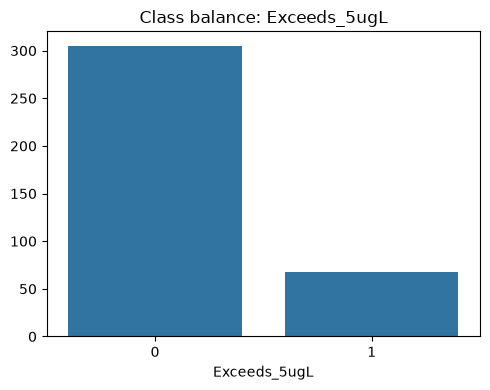

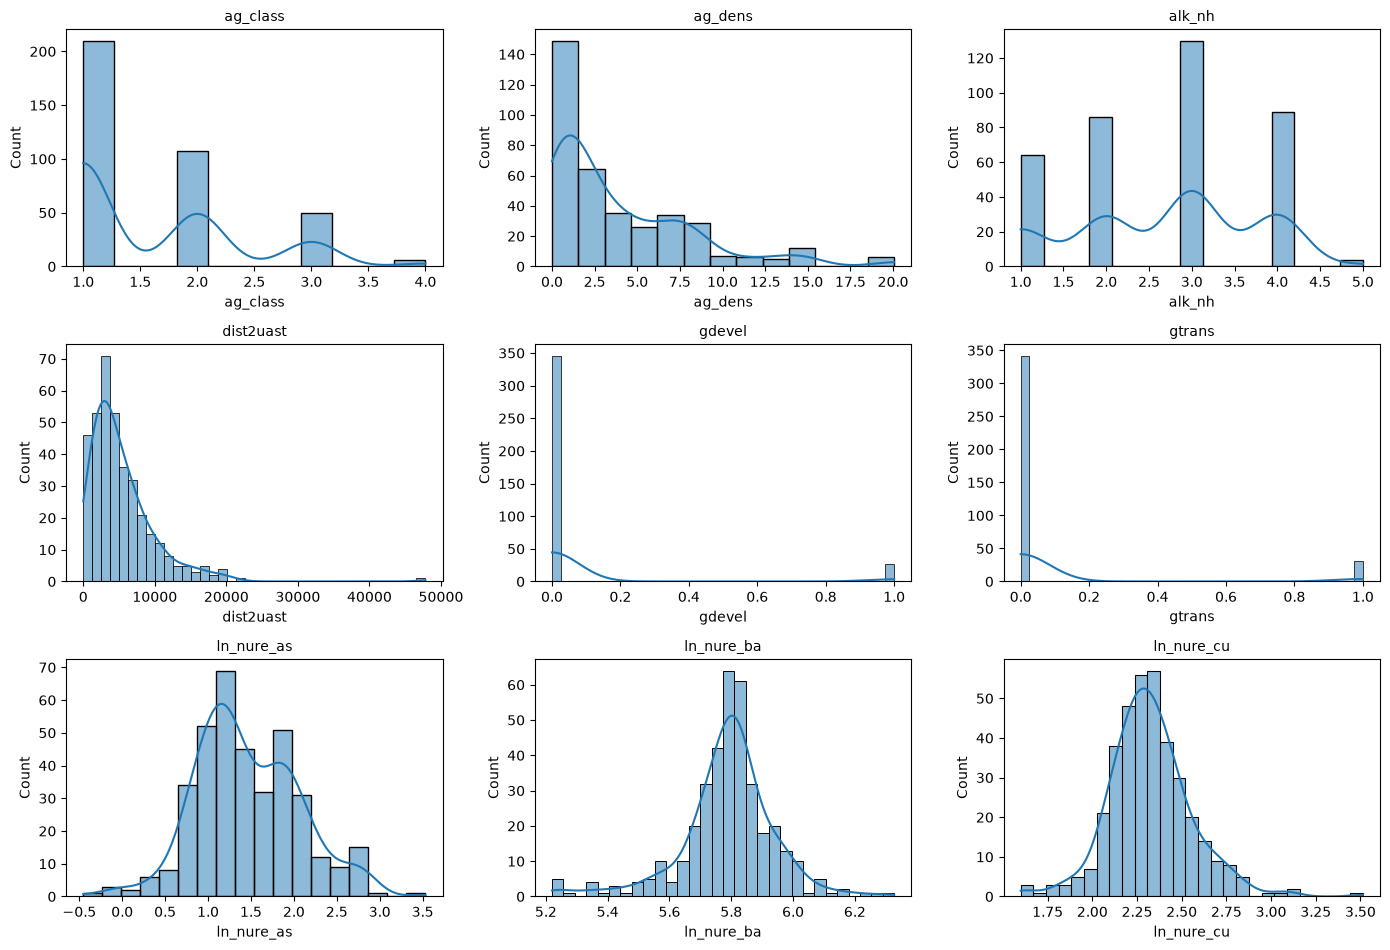

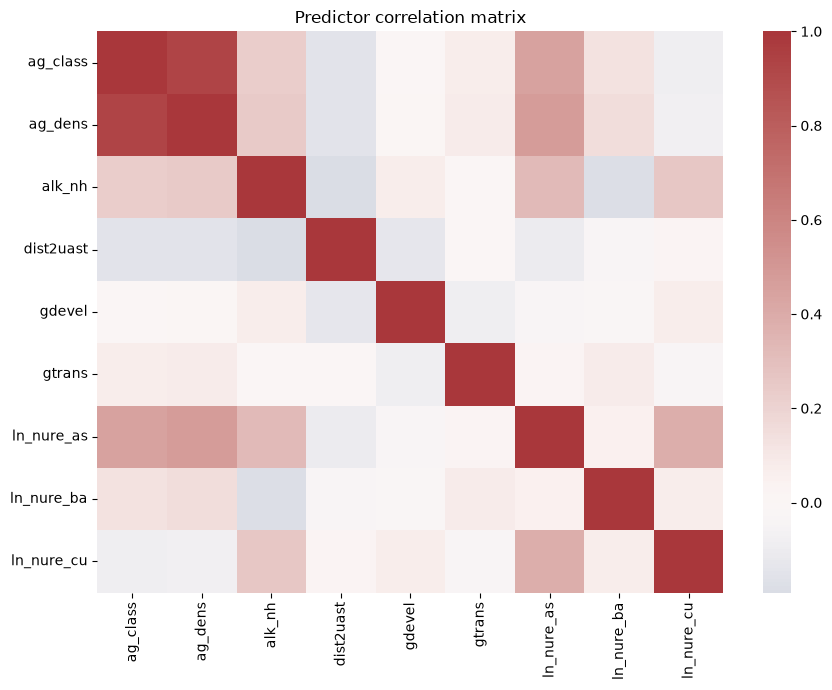

In [23]:
viz = EDAVisualizer(df, target_col=dataset.target_col)

numeric_preds_for_plots = [c for c in dataset.predictors_ if df[c].dtype.kind in "if"]  # only numeric predictors; County and WELLCLAS are text, not plotted here

viz.class_balance()                                  # how many wells above versus below the threshold
viz.numeric_distributions(numeric_preds_for_plots)    # the shape of each numeric predictor's values
viz.correlation_heatmap(numeric_preds_for_plots)       # how strongly predictors relate to each other

**What this shows:**

**Class Balance:** about 82 percent of wells fall below the 5 µg/L
threshold, and about 18 percent exceed it. This confirms the class
imbalance referenced later in Project Planning, and is the direct
reason PR-AUC was chosen as the primary evaluation metric there rather
than plain accuracy: a model could score about 82 percent accuracy just
by guessing "below threshold" every time, without having learned
anything real.

**Distributions:** several predictors are visibly right-skewed rather
than bell-curve shaped, matching what the Data Quality Assessment section
already found. `devm17_per`, `popd00mean`, and several of the `ln_nure_*`
geochemistry columns are among the predictors flagged there with
statistical outliers, and that skew is exactly why the Statistical
Screener in section 10 routes most continuous predictors to Mann-Whitney U
rather than Welch's t-test; a bell-curve-based test would be the wrong
tool for data shaped like this.

**Correlation Matrix:** the strongest colors on this heatmap lines up
with the highest VIF scores from section 10, `ag_dens` and `ag_class` in
particular (VIF of 13.05 and 9.96, the two highest in the whole dataset),
both land-use predictors that are plausibly measuring overlapping
information. A strong color between two predictors here is the same
signal as a high VIF score there, just visualized instead of tabulated.

## 9. Mapping the Results (`BivariateMapVisualizer`)

Two things worth knowing before looking at the maps themselves.

### The county map shows two variables at once, not one

A map colored by a single number (a choropleth map) would treat a county
with a high exceedance rate from only 2 tested wells the same as a county
with the same rate from 40 tested wells, even though those are very
different situations to trust. To avoid that, this map combines two
variables at once: the exceedance rate, and the number of wells tested in
that county. This kind of two-variable map is called bivariate. Each
county gets a color from a 3 by 3 grid instead of a single color scale,
so both the rate and how much data supports it are visible together.

The color grid itself is not something newly invented for this notebook.
It is the exact amber color palette (`bi_pal_bladder`) from the original
NH Paradox Shiny app's code. That palette was built for bladder cancer
specifically, and arsenic is the established bladder cancer risk factor
this whole project is about, so reusing that exact palette, rather than
creating a new one, keeps the color meaning consistent with the capstone.

### The dot map does not show real well locations

This dataset only records a well's county, not its exact coordinates, so
there is no real location to plot for any single well. Each dot on the
second map is placed at a random position somewhere inside its county's
boundary. This is a standard, accepted technique for showing data that
has been deliberately generalized to protect location privacy, sometimes
called a dot-density map. It is a visual stand-in for "this many wells
exist somewhere in this county," not a claim about where any specific
well actually is. Colors reuse the original app's existing color scheme
(gray for Brain Cancer, amber for Bladder Cancer), since amber already
means "relevant to bladder cancer" in that color scheme.

### Why county names need to be cleaned before matching

This dataset and the Census Bureau's map data do not spell county names
the same way. For example, Census TIGER (the Census Bureau's map data)
spells one county "Coös County," with an accent mark over the o, while
this dataset spells it differently. Comparing the raw names directly
would fail to match that county, and any others with similar formatting
differences, without raising any error at all. The map would simply show
those counties as having no data, which looks like a correctly finished
result rather than a quiet mistake.

To avoid this, every county name is cleaned and lowercased before being
compared: accent marks are removed, extra words like "county" are
stripped, and capitalization is ignored. Comparing the data this way,
rather than comparing the original raw text, is what makes the two
sources line up correctly.

In [24]:
class BivariateMapVisualizer:
    """
    Draws two maps of New Hampshire: a county-level choropleth and a
    dot-density well map. Both are drawn using plain matplotlib shapes
    rather than a higher-level mapping shortcut, which gives full control
    over colors, labels, and styling for both maps.
    """

    BLADDER_PALETTE = {  # the amber color grid from the original Shiny app's global.R, reused as-is
        (1, 1): "#fff8e1", (2, 1): "#ffe0a0", (3, 1): "#ffc044",
        (1, 2): "#f0a830", (2, 2): "#e08000", (3, 2): "#c85000",
        (1, 3): "#a03800", (2, 3): "#7a2800", (3, 3): "#4e1600",
    }
    DOT_COLORS = {0: "#686868", 1: "#ffa000"}  # gray = below threshold, amber = exceeds threshold (matches the app's existing color scheme)

    def __init__(self, df: pd.DataFrame, target_col: str, output_dir: Path = OUTPUT_DIR):
        if not HAS_GEO:
            raise RuntimeError("geopandas/shapely required for maps.")
        self.df = df
        self.target_col = target_col
        self.output_dir = output_dir
        self.nh_counties = self._fetch_nh_counties()  # NH county boundaries, downloaded once when this object is created

    @staticmethod
    def _fetch_nh_counties():
        """Download New Hampshire's county boundary shapes from the Census Bureau, or reuse a cached copy."""
        import zipfile
        year = 2022
        cache_zip = RAW_DIR / f"cb_{year}_us_county_500k.zip"
        if not cache_zip.exists():
            url = f"https://www2.census.gov/geo/tiger/GENZ{year}/shp/cb_{year}_us_county_500k.zip"
            resp = requests.get(url, timeout=60)
            resp.raise_for_status()
            cache_zip.write_bytes(resp.content)
        extract_dir = RAW_DIR / f"cb_{year}_us_county_500k"
        if not extract_dir.exists():
            with zipfile.ZipFile(cache_zip) as zf:
                zf.extractall(extract_dir)
        shp_files = list(extract_dir.glob("*.shp"))
        us_counties = gpd.read_file(shp_files[0])
        nh = us_counties[us_counties["STATEFP"] == "33"].copy()  # keeps only New Hampshire (state code 33) out of the full US file
        nh["County"] = nh["NAME"].apply(_clean_county_name)       # a clean, readable name for map labels
        nh["_match_key"] = nh["County"].apply(_match_key)         # a simplified name used only for matching against the well data
        return nh.to_crs(4326)[["County", "_match_key", "geometry"]].sort_values("County").reset_index(drop=True)

    @staticmethod
    def _tertile_bin(series):
        """Split a column's values into three equal-sized groups: low, medium, and high."""
        ranks = series.rank(method="average", pct=True)
        bins = pd.cut(ranks, bins=[0, 1/3, 2/3, 1.0001], labels=[1, 2, 3], include_lowest=True)
        return bins.astype(int)

    @staticmethod
    def _geometry_to_patches(geometry, **kwargs):
        """Convert one county's shape into one or more drawable shapes (a county can be made of multiple separate land pieces)."""
        import matplotlib.patches as mpatches
        geoms = list(geometry.geoms) if geometry.geom_type == "MultiPolygon" else [geometry]
        return [mpatches.Polygon(list(g.exterior.coords), closed=True, **kwargs) for g in geoms]

    def _draw_counties(self, ax, counties_gdf, color_col=None, default_color=None, **style):
        """Draw every county in counties_gdf onto the map, either with a per-county color or one shared color."""
        for _, row in counties_gdf.iterrows():
            facecolor = row[color_col] if color_col else default_color
            for patch in self._geometry_to_patches(row.geometry, facecolor=facecolor, **style):
                ax.add_patch(patch)

    @staticmethod
    def _set_extent(ax, counties_gdf):
        """Zoom and frame the map so all of New Hampshire fits neatly in view, with a small margin around the edges."""
        minx, miny, maxx, maxy = counties_gdf.total_bounds
        pad_x, pad_y = (maxx - minx) * 0.05, (maxy - miny) * 0.05
        ax.set_xlim(minx - pad_x, maxx + pad_x)
        ax.set_ylim(miny - pad_y, maxy + pad_y)
        ax.set_aspect("equal")

    @staticmethod
    def _random_points_in_polygon(polygon, n, rng):
        """Pick n random points that fall inside a given county's shape, for the dot-density map."""
        minx, miny, maxx, maxy = polygon.bounds
        points, attempts, max_attempts = [], 0, max(n * 200, 1000)
        while len(points) < n and attempts < max_attempts:
            attempts += 1
            candidate = Point(rng.uniform(minx, maxx), rng.uniform(miny, maxy))
            if polygon.contains(candidate):
                points.append(candidate)
        if len(points) < n:
            points += [polygon.centroid] * (n - len(points))  # fills in any shortfall at the county's center point, for very small or oddly shaped counties
        return points

    def _county_stats(self):
        """Calculate the exceedance rate and number of wells tested for each county."""
        df_map = self.df.copy()
        df_map["_match_key"] = df_map["County"].apply(_match_key)
        unmatched = set(df_map["_match_key"].dropna()) - set(self.nh_counties["_match_key"])
        if unmatched:
            logger.warning("Unmatched county values after normalization: %s", unmatched)
        stats = df_map.groupby("_match_key")[self.target_col].agg(exceedance_rate="mean", n_wells="count").reset_index()
        # Converts to plain number types, since the mapping and plotting
        # code below expects ordinary floats rather than pandas' nullable
        # number type.
        stats["exceedance_rate"] = stats["exceedance_rate"].astype("float64")
        stats["n_wells"] = stats["n_wells"].astype("float64")
        return df_map, stats

    def choropleth(self):
        """Draw the county-level map, colored by exceedance rate and number of wells tested together."""
        df_map, county_stats = self._county_stats()
        merged = self.nh_counties.merge(county_stats, on="_match_key", how="left")
        has_data = merged["exceedance_rate"].notna() & merged["n_wells"].notna()
        valid, missing = merged[has_data].copy(), merged[~has_data].copy()  # counties with usable data, versus counties with none

        valid["_x_bin"] = self._tertile_bin(valid["exceedance_rate"]).values  # low/medium/high group for exceedance rate
        valid["_y_bin"] = self._tertile_bin(valid["n_wells"]).values          # low/medium/high group for number of wells tested
        valid["_color"] = [self.BLADDER_PALETTE[(x, y)] for x, y in zip(valid["_x_bin"], valid["_y_bin"])]  # looks up the matching color for each county's pair of groups

        fig = plt.figure(figsize=(10, 7.5), facecolor=MAP_BG)
        ax = fig.add_axes([0.03, 0.05, 0.66, 0.88])
        ax.set_facecolor(MAP_BG)
        if not missing.empty:
            self._draw_counties(ax, missing, default_color="#e4e1d6", edgecolor="white", linewidth=1.2, hatch="///")  # counties with no data, shown with a hatched pattern
        self._draw_counties(ax, valid, color_col="_color", edgecolor="white", linewidth=1.2)
        self._set_extent(ax, self.nh_counties)

        for _, row in pd.concat([valid, missing]).iterrows():  # labels every county, whether it has data or not
            c = row.geometry.centroid
            ax.annotate(row["County"], xy=(c.x, c.y), ha="center", va="center", fontsize=9,
                        fontweight="bold", color="#2b2b2b", path_effects=LABEL_HALO)

        ax.set_title(f"Arsenic exceedance ({self.target_col}) x testing coverage, by NH county",
                     fontsize=13, fontweight="bold", color="#2b2b2b", pad=14)
        ax.set_axis_off()

        # Draws the 3-by-3 color key as its own small grid, so the legend
        # shows both variables at once instead of a single color scale.
        legend_ax = fig.add_axes([0.74, 0.38, 0.20, 0.20])
        legend_ax.set_facecolor(MAP_BG)
        for (xb, yb), color in self.BLADDER_PALETTE.items():
            legend_ax.add_patch(plt.Rectangle((xb - 1, yb - 1), 1, 1, facecolor=color, edgecolor=MAP_BG, linewidth=2))
        legend_ax.set_xlim(0, 3); legend_ax.set_ylim(0, 3)
        legend_ax.set_xticks([]); legend_ax.set_yticks([])
        legend_ax.set_xlabel("exceedance rate ->", fontsize=9)
        legend_ax.set_ylabel("wells tested ->", fontsize=9)
        for spine in legend_ax.spines.values():
            spine.set_visible(False)

        fig.savefig(self.output_dir / "05_county_choropleth.png", dpi=150, facecolor=MAP_BG)
        plt.show()

    def dot_density(self, seed: int = 42):
        """Draw the dot-density map: one dot per well, placed randomly within its county, colored by target class."""
        df_map, _ = self._county_stats()
        rng = np.random.default_rng(seed)  # fixed seed, so the dot positions are the same every time this runs
        fig, ax = plt.subplots(figsize=(8.5, 7.5), facecolor=MAP_BG)
        ax.set_facecolor(MAP_BG)
        self._draw_counties(ax, self.nh_counties, default_color="#eeece2", edgecolor="#8a8775", linewidth=0.9)
        self._set_extent(ax, self.nh_counties)

        geom_lookup = dict(zip(self.nh_counties["_match_key"], self.nh_counties.geometry))
        label_lookup = dict(zip(self.nh_counties["_match_key"], self.nh_counties["County"]))
        for match_key, group in df_map.dropna(subset=[self.target_col]).groupby("_match_key"):
            polygon = geom_lookup.get(match_key)
            if polygon is None:
                continue
            pts = self._random_points_in_polygon(polygon, len(group), rng)  # one random point per well in this county
            xs, ys = [p.x for p in pts], [p.y for p in pts]
            point_colors = [self.DOT_COLORS.get(int(v), "#999999") for v in group[self.target_col].values]
            ax.scatter(xs, ys, c=point_colors, s=26, alpha=0.85, edgecolor="white", linewidth=0.6, zorder=3)
            c = polygon.centroid
            ax.annotate(label_lookup[match_key], xy=(c.x, c.y), ha="center", va="center",
                        fontsize=8, color="#555", path_effects=LABEL_HALO, zorder=4)

        handles = [
            plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=self.DOT_COLORS[0], markersize=9, label="Below threshold"),
            plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=self.DOT_COLORS[1], markersize=9, label="Exceeds threshold"),
        ]
        legend = ax.legend(handles=handles, loc="lower left", frameon=True, fontsize=9)
        legend.get_frame().set_facecolor(MAP_BG)
        ax.set_title("Approximate well locations by county\n(randomly placed within county boundary --\nexact coordinates are suppressed in the source data)",
                     fontsize=11, fontweight="bold", color="#2b2b2b")
        ax.set_axis_off()
        fig.tight_layout()
        fig.savefig(self.output_dir / "06_well_dot_density_map.png", dpi=150, facecolor=MAP_BG)
        plt.show()

print("BivariateMapVisualizer defined.")

BivariateMapVisualizer defined.


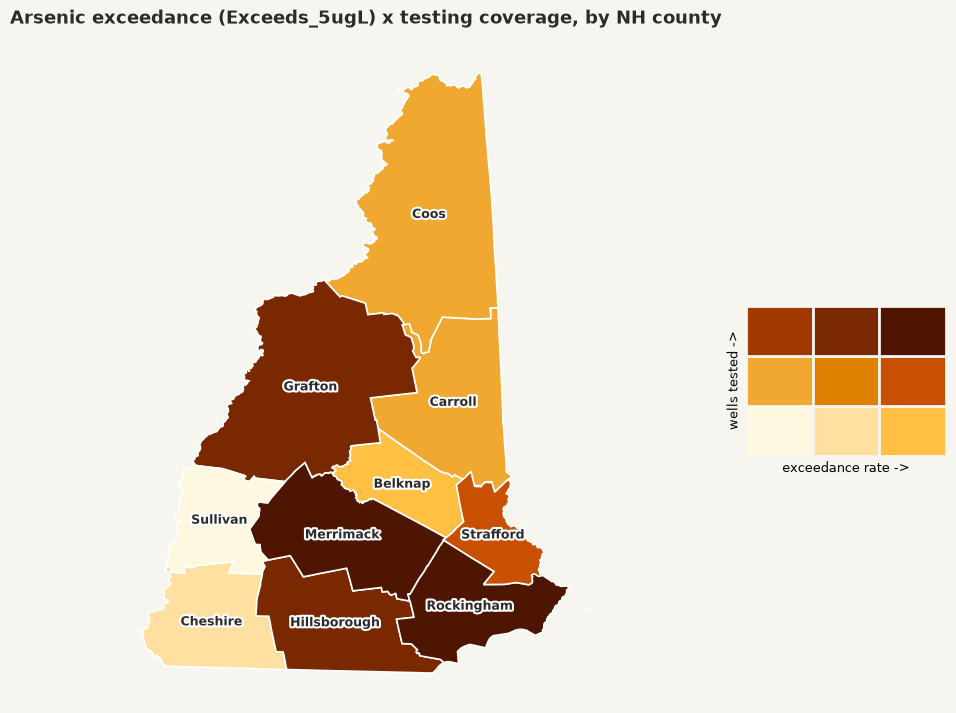

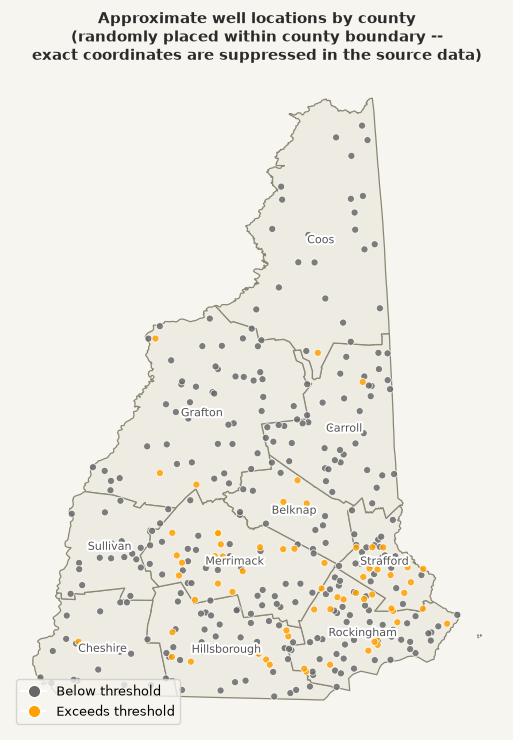

In [25]:
if HAS_GEO:
    mapper = BivariateMapVisualizer(df, target_col=dataset.target_col)  # downloads the NH county boundaries once, here
    mapper.choropleth()    # the two-variable county map: exceedance rate and wells tested
    mapper.dot_density()   # the approximate well-location map, described above
else:
    print("[skipped] geopandas/shapely not available. Install them to render the two maps (see requirements.txt).")

**What this shows**

**Choropleth map.** Each county's color combines its exceedance rate with how many wells were tested there. Both are ranked into thirds across the ten counties, so a darker color means a county ranks higher, not that its rate is high in absolute terms.

- **Merrimack (33%, 51 wells) and Rockingham (26%, 66 wells)** are the darkest: a high rate backed by a lot of testing, which makes them the most trustworthy high-exposure signal on the map.
- **Strafford** has the highest rate in the state, 41% (16 of 39 wells), with a middle amount of testing.
- **Belknap** (25%) also ranks high, but only 16 wells were tested there, so it could be chance.
- **Hillsborough (18%, 45 wells) and Grafton (6%, 52 wells)** are one shade lighter: a middle-ranked rate with a lot of testing. Hillsborough sits right at the state rate of 18%, and Grafton's rate is actually low. They look dark because many wells were tested there, not because many were contaminated.
- **Sullivan** (0 of 19 wells) is the palest: a low rate with little testing.
- No county shows the hatched "no data" pattern. All ten counties have usable data.

**Dot density map.** The amber "exceeds threshold" dots concentrate in the south-east. Merrimack (17), Rockingham (17) and Strafford (16) hold 50 of the 68 contaminated wells between them. Hillsborough has 8, Belknap 4 and Grafton 3, and each remaining county has one or none. The northern counties (Coos, Grafton, Carroll) are overwhelmingly gray. Each dot's exact position within its county is random, so a dot near a county border should not be read as evidence about that specific location. Only the overall clustering across the state is meaningful here.

# Part 3: Analytical Pipeline

## 10. Advanced Statistical Exploration

A plain correlation table treats every predictor the same way, which does
not fit this dataset well. It mixes continuous geochemistry measurements
(several of them clearly skewed, not evenly spread around a middle value,
as the skew and kurtosis columns above already showed) with sparse yes/no
bedrock geology flags, some of them true for only a single well. Using one
statistical test on every column either wastes information or breaks that
test's assumptions outright. `StatisticalScreener` picks a different test
for each predictor, following the logic below.

### Continuous predictor versus binary target

1. Check whether each target group (wells below the threshold, and wells
   above it) follows a roughly bell-curve shaped distribution. This check
   is called the Shapiro-Wilk test.
2. If **both** groups look close enough to bell-curve shaped, use
   **Welch's t-test**, which compares the two groups' averages without
   assuming they have the same amount of spread. This is a safer default
   than the classic version of this test (called Student's t-test), which
   does assume equal spread, and it costs nothing extra to use instead.
3. Otherwise, use **Mann-Whitney U**, a test that compares two groups by
   their rank order rather than their raw averages, so it does not depend
   on a bell-curve shape at all. This is the test that actually fires for
   most predictors in this dataset, given how skewed several of the
   geochemistry columns already turned out to be.
4. Either way, also report **point-biserial r**, a single number showing
   both the direction and the strength of the relationship between the
   predictor and the target, independent of which test above was used.

### Binary or categorical predictor versus binary target

1. Build a simple grid, called a contingency table, counting how often
   each combination of predictor value and target value occurs, and
   calculate what those counts would look like if there were no
   relationship at all between the two.
2. If every one of those "no relationship" counts is at least 5 (the
   standard rule of thumb for this to be reliable), use the **chi-square
   test of independence**, which checks whether the real counts are
   different enough from the "no relationship" counts to matter.
3. If the grid is a simple two-by-two table and that count drops below 5,
   use **Fisher's exact test** instead. This calculates the exact
   probability directly, rather than relying on a formula that only
   becomes accurate with larger samples. This matters here: several
   bedrock geology flags are true for only a single well.
4. Larger tables, with more than two categories on either side, that still
   have a small expected count get a chi-square result anyway, with a
   clear note attached, rather than silently treating the result as fully
   reliable. The exact version of this test does not extend cleanly beyond
   a two-by-two table in the library this notebook uses.
5. Either way, also report **Cramer's V**, a single number between 0 and 1
   showing how strong the relationship is, which can be compared across
   tables of different sizes.

### Correcting for running many tests at once

Running around 45 tests at the usual 5 percent cutoff means roughly 2
"significant" results should be expected from pure chance alone, even if
nothing real is happening in the data at all. Every p-value collected here
goes through the Benjamini-Hochberg correction described earlier in this
notebook, checked by hand against a worked example with a known answer,
before anything is called significant.

### The formulas behind each test

Let group 1 be the wells above the threshold and group 0 the wells below it, with $n_1$ and $n_0$ wells.

**Checking for a bell curve: Shapiro-Wilk.**

$$W=\frac{\Big(\sum_{i=1}^{n} a_i\,x_{(i)}\Big)^2}{\sum_{i=1}^{n}(x_i-\bar x)^2}$$

$x_{(i)}$ are the values in increasing order and $a_i$ are fixed constants derived from the normal distribution. $W$ is close to 1 for bell-shaped data, and a small p-value means the data are not bell-shaped.

**Welch's t-test** (both groups look bell-shaped):

$$t=\frac{\bar x_1-\bar x_0}{\sqrt{\dfrac{s_1^2}{n_1}+\dfrac{s_0^2}{n_0}}},\qquad \nu\approx\frac{\Big(\dfrac{s_1^2}{n_1}+\dfrac{s_0^2}{n_0}\Big)^2}{\dfrac{(s_1^2/n_1)^2}{n_1-1}+\dfrac{(s_0^2/n_0)^2}{n_0-1}}$$

It compares the two group means without assuming equal spread. $\nu$ is the degrees of freedom (the Welch-Satterthwaite formula).

**Mann-Whitney U** (at least one group is skewed):

$$U_1=R_1-\frac{n_1(n_1+1)}{2}$$

$R_1$ is the sum of group 1's ranks when all wells are ranked together from smallest to largest. If both groups come from the same distribution, $U_1$ is centered at $n_1n_0/2$ with variance $n_1n_0(n_1+n_0+1)/12$ (when there are no ties). Because it uses ranks, extreme values cannot dominate.

**Point-biserial correlation** (the effect size for either of those tests):

$$r_{pb}=\frac{\bar x_1-\bar x_0}{s_n}\sqrt{\frac{n_1n_0}{n^2}}$$

$s_n$ is the standard deviation of all wells (dividing by $n$). It equals the ordinary correlation between the column and the 0/1 outcome, and runs from $-1$ to $1$.

**Chi-square test of independence** (a categorical or 0/1 predictor), built from a table of counts $O_{ij}$:

$$\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad E_{ij}=\frac{R_i\,C_j}{n},\qquad \text{df}=(r-1)(c-1)$$

$E_{ij}$ is the count expected if the predictor and the outcome were unrelated, where $R_i$ and $C_j$ are the row and column totals. For a 2 by 2 table the software applies the Yates continuity correction, replacing $(O-E)^2$ with $(|O-E|-0.5)^2$, which slightly lowers $\chi^2$.

**Fisher's exact test** (a 2 by 2 table with a small expected count). For a table with counts $a,b,c,d$ and $n=a+b+c+d$, the probability of exactly that table, with all the totals held fixed, is

$$P=\frac{\binom{a+b}{a}\binom{c+d}{c}}{\binom{n}{a+c}}$$

The p-value adds up $P$ for every table that is no more likely than the observed one. No approximation is involved, which is why it suits the rare geology flags.

**Cramér's V** (the effect size for the chi-square and Fisher results):

$$V=\sqrt{\frac{\chi^2}{n\,\big(\min(r,c)-1\big)}}$$

It runs from 0 (unrelated) to 1 (perfectly related), and can be compared across tables of different sizes.

**Benjamini-Hochberg correction.** With $m$ tests, sort the p-values $p_{(1)}\le\dots\le p_{(m)}$. Find the largest $k$ with

$$p_{(k)}\le\frac{k}{m}\,q$$

where $q=0.05$ is the false discovery rate you accept, and call the first $k$ tests significant. The adjusted p-values are $\tilde p_{(i)}=\min_{j\ge i}\dfrac{m}{j}\,p_{(j)}$. This is why a small raw p-value alone is not enough after about 45 tests.

**Variance inflation factor.** For predictor $j$, regress it on all the other predictors and take that fit's $R_j^2$:

$$\mathrm{VIF}_j=\frac{1}{1-R_j^2}$$

A VIF of 1 means the predictor is unrelated to the others, 5 is worth a second look, and 10 or more means it is largely a combination of the others.

In [26]:
class StatisticalScreener:
    """
    Picks the right statistical test for each predictor, instead of using
    one test on everything. See the markdown above this cell for the full
    explanation of which test gets used when, and why.
    """

    def __init__(self, df: pd.DataFrame, target_col: str, fdr_alpha: float = 0.05):
        self.df = df
        self.target_col = target_col
        self.fdr_alpha = fdr_alpha  # the significance cutoff, adjusted later for running many tests at once
        self.results_ = None

    def _is_binary_like(self, col: str) -> bool:
        """True if a column only ever holds two different values (counts as categorical, not continuous)."""
        return self.df[col].dropna().nunique() <= 2

    def _screen_continuous(self, col: str):
        """Test whether a continuous column's values differ between the two target groups."""
        sub = self.df[[col, self.target_col]].dropna()
        g0 = sub.loc[sub[self.target_col] == 0, col]  # this predictor's values, wells below the threshold
        g1 = sub.loc[sub[self.target_col] == 1, col]  # this predictor's values, wells above the threshold
        if len(g0) < 3 or len(g1) < 3:
            return None  # not enough data in one of the groups to test reliably

        def _normal_enough(g):
            if len(g) > 5000:
                return True  # the normality test below becomes unreliable at very large sample sizes, and is not needed at this size anyway
            try:
                _, p = scipy_stats.shapiro(g)  # tests whether this group looks roughly bell-curve shaped
                return p > 0.05
            except Exception:
                return False

        if _normal_enough(g0) and _normal_enough(g1):
            # Both groups look bell-curve shaped: compare their averages directly.
            stat, p = scipy_stats.ttest_ind(g0, g1, equal_var=False)
            test_used = "Welch t-test"
        else:
            # At least one group is skewed: compare by rank order instead of raw averages.
            stat, p = scipy_stats.mannwhitneyu(g0, g1, alternative="two-sided")
            test_used = "Mann-Whitney U"

        # Reported either way: one number capturing direction and strength of the relationship.
        r, _ = scipy_stats.pointbiserialr(sub[self.target_col].astype(int), sub[col])
        return {"predictor": col, "var_type": "continuous", "test": test_used,
                "statistic": round(float(stat), 4), "p_value": float(p),
                "effect_size": round(float(r), 4), "effect_size_type": "point-biserial r", "caveat": ""}

    def _screen_categorical(self, col: str):
        """Test whether a categorical or binary column is associated with the target."""
        sub = self.df[[col, self.target_col]].dropna()
        table = pd.crosstab(sub[col], sub[self.target_col])  # counts for every combination of predictor value and target value
        if table.shape[0] < 2 or table.shape[1] < 2:
            return None  # not enough variety in one of the two columns to test

        chi2, p, dof, expected = scipy_stats.chi2_contingency(table)  # "expected" is what the counts would look like with no real relationship
        min_expected = expected.min()
        caveat, stat, test_used = "", chi2, "Chi-square"

        if min_expected < 5:
            if table.shape == (2, 2):
                # Small expected counts in a simple two-by-two table: use the exact
                # calculation instead of the chi-square approximation.
                _, p = scipy_stats.fisher_exact(table.values)
                test_used, stat = "Fisher's exact", None
            else:
                # Larger table with small expected counts: no clean exact alternative
                # exists here, so the chi-square result is kept but flagged.
                caveat = f"min expected cell count = {min_expected:.1f} (below 5, interpret cautiously)"

        n = table.values.sum()
        cramers_v = float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))  # strength of the association, on a 0 to 1 scale
        return {"predictor": col, "var_type": "categorical", "test": test_used,
                "statistic": round(float(stat), 4) if stat is not None else None,
                "p_value": float(p), "effect_size": round(cramers_v, 4),
                "effect_size_type": "Cramer's V", "caveat": caveat}

    def run(self, predictors: list) -> pd.DataFrame:
        """Test every predictor against the target, then correct for running many tests at once."""
        rows = []
        for col in predictors:
            is_numeric = pd.api.types.is_numeric_dtype(self.df[col])
            result = self._screen_continuous(col) if (is_numeric and not self._is_binary_like(col)) else self._screen_categorical(col)
            if result is not None:
                rows.append(result)
        results = pd.DataFrame(rows)
        sig, adj = _benjamini_hochberg(results["p_value"].values, alpha=self.fdr_alpha)
        results["p_value_fdr"] = adj                    # the adjusted p-value, after accounting for the number of tests run
        results["significant_after_fdr"] = sig          # whether the result still counts as significant after that adjustment
        self.results_ = results.sort_values("p_value").reset_index(drop=True)
        return self.results_

    @staticmethod
    def compute_vif(df: pd.DataFrame, columns: list) -> pd.DataFrame:
        """
        Checks whether predictors are measuring overlapping information
        (for example, several geochemistry columns drawn from the same
        underlying survey). For each column, this tries to predict it
        using every other column, and measures how well that works, a
        score called the Variance Inflation Factor (VIF). A VIF above 5
        is generally worth a second look; above 10 is a stronger warning
        sign. This matters for explaining a linear model's coefficients
        later, though it does not affect a tree-based model's accuracy.
        """
        sub = df[columns].dropna()
        rows = []
        for target in columns:
            others = [c for c in columns if c != target]      # every other column, used to try to predict this one
            y = sub[target].to_numpy(dtype=float)
            X = sub[others].to_numpy(dtype=float)
            X_design = np.column_stack([np.ones(len(X)), X])  # adds a constant column, required for the regression below

            coefs, _, _, _ = np.linalg.lstsq(X_design, y, rcond=None)  # finds the best-fit prediction of y from the other columns
            y_hat = X_design @ coefs                                   # the resulting predicted values
            ss_res = np.sum((y - y_hat) ** 2)                          # how much error is left over
            ss_tot = np.sum((y - y.mean()) ** 2)                       # how much this column varies in total
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0            # the fraction of that variation explained by the other columns
            vif = 1 / (1 - r2) if r2 < 1 else np.inf                   # grows large as the other columns explain this one almost completely
            rows.append({"predictor": target, "r_squared_vs_others": round(r2, 4), "VIF": round(vif, 2)})
        return pd.DataFrame(rows).sort_values("VIF", ascending=False).reset_index(drop=True)

print("StatisticalScreener defined.")

StatisticalScreener defined.


### Run the screener

In [27]:
if HAS_SCIPY:
    screener = StatisticalScreener(df, target_col=dataset.target_col)
    screening_results = screener.run(dataset.predictors_)  # tests every predictor, picking the right test for each one

    screening_results.to_csv(OUTPUT_DIR / "statistical_screening.csv", index=False)  # saves the full table for the record

    with pd.option_context("display.width", 160):  # prevents the wide table from getting cut off in the printed output
        print(screening_results.to_string(index=False))
else:
    print("[skipped] scipy not available.")  # this section needs scipy; everything else in the notebook still runs without it

 predictor    var_type           test  statistic      p_value  effect_size effect_size_type                                                        caveat  p_value_fdr  significant_after_fdr
    County categorical     Chi-square    46.4552 4.956530e-07       0.3529       Cramer's V min expected cell count = 2.9 (below 5, interpret cautiously)     0.000022                   True
ln_nure_fe  continuous Mann-Whitney U 13613.5000 1.638303e-05      -0.1942 point-biserial r                                                                   0.000360                   True
   ag_dens  continuous Mann-Whitney U  7094.5000 4.627887e-05       0.1149 point-biserial r                                                                   0.000679                   True
 ratiopbcu  continuous Mann-Whitney U  7472.0000 3.539223e-04       0.1627 point-biserial r                                                                   0.003893                   True
   nure_ph  continuous Mann-Whitney U 13113.0000 5

**Reading this table:** the rows are sorted by raw p-value, but the
column that actually matters after running about 45 tests is
`significant_after_fdr`. A predictor can have a small raw p-value and
still fail to survive the multiple-testing correction once that penalty
is applied, so the raw p-value alone is not the final answer.

The `test` column shows which test was actually used for each predictor.
Seeing a mix of `Mann-Whitney U`, `Welch t-test`, `Chi-square`, and
`Fisher's exact` across the table is expected, and is a good sign, not a
bug. It means the screener is genuinely responding to each predictor's
real distribution, rather than applying the same test to everything by
default.

### Checking for Overlapping Predictors (VIF)

Several of the NURE geochemistry predictors come from the same
underlying survey, so it is worth checking whether some of them are
really just measuring the same underlying thing in slightly different
ways. This situation is called multicollinearity.

Why it matters depends on which kind of model gets used later:

- For a model like random forest or gradient boosting, overlapping predictors do not hurt how accurate the
  model's predictions are.
- For a logistic regression model, overlapping predictors can make its
  individual coefficients unreliable. A coefficient is the number a
  linear model assigns to each predictor to describe how much it matters
  and in which direction. If two predictors are highly overlapping, the
  model can split credit between them in a way that makes each one look
  less important than it really is, even though the two of them together
  are. So a claim like "this predictor matters more than that one,"
  drawn from a logistic regression's coefficients, is not trustworthy
  when VIF is high.

In [28]:
# Only numeric, non-binary columns with at least 10 real values are checked,
# since VIF is a measure built for continuous predictors, not categories.
numeric_predictors = [c for c in dataset.predictors_ if df[c].dtype.kind in "if" and df[c].notna().sum() > 10]

vif_table = StatisticalScreener.compute_vif(df, numeric_predictors)
vif_table.to_csv(OUTPUT_DIR / "vif_table.csv", index=False)  # saves the full table for the record
print(vif_table.to_string(index=False))
print()

high_vif = vif_table[vif_table["VIF"] > 5]  # 5 is the common "worth a second look" threshold, see the markdown above
if not high_vif.empty:
    print(f"{len(high_vif)} predictor(s) with VIF above 5. Consider dropping or combining these before using a logistic regression model:")
    print(high_vif["predictor"].tolist())
else:
    print("No predictor exceeds a VIF of 5. Overlapping predictors are not a major concern for a linear model here.")

 predictor  r_squared_vs_others   VIF
   ag_dens               0.9234 13.05
  ag_class               0.8996  9.96
ln_nure_cu               0.8408  6.28
 ratiopbcu               0.8084  5.22
       PRN               0.7839  4.63
rechbfi94f               0.7584  4.14
rain7100mm               0.7535  4.06
ln_nure_as               0.7347  3.77
   CGN_SOB               0.7270  3.66
ln_nure_fe               0.7115  3.47
 nure_cond               0.6840  3.16
popd00mean               0.6742  3.07
ln_nure_ba               0.6666  3.00
ln_nure_sr               0.6418  2.79
devm17_per               0.6237  2.66
   PRN_SRL               0.6189  2.62
   CGN_SOE               0.5970  2.48
    PRN_SP               0.5933  2.46
    alk_nh               0.5713  2.33
 marinelim               0.5659  2.30
   nure_ph               0.5234  2.10
 yieldprob               0.5103  2.04
  CGN_SOBC               0.5036  2.01
  PGN_DC1M               0.4555  1.84
ln_nure_si               0.4383  1.78
  GON_DK2X  

## 11. Project Planning

### Prediction Problem

**Predict whether a New Hampshire bedrock well's arsenic concentration
exceeds a regulatory threshold (1, 5, or 10 µg/L), using geologic,
hydrologic, geochemical, and well-construction predictors.**

This is framed as an exposure-risk-assessment problem, not a cancer
diagnosis problem. It estimates which wells carry elevated arsenic
exposure risk, as a companion analysis to the NH Paradox capstone's
excluded environmental confounder, not a prediction of bladder cancer
itself. See the framing honesty check below for why that distinction
matters and cannot be collapsed.

### Target Variable

`Exceeds_5ugL`. **Binary**: 1 means the well exceeds the threshold, 0
means it does not. The threshold can be changed by creating the dataset
with a different value, for example `ArsenicDataset(threshold_ugl=1)` or
`ArsenicDataset(threshold_ugl=10)`, to match the other two published
benchmark models. See the class-balance plot earlier in this notebook for
the real split at the default threshold.

### Primary Metric (Predefined) and Secondary Metrics

**The primary metric is fixed before any model is run, from the goal set in section 2.**

| Goal (`USER_GOAL`) | Primary metric | Why |
|---|---|---|
| `rank_for_testing` (the default) | **PR-AUC** (average precision) | the use is deciding which wells get tested first, which is a ranking problem on a rare outcome |
| `balanced_decision` | **MCC** | the use is a yes/no call per well, where both kinds of mistake matter |

**Why PR-AUC is the default for this project.** The wells most worth finding are the roughly 18 percent above the threshold, and the practical use of a model here is to rank wells for testing. PR-AUC measures how concentrated the truly contaminated wells are at the top of that ranking. It ignores the many easy safe wells, so it cannot be inflated by them, and it needs no decision cutoff, so it is not affected by the noise of choosing one. Its no-skill value is the share of contaminated wells (about 0.18), which makes "better than guessing" easy to see. ROC-AUC, the metric this section originally named, is still reported but is not used to choose, because it is flattered by the large number of safe wells.

**Secondary metrics, reported for every model:** precision, recall, specificity, F1, MCC, balanced accuracy, ROC-AUC, Brier score, and accuracy (for reference only, since a model that always says "safe" scores about 82 percent).

**The selection rule is also fixed in advance (section 20):** the model with the highest primary metric wins. If a simpler model's score is statistically indistinguishable from the leader's (the paired bootstrap interval for their difference includes zero), the simpler model wins, because it is easier to explain and less likely to be fitting noise. Simplicity order: logistic regression, then random forest, then gradient boosting.

### Planned Modeling Approach

Two tiers, building on each other, chosen specifically because this
dataset was selected to engage with data suppression rather than avoid
it (see the Data Selection section above).

**Baseline tier:**
- A regularized logistic regression: a traditional statistical model for
  yes/no outcomes, with a built-in penalty that discourages it from
  relying too heavily on any single predictor. This is the model closest
  to what Ayotte et al. themselves used, making it the fairest direct
  comparison to their published accuracy.
- A tree ensemble (random forest or gradient boosting), which handles the
  mix of continuous and binary predictors in this dataset without
  requiring them to be rescaled first, and tends to perform well as a
  stronger baseline.

**Suppression-aware tier, the part that makes this more than a standard
classroom model:**
- A hierarchical model that pools information across small groups
  (counties, or bedrock geology categories with very few wells) instead
  of treating every group as if it had equally reliable data. Rather than
  hiding a small group's estimate outright, the way real suppression
  rules do, this approach pulls an unreliable small-group estimate toward
  the overall average, by an amount that depends on exactly how little
  data supports it. This is a more principled version of the same
  instinct behind data suppression rules, adjusting for uncertainty
  instead of simply hiding it.
- Confidence intervals built by resampling the data repeatedly (a
  technique called bootstrapping), rather than reporting a single number
  as if it were exact. At 373 wells, a prediction or a feature importance
  score without an uncertainty range attached would be overstating how
  precise this dataset actually allows a result to be.

What the statistical screening section already did directly informs this
plan: the predictors that survived the FDR correction are the ones worth
prioritizing in the logistic regression's feature set; the VIF table
flags which of those overlap with each other; the rare-flag report from
the Data Quality Assessment section flags exactly which bedrock geology
categories risk an empty cross-validation fold or an unreliable estimate,
and are the ones the hierarchical model's pooling is specifically meant
to handle. None of this is guesswork. It is what actually showed up when
the right test ran on each column, earlier in this notebook.

**Framing honesty check:** this predicts arsenic exceedance, the
exposure, not bladder cancer diagnosis directly. Individual-level cancer
case data for this population (Karagas et al., 1213 cases / 1418
controls) exists but is restricted human-subjects data, not something
this project can access.

## 12. Pipeline Plan: Adapting to the Data and the Goal

A fixed recipe can fail on a different dataset. Five-fold cross-validation breaks when one outcome has only a handful of wells, and a model with too many predictors for the number of contaminated wells gives unstable estimates. So the pipeline reads the dataset's characteristics and the user's goal, and sets its own settings before any model is built.

| Decision | Rule | Why |
|---|---|---|
| Primary metric | from `USER_GOAL` (section 2) | fixed before any model runs |
| Outer folds | `min(5, smaller_group // 5)`, at least 2 | each held-out fold should hold about 5 or more wells of the smaller group |
| Inner folds (tuning, cutoff) | `min(5, training_smaller_group // 5)`, at least 2 | the same rule, applied inside the training wells |
| Repeats | 2, or 1 when there are 2000 or more wells | repeats steady the estimates for small data, and are unnecessary for large data |
| Predictors in the inferential model | `smaller_group // 10`, taken from the 6 preferred ones that exist | about 10 wells of the smaller group per predictor |
| Warnings | very rare outcome, near-balanced classes, a small smaller group, MCC with few wells | tell the reader how far to trust the results |

Every later section reads its settings from the `plan` built here. On this dataset the standard settings fit, so nothing is reduced. The last cell applies the same rules to a deliberately tiny subset with a different goal, so the adaptation is visible.

In [29]:
INFERENCE_FEATURE_PREFERENCE = ["nure_ph", "ln_nure_as", "ln_nure_fe", "ratiopbcu", "nh_sdrift1", "rain7100mm"]   # chosen on geochemical grounds, in priority order

def plan_pipeline(y, columns, user_goal, requested_splits=5, requested_repeats=2):
    """Read the data's characteristics and the user's goal, and return the settings the rest of the pipeline will use."""
    y = np.asarray(y).astype(int)
    n, positives = len(y), int(y.sum())
    smaller = min(positives, n - positives)           # wells in the less common outcome group
    prevalence = positives / n
    notes = []

    n_splits = int(max(2, min(requested_splits, smaller // 5)))        # about 5 or more wells of the smaller group in every held-out fold
    if n_splits < requested_splits:
        notes.append(f"Only {smaller} wells are in the smaller group, so cross-validation uses {n_splits} folds instead of {requested_splits}.")
    smaller_in_training = smaller * (n_splits - 1) // n_splits
    inner_splits = int(max(2, min(5, smaller_in_training // 5)))       # the same rule, inside each training set
    if inner_splits < 5:
        notes.append(f"Tuning inside each training set uses {inner_splits} folds, because those sets hold only about {smaller_in_training} wells of the smaller group.")
    n_repeats = requested_repeats if n < 2000 else 1
    if n_repeats < requested_repeats:
        notes.append(f"With {n} wells the estimates are already steady, so one repeat is enough.")

    cap = max(1, smaller // 10)                                        # about 10 wells of the smaller group per predictor
    available = [f for f in INFERENCE_FEATURE_PREFERENCE if f in set(columns)]
    inference_features = available[:cap]
    if len(available) < len(INFERENCE_FEATURE_PREFERENCE):
        notes.append(f"{len(INFERENCE_FEATURE_PREFERENCE) - len(available)} preferred inference predictor(s) are not in this dataset and were left out.")
    if len(inference_features) < len(available):
        notes.append(f"{smaller} wells in the smaller group supports about {cap} predictor(s) in the inferential model, so the list was cut from {len(available)} to {len(inference_features)}.")

    if prevalence < 0.05:
        notes.append("The outcome is very rare (under 5 percent), so every result will be uncertain.")
    elif prevalence > 0.40:
        notes.append("The classes are close to balanced, so ROC-AUC and accuracy are also informative here (both are still reported).")
    if user_goal == "balanced_decision" and smaller < 30:
        notes.append("MCC is unstable with fewer than 30 wells in the smaller group, so expect wide intervals.")

    return {"user_goal": user_goal, "primary_metric": GOAL_TO_METRIC[user_goal], "wells": int(n), "smaller_group": int(smaller),
            "prevalence": float(prevalence), "n_splits": n_splits, "inner_splits": inner_splits, "n_repeats": int(n_repeats),
            "inference_features": inference_features, "notes": notes}

def print_plan(plan, title="Pipeline plan for this dataset and goal"):
    """Show every decision the plan made, and why."""
    print(title)
    print(f"  Goal: {plan['user_goal']}  ->  primary metric: {METRIC_NAMES[plan['primary_metric']]}")
    print(f"  Wells: {plan['wells']} ({plan['smaller_group']} in the smaller outcome group; {plan['prevalence']:.1%} above the threshold)")
    print(f"  Cross-validation: {plan['n_splits']} folds x {plan['n_repeats']} repeat(s); tuning folds inside each training set: {plan['inner_splits']}")
    print(f"  Inferential model: {len(plan['inference_features'])} predictor(s): {plan['inference_features']}")
    if plan["notes"]:
        for note in plan["notes"]:
            print("  Adaptation:", note)
    else:
        print("  No adaptation needed: the data supports the standard settings.")

print("plan_pipeline defined.")

plan_pipeline defined.


In [30]:
plan = plan_pipeline(y, X.columns, USER_GOAL)       # the settings every later section reads
print_plan(plan)
with open(OUTPUT_DIR / "pipeline_plan.json", "w") as handle:
    json.dump(plan, handle, indent=2)                # saved so the audit at the end can list it

Pipeline plan for this dataset and goal
  Goal: rank_for_testing  ->  primary metric: PR-AUC (average precision)
  Wells: 373 (68 in the smaller outcome group; 18.2% above the threshold)
  Cross-validation: 5 folds x 2 repeat(s); tuning folds inside each training set: 5
  Inferential model: 6 predictor(s): ['nure_ph', 'ln_nure_as', 'ln_nure_fe', 'ratiopbcu', 'nh_sdrift1', 'rain7100mm']
  No adaptation needed: the data supports the standard settings.


In [31]:
subset = train_test_split(np.arange(len(y)), train_size=70, stratify=y, random_state=0)[0]   # 70 wells with the same share of contaminated wells as the full data
tiny_plan = plan_pipeline(y[subset], X.columns, "balanced_decision")                          # an illustration only: a small subset, with a different goal
print_plan(tiny_plan, title="Illustration: the same rules on a stratified 70-well subset, with a different goal")

Illustration: the same rules on a stratified 70-well subset, with a different goal
  Goal: balanced_decision  ->  primary metric: Matthews correlation coefficient (MCC)
  Wells: 70 (13 in the smaller outcome group; 18.6% above the threshold)
  Cross-validation: 2 folds x 2 repeat(s); tuning folds inside each training set: 2
  Inferential model: 1 predictor(s): ['nure_ph']
  Adaptation: Only 13 wells are in the smaller group, so cross-validation uses 2 folds instead of 5.
  Adaptation: Tuning inside each training set uses 2 folds, because those sets hold only about 6 wells of the smaller group.
  Adaptation: 13 wells in the smaller group supports about 1 predictor(s) in the inferential model, so the list was cut from 6 to 1.
  Adaptation: MCC is unstable with fewer than 30 wells in the smaller group, so expect wide intervals.


## 13. Modeling Roadmap

Parts 1 and 2 loaded, validated, cleaned, and explored the data. Section 10 tested each predictor on its own, and sections 11 and 12 fixed the plan: the prediction problem, the primary metric, and the settings. Sections 13 to 25 build, tune, select, explain, and audit the models.

**The question:** given a well's geology, geochemistry, and construction, can we predict whether its arsenic exceeds the threshold (5 µg/L by default)?

**Why accuracy is not the headline.** About 82 percent of wells are below the threshold, so a model that says "safe" for every well scores about 82 percent accuracy while finding zero contaminated wells. Precision, recall, F1, MCC, PR-AUC, and calibration are the real scoreboard (defined in section 19).

**The one rule behind every design choice:** a well being scored must never have influenced anything the model learned. That includes the cleaning steps, the model's settings, and the decision cutoff, not just the model's coefficients. Every one of those is learned inside cross-validation, using training wells only.

| Section | What it does |
|---|---|
| 14. Logistic Regression | the interpretable baseline, with its math |
| 15. Random Forest | many decorrelated trees, averaged, with its math |
| 16. Gradient Boosting | small trees added one at a time, with its math |
| 17. Hyperparameter Tuning | searches each model's settings and shows how sensitive each one is |
| 18. Inferential Analysis | odds ratios with confidence intervals |
| 19. Nested Cross-Validation and Evaluation | scores all three models honestly, with uncertainty |
| 20. Model Selection | the predefined primary metric picks the model, with justification |
| 21. Advanced Visualizations | curves, trade-offs, county-level checks, partial dependence |
| 22. What We Can Conclude | turning results into conclusions |
| 23. Tie-Back to the Capstone | what this adds to the New Hampshire Paradox |
| 24. What's Next | what is planned but not yet built |
| 25. Audit | every file generated, and every requirement of the brief checked |

In [32]:
class ModelSpec:
    """
    A recipe for one model family: how to build it, which settings to tune,
    and how to read what it learned. Each model below is a small subclass.
    """

    name = "model"
    scale = False        # standardize continuous predictors before this model?
    param_grid = {}      # settings to tune, as {setting: [values to try]}

    def __init__(self, random_state=99):
        self.random_state = random_state

    def estimator(self):
        raise NotImplementedError

    def pipeline(self):
        """Cleaning step followed by the model, as one object that can be cross-validated safely."""
        return Pipeline([("prep", Preprocessor(scale=self.scale)), ("model", self.estimator())])

    def tuner(self, cv, scoring="neg_log_loss", n_jobs=-1):
        """A grid search over this model's settings, scored by cross-validation."""
        grid = {f"model__{k}": v for k, v in self.param_grid.items()}
        return GridSearchCV(self.pipeline(), grid, cv=cv, scoring=scoring, n_jobs=n_jobs, refit=True)

    @staticmethod
    def importances(fitted_pipeline):
        """How much the fitted model leans on each feature (absolute coefficient, or tree importance)."""
        model = fitted_pipeline.named_steps["model"]
        prep = fitted_pipeline.named_steps["prep"]
        names = prep.feature_names_
        if hasattr(model, "coef_"):
            values = np.abs(model.coef_[0]) * prep.output_sds_[names].to_numpy()  # effect of a 1 SD change, so 0/1 flags and continuous predictors compare fairly
        else:
            values = model.feature_importances_
        return pd.Series(values, index=names)

print("Shared building blocks defined.")

Shared building blocks defined.


## 14. Logistic Regression (`LogisticSpec`)

The interpretable baseline, and the model closest to the one Ayotte et al. used, which makes it the fairest comparison to their published accuracy.

**The model.** For a well with predictors $x$:

$$P(y=1 \mid x) = \frac{1}{1+e^{-(\beta_0+\beta^\top x)}} \qquad\Longleftrightarrow\qquad \log\frac{p}{1-p}=\beta_0+\beta^\top x$$

The log-odds are a straight-line function of the predictors, so $e^{\beta_j}$ is the factor the odds are multiplied by when predictor $j$ rises by one unit.

**How the coefficients are found.** By minimizing the log-loss of the training wells plus a penalty on large coefficients (ridge):

$$\min_{\beta}\ \ \tfrac{1}{2}\|\beta\|_2^2 \;+\; C\sum_{i}\Big[-y_i\log p_i-(1-y_i)\log(1-p_i)\Big]$$

$C$ is the setting that gets tuned in section 17. **Small $C$ means a strong penalty** and heavily shrunken coefficients. **Large $C$ means a weak penalty**, and the model chases noise.

**Why a penalty is not optional here.** There are 45 predictors (48 after preprocessing) and only about 68 contaminated wells. Without shrinkage the model would memorize which flags happened to line up with contamination. The regularization-path plot below shows exactly this: as the penalty weakens, noisy rare flags grow large coefficients.

**What this model can do that the others cannot:** it is the only one of the three that yields a clean "per-predictor effect" with a confidence interval (section 18).

In [33]:
class LogisticSpec(ModelSpec):
    """Ridge-penalized logistic regression: the interpretable baseline."""

    name = "Logistic regression"
    scale = True  # the penalty treats every coefficient alike, so predictors must share a scale
    param_grid = {"C": list(np.logspace(-3, 1, 9))}  # C is the inverse of the penalty strength

    def estimator(self):
        return LogisticRegression(max_iter=5000)

    def regularization_path(self, X, y, best_C=0.1, top_k=8):
        """Plot how every coefficient shrinks toward zero as the penalty gets stronger."""
        Cs = np.logspace(-3, 1, 25)
        Z = Preprocessor(scale=True).fit(X).transform(X)
        coefs = np.array([LogisticRegression(C=c, max_iter=5000).fit(Z, y).coef_[0] for c in Cs])
        at_best = LogisticRegression(C=best_C, max_iter=5000).fit(Z, y).coef_[0]
        top = list(np.argsort(-np.abs(at_best))[:top_k])  # the features with the largest coefficients at the marked penalty
        fig, ax = plt.subplots(figsize=(11, 5))
        for j in range(coefs.shape[1]):
            if j not in top:
                ax.plot(np.log10(Cs), coefs[:, j], color="#d9d9d9", lw=0.8)
        for color, j in zip(plt.cm.tab10(np.arange(len(top))), top):
            ax.plot(np.log10(Cs), coefs[:, j], color=color, lw=2, label=Z.columns[j])
        ax.axvline(np.log10(best_C), color="k", ls="--", alpha=0.6)
        ax.text(np.log10(best_C), ax.get_ylim()[1], f" marked value (C = {best_C:.3g})", fontsize=8, va="top")
        ax.axhline(0, color="k", lw=0.5)
        ax.set(xlabel="log10(C)   (left = strong penalty, right = weak penalty)", ylabel="Coefficient (per 1 SD of the feature)",
               title="Regularization path: coefficients shrink toward zero as the penalty grows")
        ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, title="Largest at the marked value")
        fig.tight_layout()
        plt.show()

print("LogisticSpec defined.")

LogisticSpec defined.


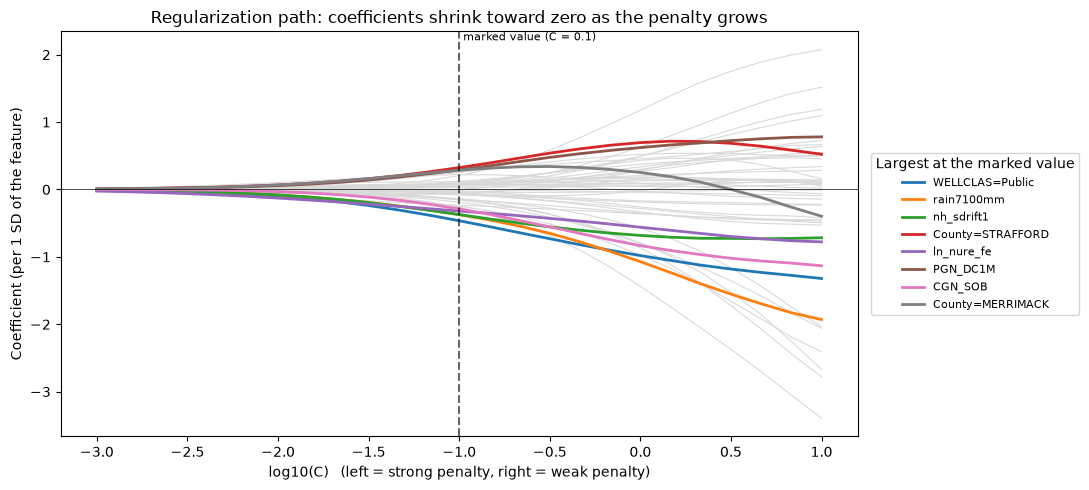

In [34]:
LogisticSpec().regularization_path(X, y)   # C = 0.1 is just an example; the tuned value is marked again in section 17

**What to look for:** every line starts at zero on the left (strong penalty) and fans out to the right as the penalty relaxes. Features whose coefficients stay clearly away from zero even under a fairly strong penalty are the ones the data genuinely supports. Gray lines are the rest. Lines that only take off at the far right, and then grow large, are the model overfitting.

## 15. Random Forest (`RandomForestSpec`)

**The idea.** One decision tree splits the wells again and again ("is pH below 6.5?") until each group is nearly pure. On its own a deep tree memorizes its training wells. A forest grows many trees and averages their votes.

**How a split is chosen.** At each step, the tree picks the predictor and cutoff that most reduces the Gini impurity of the resulting groups:

$$G = 1-\sum_k p_k^2 \;=\; 2p(1-p)\ \text{ for a yes/no outcome}$$

$G$ is 0 for a group that is all safe or all contaminated, and largest (0.5) for an even mix.

**Why averaging helps.** Two ingredients make the trees differ from each other. Each tree is grown on a bootstrap resample of the wells, and each split may only consider a random subset of predictors. If $B$ trees each have prediction variance $\sigma^2$ and pairwise correlation $\rho$, the average has variance

$$\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2$$

Adding trees shrinks the second term toward zero. The first term, $\rho\sigma^2$, is what remains, which is why the random predictor subsets matter: they lower $\rho$. The plot below shows the second term disappearing.

**A free honest score.** A bootstrap resample leaves out about 36.8 percent of wells, since $(1-1/n)^n\to e^{-1}$. Each well can therefore be scored using only the trees that never saw it. This out-of-bag score needs no separate hold-out set.

**Settings tuned in section 17:** `max_features` (how many predictors each split may consider) and `min_samples_leaf` (the smallest group a leaf may hold, where larger values give smoother predictions).

In [35]:
class RandomForestSpec(ModelSpec):
    """Random forest: many decorrelated trees, averaged."""

    name = "Random forest"
    scale = False
    param_grid = {"max_features": ["sqrt", 0.3], "min_samples_leaf": [2, 5, 10, 20]}

    def estimator(self):
        return RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=self.random_state)

    def oob_curve(self, X, y, max_trees=300, step=10):
        """Plot out-of-bag error as trees are added: the averaging effect from the variance formula."""
        Z = Preprocessor(scale=False).fit(X).transform(X)
        forest = RandomForestClassifier(n_estimators=step, warm_start=True, oob_score=True, min_samples_leaf=5,
                                        max_features="sqrt", n_jobs=1, random_state=self.random_state)
        rows = []
        for k in range(step, max_trees + 1, step):
            forest.set_params(n_estimators=k)
            forest.fit(Z, y)
            p = forest.oob_decision_function_[:, 1]  # each well scored only by trees that never saw it
            ok = ~np.isnan(p)
            rows.append((k, log_loss(y[ok], np.clip(p[ok], 1e-3, 1 - 1e-3)), roc_auc_score(y[ok], p[ok])))
        curve = pd.DataFrame(rows, columns=["trees", "log_loss", "auc"])
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].plot(curve["trees"], curve["log_loss"], color=GRAY, lw=2)
        axes[0].set(xlabel="Number of trees", ylabel="Out-of-bag log-loss", title="Error falls, then flattens, as trees are added")
        axes[1].plot(curve["trees"], curve["auc"], color=GRAY, lw=2)
        axes[1].set(xlabel="Number of trees", ylabel="Out-of-bag ROC-AUC", title="Ranking quality as trees are added")
        fig.tight_layout()
        plt.show()
        return curve

print("RandomForestSpec defined.")

RandomForestSpec defined.


C:\Users\f003cc3\AppData\Local\anaconda3\envs\nh_arsenic\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\f003cc3\AppData\Local\anaconda3\envs\nh_arsenic\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


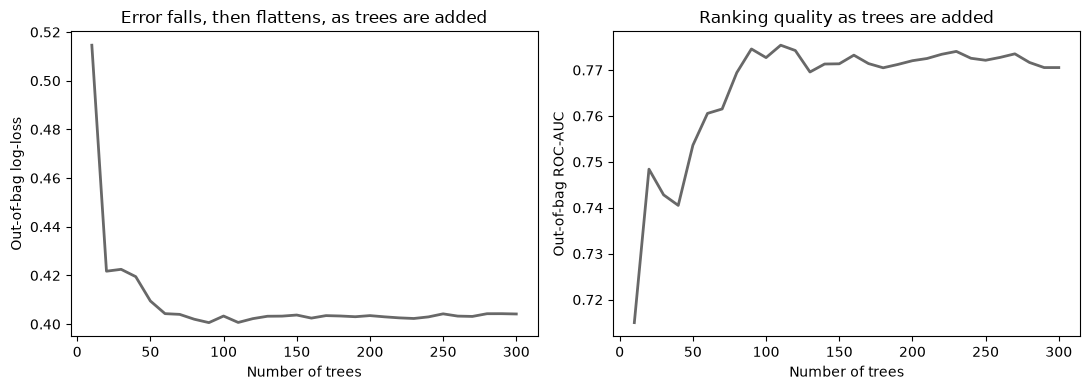

In [36]:
oob_curve = RandomForestSpec().oob_curve(X, y)   # grows the forest from 10 to 300 trees, scoring each well only with trees that never saw it

**What to look for:** the error should drop quickly over the first few dozen trees and then flatten. The flat part is the $\rho\sigma^2$ floor from the formula above: more trees stop helping, and the only way to lower the floor is to make the trees less alike. If the curve is still falling at 300 trees, the forest has not yet converged.

## 16. Gradient Boosting (`GradientBoostingSpec`)

**The idea.** A forest builds many trees independently and averages them. Boosting builds small trees one after another, and each new tree is fit to the mistakes the current model is still making.

**The math.** The model is a running sum, starting from a constant guess:

$$F_m(x)=F_{m-1}(x)+\nu\,h_m(x)$$

where $h_m$ is a small tree and $\nu$ (the learning rate) is a small step size. The predicted risk is $p=1/(1+e^{-F(x)})$. The new tree $h_m$ is fit to the negative gradient of the log-loss with respect to the current score. For a yes/no outcome that gradient has a simple form:

$$-\frac{\partial}{\partial F}\Big[-y\log p-(1-y)\log(1-p)\Big] \;=\; y-p$$

It is just the **residual**, how far the current predicted risk is from what actually happened. Each round, the trees are asked: "where is the model still wrong, and in which direction?"

**Why the settings matter.**
- `learning_rate` ($\nu$): small steps are safer but need more rounds.
- `n_estimators`: too few underfits, too many memorizes noise. The plot below shows this directly.
- `max_depth`: a depth of 1 (a single split per tree, called a stump) makes an **additive model** with no interactions between predictors, which is closely related to logistic regression. Depth 2 allows pairs of predictors to work together.
- Each round also uses only 80 percent of the wells (`subsample=0.8`), which reduces variance further.

In [37]:
class GradientBoostingSpec(ModelSpec):
    """Gradient boosting: small trees added one at a time, each correcting the last."""

    name = "Gradient boosting"
    scale = False
    param_grid = {"max_depth": [1, 2], "learning_rate": [0.03, 0.1], "n_estimators": [50, 100, 250, 500]}

    def estimator(self):
        return GradientBoostingClassifier(subsample=0.8, min_samples_leaf=5, random_state=self.random_state)

    def staged_curve(self, X, y, n_estimators=300, learning_rate=0.05, max_depth=2):
        """Plot training and validation error as boosting rounds are added: where more rounds stop helping."""
        X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.3, stratify=y, random_state=self.random_state)
        prep = Preprocessor(scale=False).fit(X_tr)
        Z_tr, Z_va = prep.transform(X_tr), prep.transform(X_va)
        gb = GradientBoostingClassifier(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
                                        subsample=0.8, min_samples_leaf=5, random_state=self.random_state).fit(Z_tr, y_tr)
        train_loss = [log_loss(y_tr, p[:, 1]) for p in gb.staged_predict_proba(Z_tr)]
        val_loss = [log_loss(y_va, p[:, 1]) for p in gb.staged_predict_proba(Z_va)]
        best = int(np.argmin(val_loss)) + 1
        fig, ax = plt.subplots(figsize=(9, 4.5))
        ax.plot(range(1, n_estimators + 1), train_loss, color=BROWN, lw=2, label="Training wells")
        ax.plot(range(1, n_estimators + 1), val_loss, color=AMBER, lw=2, label="Held-out wells")
        ax.axvline(best, color="k", ls="--", alpha=0.6)
        ax.text(best, ax.get_ylim()[1], f" best = {best} rounds", fontsize=9, va="top")
        ax.set(xlabel="Boosting rounds (trees added)", ylabel="Log-loss (lower is better)",
               title="Training error keeps falling; held-out error bottoms out, then rises")
        ax.legend()
        fig.tight_layout()
        plt.show()
        return best

print("GradientBoostingSpec defined.")

GradientBoostingSpec defined.


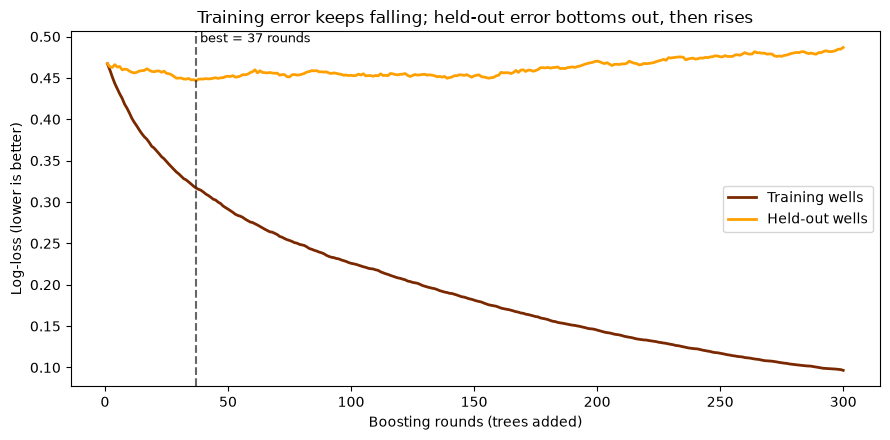

Held-out error was lowest after 37 rounds


In [38]:
best_rounds = GradientBoostingSpec().staged_curve(X, y)   # one 70/30 split, just to illustrate the shape
print("Held-out error was lowest after", best_rounds, "rounds")

**What to look for:** the training curve (brown) always keeps falling, since the model can always fit its own training wells better. The held-out curve (amber) is the honest one. It bottoms out and then rises, and the gap between the two lines is overfitting. This is one 70/30 split on a small dataset, so the exact best round is noisy. The shape is the lesson, and section 17 tunes the number of rounds properly with cross-validation.

## 17. Hyperparameter Tuning (`HyperparameterTuner`)

**Parameters versus hyperparameters.** A model's *parameters* (coefficients, tree splits) are learned from the data. Its *hyperparameters* (how strong the penalty is, how deep the trees are) are set before learning, and have to be chosen another way.

**How they are chosen.** Grid search: try every combination in a small grid, score each with 5-fold cross-validation, and keep the best.

**The score used: log-loss.**

$$\text{log-loss}=-\frac{1}{n}\sum_i\Big[y_i\log p_i+(1-y_i)\log(1-p_i)\Big]$$

It is smooth, so it separates settings better than a yes/no metric on this small dataset. It also punishes confident wrong predictions heavily, which rewards honest, well-calibrated risks.

| Model | Setting | Values tried | What it controls |
|---|---|---|---|
| Logistic regression | `C` | 0.001 to 10 (9 values, log-spaced) | inverse of the penalty strength |
| Random forest | `max_features` | square root of the predictor count, or 30 percent | how many predictors each split may consider |
| Random forest | `min_samples_leaf` | 2, 5, 10, 20 | smallest group a leaf may hold |
| Gradient boosting | `max_depth` | 1, 2 | 1 = additive (no interactions), 2 = pairs of predictors |
| Gradient boosting | `learning_rate` | 0.03, 0.1 | step size per round |
| Gradient boosting | `n_estimators` | 50, 100, 250, 500 | number of rounds |

Fixed for all runs: 200 trees in the forest, and 80 percent of wells per boosting round.

1. **These scores are for sensitivity, not performance.** Tuning on all wells and then reporting the same scores would be too optimistic. Section 19 re-runs the whole tuning procedure *inside* each cross-validation fold, so the held-out wells never influence any setting. That is where honest performance comes from.
2. **Watch for the edge of the grid.** If a model's best value is the smallest or largest one tried, the true optimum may lie outside the grid. The summary table flags this automatically in its last column. If a setting was flagged, I widened the grid in that direction and re-run.

In [39]:
class HyperparameterTuner:
    """
    Searches each model's settings by cross-validation on all wells. This shows how
    sensitive each model is to its settings, and produces the final tuned models used
    to explain results. Unbiased performance comes from the nested evaluation instead.
    """

    def __init__(self, specs, n_splits=5, scoring="neg_log_loss", random_state=42, n_jobs=-1):
        self.specs = specs
        self.n_splits = n_splits
        self.scoring = scoring            # log-loss: a smooth, honest score that rewards well-calibrated risks
        self.random_state = random_state
        self.n_jobs = n_jobs              # -1 uses every core; set to 1 if your system complains about multiprocessing
        self.searches_, self.best_models_ = {}, {}

    def tune(self, X, y):
        cv = StratifiedKFold(self.n_splits, shuffle=True, random_state=self.random_state)
        for spec in self.specs:
            search = spec.tuner(cv, self.scoring, self.n_jobs).fit(X, np.asarray(y).astype(int))
            self.searches_[spec.name] = search
            self.best_models_[spec.name] = search.best_estimator_  # refit on all wells with the best settings
            print(f"Tuned {spec.name}")
        return self

    def results_frame(self, name):
        search = self.searches_[name]
        frame = pd.DataFrame([{k.replace("model__", ""): v for k, v in p.items()} for p in search.cv_results_["params"]])
        frame["loss"] = -search.cv_results_["mean_test_score"]   # flipped so that lower is better
        frame["loss_sd"] = search.cv_results_["std_test_score"]
        return frame

    def best_summary(self):
        rows = []
        for spec in self.specs:
            search = self.searches_[spec.name]
            best = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
            edge = [k for k, v in spec.param_grid.items()
                    if len(v) >= 3 and all(isinstance(i, (int, float, np.floating)) for i in v)
                    and search.best_params_[f"model__{k}"] in (min(v), max(v))]  # best value is the smallest or largest tried
            rows.append({"model": spec.name, "best settings": best, "cross-validated log-loss": round(-search.best_score_, 4),
                         "combinations tried": len(search.cv_results_["params"]),
                         "at the edge of the grid": ", ".join(edge) if edge else "none"})
        return pd.DataFrame(rows)

    def plot(self):
        for spec in self.specs:
            frame, grid = self.results_frame(spec.name), spec.param_grid
            params = list(grid)
            best = self.searches_[spec.name].best_params_
            if len(params) == 1:
                p = params[0]
                fig, ax = plt.subplots(figsize=(8, 4))
                x = np.log10(frame[p].astype(float))
                ax.plot(x, frame["loss"], color=MODEL_COLORS[spec.name], lw=2, marker="o")
                ax.fill_between(x, frame["loss"] - frame["loss_sd"], frame["loss"] + frame["loss_sd"], color=MODEL_COLORS[spec.name], alpha=0.2)
                ax.axvline(np.log10(best[f"model__{p}"]), color="k", ls="--", alpha=0.6)
                ax.set(xlabel=f"log10({p})", ylabel="Cross-validated log-loss", title=f"{spec.name}: score across settings (band = 1 SD across folds)")
                fig.tight_layout()
                plt.show()
                continue
            facet, row_p, col_p = params[:-2], params[-2], params[-1]
            combos = list(product(*[grid[p] for p in facet])) if facet else [()]
            fig, axes = plt.subplots(1, len(combos), figsize=(5.4 * len(combos), 4.2), squeeze=False)
            lo, hi = frame["loss"].min(), frame["loss"].max()
            for ax, combo in zip(axes[0], combos):
                sub = frame
                for p, v in zip(facet, combo):
                    sub = sub[sub[p] == v]
                matrix = np.array([[sub[(sub[row_p] == r) & (sub[col_p] == c)]["loss"].iloc[0] for c in grid[col_p]] for r in grid[row_p]])
                image = ax.imshow(matrix, cmap=AMBER_CMAP, vmin=lo, vmax=hi, aspect="auto")
                for i in range(matrix.shape[0]):
                    for j in range(matrix.shape[1]):
                        ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", fontsize=9,
                                color="white" if matrix[i, j] > (lo + hi) / 2 else "black")
                ax.set_xticks(range(len(grid[col_p])), [str(v) for v in grid[col_p]])
                ax.set_yticks(range(len(grid[row_p])), [str(v) for v in grid[row_p]])
                ax.set(xlabel=col_p, ylabel=row_p, title=", ".join(f"{p} = {v}" for p, v in zip(facet, combo)) or spec.name)
                if all(best[f"model__{p}"] == v for p, v in zip(facet, combo)):
                    i, j = grid[row_p].index(best[f"model__{row_p}"]), grid[col_p].index(best[f"model__{col_p}"])
                    ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="k", lw=3))
            fig.colorbar(image, ax=axes.ravel().tolist(), label="Log-loss (lower is better)")
            fig.suptitle(f"{spec.name}: log-loss for every combination (black box = best)", y=1.02)
            sd = frame["loss_sd"].iloc[self.searches_[spec.name].best_index_]
            fig.text(0.5, -0.03, f"For scale: fold-to-fold spread (SD) at the best setting is {sd:.3f}. Differences between cells much smaller than that are not meaningful.",
                     ha="center", fontsize=9)
            plt.show()

print("HyperparameterTuner defined.")

HyperparameterTuner defined.


In [40]:
specs = [LogisticSpec(), RandomForestSpec(), GradientBoostingSpec()]   # the three model recipes

tuner = HyperparameterTuner(specs, n_splits=plan["n_splits"]).tune(X, y)              
tuner.best_summary()                                                   # best settings per model, plus the edge-of-grid check

Tuned Logistic regression
Tuned Random forest
Tuned Gradient boosting


,model,best settings,cross-validated log-loss,combinations tried,at the edge of the grid
0,Logistic regression,{'C': 0.1},0.4311,9,none
1,Random forest,"{'max_features': 0.3, 'min_samples_leaf': 5}",0.4148,8,none
2,Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est...",0.4176,16,none


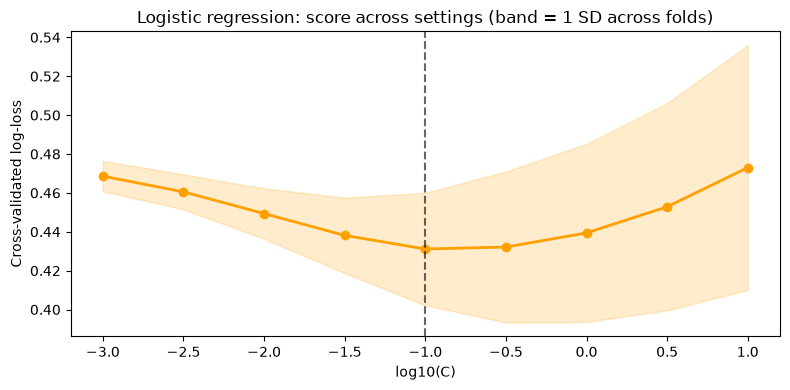

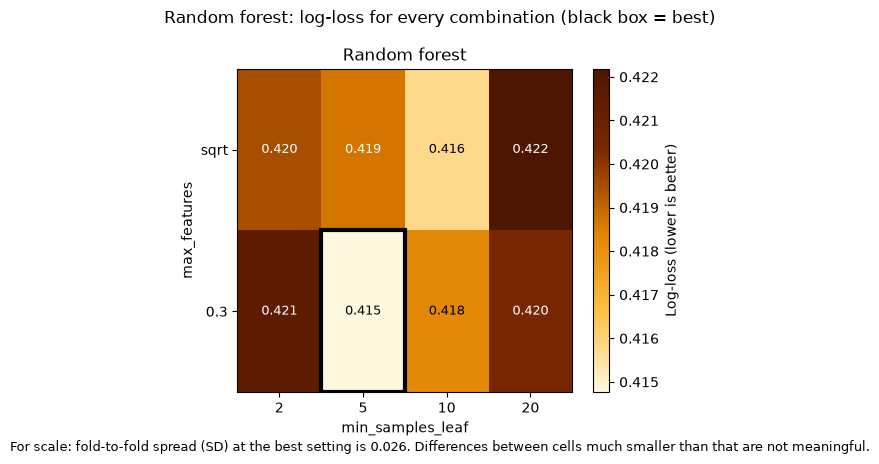

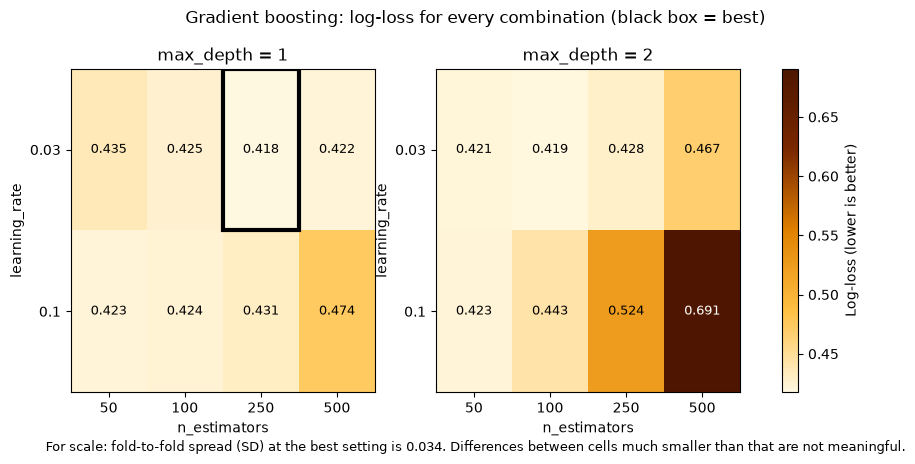

In [41]:
tuner.plot()   # score for every combination of settings, for each model

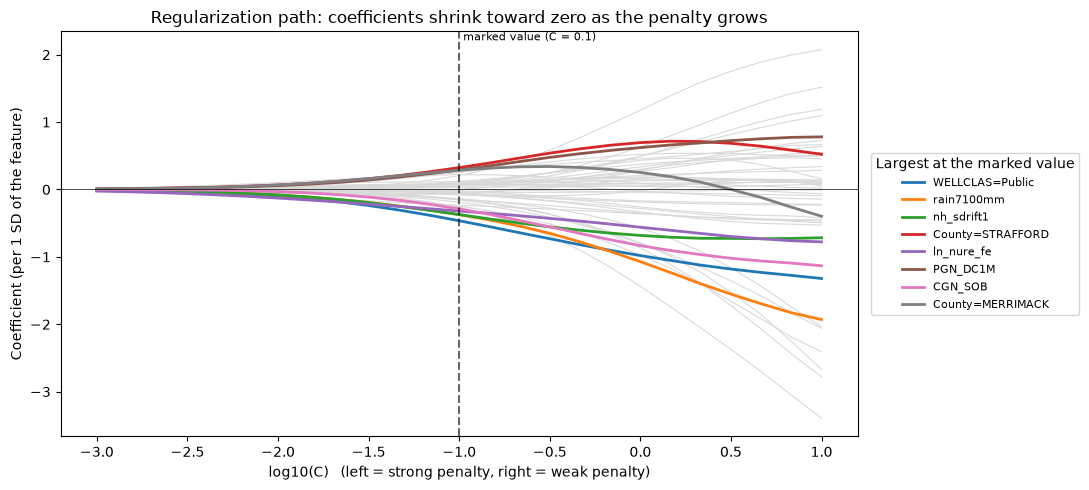

In [42]:
# Redraw the logistic regression path with the penalty that tuning actually chose.
best_C = tuner.searches_["Logistic regression"].best_params_["model__C"]
specs[0].regularization_path(X, y, best_C=best_C)

**How to read the tuning results**

- **Logistic regression** should show a valley: too strong a penalty underfits, too weak overfits, and the dashed line marks the bottom. The shaded band is the fold-to-fold spread, so a valley that is shallower than the band is a gentle preference, not a sharp one.
- **Random forest and gradient boosting** show a heatmap of log-loss, one cell per combination, with the winner boxed in black. Read the "for scale" line under each: if the whole range of the colors is smaller than the fold-to-fold spread, the model is insensitive to these settings and the colors are exaggerating trivial differences.
- **Check the last column of the summary table.** Anything other than "none" means the best value sits at the edge of what was tried, and the grid should be widened before trusting the result.
- **The tuned log-loss values here are optimistic** (the wells used to pick the settings are the same wells that scored them).

## 18. Inferential Analysis (`InferentialReport`)

The models above are judged on *prediction*. This section answers a different question: **how does each predictor change the odds that a well exceeds the threshold, and how sure are we?** Only a classical, unpenalized logistic regression can answer that with proper standard errors, because shrinkage (section 14) biases the coefficients and the standard-error formula assumes they are unbiased.

**The math.** The fit uses Newton's method:

$$\beta^{(t+1)}=\beta^{(t)}+(X^\top W X)^{-1}X^\top(y-p),\qquad W=\mathrm{diag}\big(p_i(1-p_i)\big)$$

At convergence, the covariance of the coefficients is $(X^\top W X)^{-1}$. Then, for each predictor $j$:

- Standard error $SE_j=\sqrt{\big[(X^\top W X)^{-1}\big]_{jj}}$
- Wald statistic $z_j=\hat\beta_j/SE_j$, with p-value $2\big(1-\Phi(|z_j|)\big)$
- Odds ratio $e^{\hat\beta_j}$, with 95 percent interval $\exp(\hat\beta_j\pm1.96\,SE_j)$

The whole model is tested against "no predictors at all" with the likelihood ratio statistic $2(\ell_{full}-\ell_{null})\sim\chi^2_k$, and summarized by McFadden's $R^2=1-\ell_{full}/\ell_{null}$. That number runs far lower than an ordinary $R^2$, and 0.2 to 0.4 already counts as a strong fit.

**How trustworthy is this hand-built fit?** It was checked three ways before use: the coefficients match an independent optimizer to 3.5e-08, the standard errors match the numerical second derivative of the likelihood, and over 600 simulated datasets the 95 percent intervals covered the true value 93 to 97 percent of the time.

**Two choices that keep this honest:**
1. **Few predictors.** A common rule of thumb asks for at least 10 wells of the smaller outcome group per predictor. The pipeline plan (section 12) applies that rule, and the fit reports its own events-per-predictor figure so you can check.
2. **The predictor list is chosen on geochemical grounds, not by score.** The default list is `nure_ph` (arsenic mobility depends on pH), `ln_nure_as` (the regional arsenic baseline), `ln_nure_fe` (iron minerals bind arsenic), `ratiopbcu` (a marker of arsenic-bearing sulfide minerals), `nh_sdrift1` (stratified-drift aquifers) and `rain7100mm` (precipitation). I had already seen the section 10 screening results when I picked it, so the list is not fully independent of the outcome. **Treat the p-values as exploratory.** The interval widths remain trustworthy, but the p-values are somewhat optimistic.

Continuous predictors are standardized, so an odds ratio reads as "the odds are multiplied by this much for each 1 standard deviation increase." For a 0/1 predictor it reads "yes versus no."

In [43]:
def fit_logistic_irls(X, y, max_iter=100, tol=1e-9):
    """
    Logistic regression with no penalty, fit by Newton's method (iteratively
    reweighted least squares). X must already contain a column of ones.
    """
    beta = np.zeros(X.shape[1])
    converged = False
    for iteration in range(max_iter):
        eta = np.clip(X @ beta, -30, 30)
        p = 1.0 / (1.0 + np.exp(-eta))                 # predicted probability for each well
        w = p * (1.0 - p)                              # weight: how much each well says about the slope
        hessian = X.T @ (X * w[:, None])               # X'WX, the information matrix
        step = np.linalg.solve(hessian, X.T @ (y - p)) # Newton step
        beta = beta + step
        if np.max(np.abs(step)) < tol:
            converged = True
            break
    eta = np.clip(X @ beta, -30, 30)
    p = 1.0 / (1.0 + np.exp(-eta))
    w = p * (1.0 - p)
    covariance = np.linalg.inv(X.T @ (X * w[:, None]))  # (X'WX)^-1, the covariance of the coefficients
    loglik = float(np.sum(y * np.log(p + 1e-15) + (1 - y) * np.log(1 - p + 1e-15)))
    return beta, covariance, loglik, converged, iteration + 1


class InferentialReport:
    """
    Classical logistic regression on a small, pre-chosen set of predictors, reporting
    coefficients, standard errors, p-values, and odds ratios with confidence intervals.
    """

    DEFAULT_FEATURES = ["nure_ph", "ln_nure_as", "ln_nure_fe", "ratiopbcu", "nh_sdrift1", "rain7100mm"]

    def __init__(self, X, y, features=None):
        self.features = features or self.DEFAULT_FEATURES
        self.X = X[self.features]
        self.y = np.asarray(y).astype(int)

    def fit(self):
        prep = Preprocessor(scale=True).fit(self.X)           # standardize, so odds ratios are "per 1 standard deviation"
        Z = prep.transform(self.X)
        design = np.column_stack([np.ones(len(Z)), Z.to_numpy()])
        beta, cov, loglik, converged, n_iter = fit_logistic_irls(design, self.y.astype(float))
        se = np.sqrt(np.diag(cov))
        z = beta / se
        names = ["intercept"] + list(Z.columns)
        units = ["baseline"] + ["per 1 SD" if c in prep.continuous_cols_ else "yes vs no" for c in Z.columns]
        self.table_ = pd.DataFrame({
            "feature": names, "unit": units, "coefficient": beta, "std_error": se, "z": z,
            "p_value": 2 * scipy_stats.norm.sf(np.abs(z)),                 # Wald test
            "odds_ratio": np.exp(beta),
            "or_ci_low": np.exp(beta - 1.96 * se), "or_ci_high": np.exp(beta + 1.96 * se),
        })
        p_null = self.y.mean()
        loglik_null = len(self.y) * (p_null * np.log(p_null) + (1 - p_null) * np.log(1 - p_null))
        k = len(names) - 1
        lr_stat = 2 * (loglik - loglik_null)
        self.fit_stats_ = {
            "events": int(self.y.sum()), "predictors": k,
            "events_per_predictor": self.y.sum() / k,                       # rule of thumb: want at least 10
            "likelihood_ratio_chi2": lr_stat, "likelihood_ratio_p": float(scipy_stats.chi2.sf(lr_stat, k)),
            "mcfadden_r2": 1 - loglik / loglik_null, "converged": converged, "iterations": n_iter,
        }
        if (not converged) or np.max(np.abs(beta)) > 15:
            print("Warning: the fit may not have converged cleanly (possible perfect separation). Treat these estimates with caution.")
        return self

    def show(self):
        pd.set_option("display.float_format", lambda v: f"{v:.4f}")
        print(self.table_.to_string(index=False))
        print()
        for key, value in self.fit_stats_.items():
            print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

    def plot(self):
        """Odds ratios with 95 percent intervals. Amber means the interval excludes 1 (no effect)."""
        t = self.table_[self.table_["feature"] != "intercept"].iloc[::-1]
        fig, ax = plt.subplots(figsize=(8, 0.6 * len(t) + 1.5))
        for i, (_, r) in enumerate(t.iterrows()):
            real = r["or_ci_low"] > 1 or r["or_ci_high"] < 1
            ax.hlines(i, r["or_ci_low"], r["or_ci_high"], color=AMBER if real else GRAY, lw=4)
            ax.plot(r["odds_ratio"], i, "o", color=DARK if real else GRAY, ms=9)
        ax.axvline(1, color="k", ls="--", alpha=0.6)
        ax.set_xscale("log")
        ax.set_yticks(range(len(t)), [f"{f} ({u})" for f, u in zip(t["feature"], t["unit"])])
        ax.set(xlabel="Odds ratio (log scale; right of 1 = more likely above threshold)", title="What moves the odds of exceeding the threshold")
        fig.tight_layout()
        plt.show()

print("InferentialReport defined.")

InferentialReport defined.


In [44]:
if plan["inference_features"]:
    report = InferentialReport(X, y, features=plan["inference_features"]).fit()   # fits on all wells with no cross-validation: this is explanation, not prediction
    report.show()
else:
    print("[skipped] none of the preferred inference predictors are in this dataset.")

   feature      unit  coefficient  std_error       z  p_value  odds_ratio  or_ci_low  or_ci_high
 intercept  baseline      -1.5361     0.1849 -8.3075   0.0000      0.2152     0.1498      0.3092
   nure_ph  per 1 SD      -0.2994     0.1815 -1.6494   0.0991      0.7412     0.5193      1.0580
ln_nure_as  per 1 SD       0.4683     0.1554  3.0131   0.0026      1.5972     1.1778      2.1660
ln_nure_fe  per 1 SD      -0.4556     0.2364 -1.9275   0.0539      0.6341     0.3990      1.0077
 ratiopbcu  per 1 SD       0.2153     0.2336  0.9219   0.3566      1.2403     0.7847      1.9605
rain7100mm  per 1 SD      -0.7926     0.2360 -3.3588   0.0008      0.4527     0.2850      0.7189
nh_sdrift1 yes vs no      -0.9135     0.3458 -2.6419   0.0082      0.4011     0.2037      0.7899

events: 68
predictors: 6
events_per_predictor: 11.3333
likelihood_ratio_chi2: 42.7542
likelihood_ratio_p: 0.0000
mcfadden_r2: 0.1207
converged: True
iterations: 7


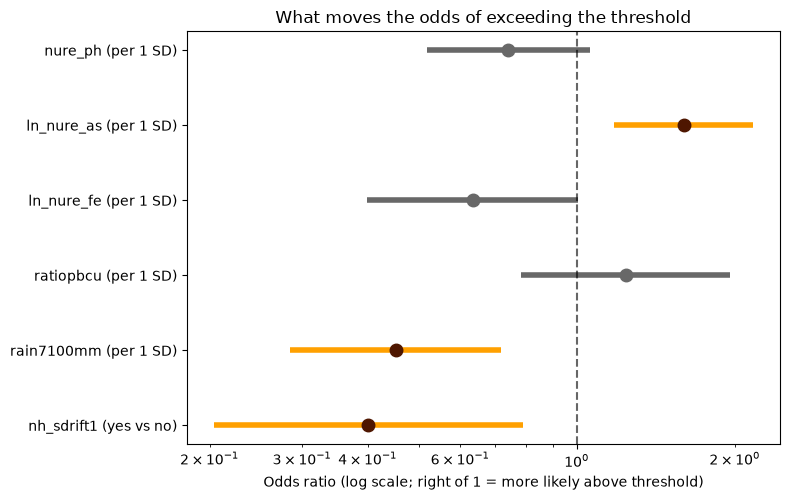

 predictor  r_squared_vs_others    VIF
 ratiopbcu               0.4371 1.7800
ln_nure_fe               0.4265 1.7400
   nure_ph               0.3051 1.4400
rain7100mm               0.1111 1.1200
ln_nure_as               0.0202 1.0200


In [45]:
if plan["inference_features"]:
    report.plot()   # amber = the interval excludes 1, so the effect is distinguishable from none

    # Do the chosen predictors overlap with each other? (VIF near 1 means no; above 5 is worth a second look)
    print(StatisticalScreener.compute_vif(X, [c for c in report.features if c != "nh_sdrift1"]).to_string(index=False))

**How to read the table.**
- **`odds_ratio`:** 1 means no effect. Above 1, the odds of exceeding the threshold rise with the predictor. Below 1, they fall. An odds ratio of 2.0 per 1 SD means a well one standard deviation higher on that predictor has twice the odds.
- **`or_ci_low` and `or_ci_high`:** the 95 percent interval. If it contains 1, the data cannot distinguish the effect from none.
- **`events_per_predictor`:** below 10 means the estimates are less stable than they look. Say so in any write-up.
- **Check each direction against the geochemistry.** Higher pH is expected to mobilize arsenic, and iron minerals are expected to bind it. An effect pointing the wrong way is a reason to investigate, not to report.
- **The p-values are exploratory** (see the note at the top of this section).

# Part 4: Model Evaluation and Interpretation

## 19. Nested Cross-Validation and Evaluation (`ModelSuite`, `ModelEvaluator`)

This is where honest performance numbers come from. Section 17 tuned the models on all wells, so those scores are optimistic. Here, the entire procedure is repeated from scratch inside every fold.

**The procedure, for each outer fold:**
1. Hold out one fold of wells. They are not touched until step 5.
2. On the remaining wells, run the full grid search from section 17 (an *inner* cross-validation) to pick the model's settings.
3. Still inside the training wells, find the decision cutoff that gives the best F1 score.
4. Fit the model with those settings on all training wells.
5. Only now predict the held-out wells, using that model and that cutoff.

Every well ends up with exactly one prediction per repeat, made by a model that never saw it and whose settings it never influenced. The whole thing is repeated with new random splits, and every model sees identical splits so the comparison is fair. The number of folds and repeats comes from the pipeline plan (section 12).

### The metrics

With TP, FP, TN, FN as the four confusion counts (contaminated wells caught, safe wells wrongly flagged, safe wells cleared, contaminated wells missed):

| Metric | In plain words |
|---|---|
| Precision | of wells flagged, how many truly exceed |
| Recall | of contaminated wells, how many were caught |
| Specificity | of safe wells, how many were correctly cleared |
| F1 | one number balancing precision and recall |
| MCC | uses all four counts; 0 for any model no better than chance, however lopsided the classes |
| Balanced accuracy | accuracy that treats both groups as equally important |
| ROC-AUC | chance a random contaminated well is ranked riskier than a random safe one |
| PR-AUC | like ROC-AUC, but not flattered by the many easy safe wells |
| Brier score | do predicted risks mean what they say (lower is better) |
| Accuracy | shown for reference only, see below |
egets squeezed:

$$\text{Precision}=\frac{TP}{TP+FP}$$

$$\text{Recall}=\frac{TP}{TP+FN}$$

$$\text{Specificity}=\frac{TN}{TN+FP}$$

$$F_1=\frac{2\,TP}{2\,TP+FP+FN}$$

$$\text{MCC}=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$

$$\text{Balanced accuracy}=\frac{\text{recall}+\text{specificity}}{2}$$

$$\text{Brier score}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)^2$$

$$\tex they have no one-line formula.

Each has a **no-skill value** to compare against: ROC-AUC 0.5, MCC 0, balanced accuracy 0.5, PR-AUC equal to the share of contaminated wells, and Brier equal to $\pi(1-\pi)$, where $\pi$ is that share.

**Which metric decides?** Only the **primary metric**, which is fixed at the top of the notebook from your goal (section 2) and justified in section 11. Everything else in the table is reported for every model so the result can be read from several angles, but only the primary metric chooses the model (section 20).

**The accuracy row is a reference only.** It is shown so it can be set beside the published USGS accuracy (54.8, 76.3 and 86.4 percent). It is not used for any decision, and it is not a like-for-like comparison: USGS scored a model built on other wells at one cutoff, while here every well is scored out of fold.

### Choosing the cutoff without cheating

Precision, recall, F1 and MCC need a yes/no call, which needs a cutoff. The cutoff that maximizes F1 is found using only the training wells of each fold (step 3). Choosing it on the same wells that get scored would make every number look better than it is.

### Uncertainty

**Bootstrap.** The wells are resampled with replacement 1000 times, every metric is recomputed each time, and the 2.5th and 97.5th percentiles become the 95 percent interval. All models are scored on the same resamples, so the interval on "model A minus model B" shows whether a gap is real.

**McNemar's test** looks only at wells where exactly one of two models is right ($b$ and $c$ of them). If the models were equally good, each such well is equally likely to favor either, so $\min(b,c)\sim\text{Binomial}(b+c,\,0.5)$ and an exact p-value follows. It is run on contaminated wells only. Over all wells it mostly measures the safe majority and where each model happens to place its cutoff, which is not what we want to compare.

In [46]:
class ModelSuite:
    """
    Scores each model family with repeated, stratified, nested cross-validation.
    Inside every training set it tunes the model's settings and picks a decision cutoff,
    so the held-out wells are never used to make any choice.
    """

    def __init__(self, specs, n_splits=5, n_repeats=2, inner_splits=5, scoring="neg_log_loss", random_state=42, n_jobs=-1):
        self.specs = specs
        self.n_splits = n_splits          # folds in each cross-validation round
        self.n_repeats = n_repeats        # how many times the whole cross-validation is redone with new splits
        self.inner_splits = inner_splits  # folds used inside each training set for tuning and the cutoff
        self.scoring = scoring
        self.random_state = random_state
        self.n_jobs = n_jobs

    @staticmethod
    def pick_threshold(y_true, probs):
        """Choose the cutoff that gives the best F1 score on the data it is shown."""
        best_threshold, best_f1 = 0.5, -1.0
        for t in np.arange(0.05, 0.96, 0.01):
            flagged = probs >= t
            tp = np.sum(flagged & (y_true == 1))
            fp = np.sum(flagged & (y_true == 0))
            fn = np.sum(~flagged & (y_true == 1))
            f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0  # F1 = 2TP / (2TP + FP + FN)
            if f1 > best_f1:
                best_f1, best_threshold = f1, t
        return best_threshold

    def cross_validate(self, X, y):
        y = np.asarray(y).astype(int)
        n = len(y)
        results = {"y": y, "probabilities": {}, "thresholds": {}, "chosen_params": {}}
        for spec in self.specs:
            probs = np.zeros((self.n_repeats, n))   # one predicted risk per well, per repeat
            thrs = np.zeros((self.n_repeats, n))    # the cutoff used for that well's fold
            chosen = []
            for r in range(self.n_repeats):
                outer = StratifiedKFold(self.n_splits, shuffle=True, random_state=self.random_state + r)  # same splits for every model
                for train_idx, test_idx in outer.split(X, y):
                    X_train, y_train = X.iloc[train_idx], y[train_idx]
                    inner = StratifiedKFold(self.inner_splits, shuffle=True, random_state=self.random_state + 100 + r)
                    search = spec.tuner(inner, self.scoring, self.n_jobs).fit(X_train, y_train)  # tune on training wells only
                    chosen.append(search.best_params_)
                    inner_probs = cross_val_predict(clone(search.best_estimator_), X_train, y_train, cv=inner, method="predict_proba")[:, 1]
                    thrs[r, test_idx] = self.pick_threshold(y_train, inner_probs)               # cutoff from training wells only
                    probs[r, test_idx] = search.best_estimator_.predict_proba(X.iloc[test_idx])[:, 1]
                print(f"{spec.name}: repeat {r + 1} of {self.n_repeats} done")
            results["probabilities"][spec.name] = probs
            results["thresholds"][spec.name] = thrs
            results["chosen_params"][spec.name] = chosen
        return results


class ModelEvaluator:
    """
    Scores every model on out-of-fold predictions, attaches bootstrap confidence
    intervals, and compares models against each other and against a no-skill baseline.
    """

    METRICS = ["precision", "recall", "specificity", "f1", "mcc", "balanced_accuracy", "roc_auc", "pr_auc", "brier", "accuracy"]

    def __init__(self, cv_results, n_boot=1000, random_state=42):
        self.cv = cv_results
        self.y = cv_results["y"]
        self.n_boot = n_boot              # how many times the wells are resampled
        self.random_state = random_state
        self.boot_, self.point_ = {}, {}

    @staticmethod
    def metrics_from(y, probs, flagged):
        tp = int(np.sum((flagged == 1) & (y == 1)))  # contaminated wells correctly flagged
        fp = int(np.sum((flagged == 1) & (y == 0)))  # safe wells wrongly flagged
        tn = int(np.sum((flagged == 0) & (y == 0)))  # safe wells correctly cleared
        fn = int(np.sum((flagged == 0) & (y == 1)))  # contaminated wells missed
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        denominator = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
        mcc = (tp * tn - fp * fn) / denominator if denominator > 0 else 0.0
        return {
            "precision": precision, "recall": recall, "specificity": specificity, "f1": f1, "mcc": mcc,
            "balanced_accuracy": (recall + specificity) / 2,
            "roc_auc": roc_auc_score(y, probs), "pr_auc": average_precision_score(y, probs),
            "brier": brier_score_loss(y, probs), "accuracy": (tp + tn) / len(y),
        }

    def predictions(self, name, repeat=0):
        """Turn each well's predicted risk into a yes/no call, using the cutoff from its own fold."""
        return (self.cv["probabilities"][name][repeat] >= self.cv["thresholds"][name][repeat]).astype(int)

    def chosen_hyperparameters(self):
        """Which settings the inner tuning picked, and how often, across the outer folds."""
        rows = []
        for name, folds in self.cv["chosen_params"].items():
            for setting in folds[0]:
                counts = pd.Series([f"{f[setting]:.4g}" if isinstance(f[setting], float) else str(f[setting]) for f in folds]).value_counts()
                rows.append({"model": name, "setting": setting.replace("model__", ""), "chosen most often": counts.index[0],
                             "times": f"{counts.iloc[0]} of {len(folds)} folds"})
        return pd.DataFrame(rows)

    def cv_spread(self):
        """Mean and spread of each metric across the repeated cross-validation rounds."""
        table = {}
        for name in self.cv["probabilities"]:
            rows = [self.metrics_from(self.y, self.cv["probabilities"][name][r], self.predictions(name, r))
                    for r in range(self.cv["probabilities"][name].shape[0])]
            frame = pd.DataFrame(rows)
            table[name] = [f"{frame[m].mean():.3f} +/- {frame[m].std(ddof=0):.3f}" for m in self.METRICS]
        return pd.DataFrame(table, index=self.METRICS)

    def run_bootstrap(self, repeat=0):
        """Resample the wells with replacement; every model sees the same resamples, so differences are paired."""
        rng = np.random.default_rng(self.random_state)
        n = len(self.y)
        names = list(self.cv["probabilities"])
        probs = {m: self.cv["probabilities"][m][repeat] for m in names}
        flags = {m: self.predictions(m, repeat) for m in names}
        draws = {m: [] for m in names}
        for _ in range(self.n_boot):
            idx = rng.integers(0, n, n)
            if self.y[idx].min() == self.y[idx].max():
                continue  # a resample with only one class cannot be scored
            for m in names:
                draws[m].append(self.metrics_from(self.y[idx], probs[m][idx], flags[m][idx]))
        self.boot_ = {m: pd.DataFrame(rows) for m, rows in draws.items()}
        self.point_ = {m: self.metrics_from(self.y, probs[m], flags[m]) for m in names}
        return self

    def summary(self):
        """Each metric as: value on all wells (95 percent bootstrap interval)."""
        table = {}
        for name, draws in self.boot_.items():
            cells = []
            for m in self.METRICS:
                lo, hi = np.percentile(draws[m], [2.5, 97.5])
                cells.append(f"{self.point_[name][m]:.3f} ({lo:.3f} to {hi:.3f})")
            table[name] = cells
        return pd.DataFrame(table, index=self.METRICS)

    def no_skill_reference(self):
        """What a model with no real skill would score, for comparison."""
        prevalence = float(self.y.mean())
        return {"roc_auc": 0.5, "pr_auc": prevalence, "mcc": 0.0, "balanced_accuracy": 0.5,
                "brier": prevalence * (1 - prevalence), "accuracy (always say safe)": 1 - prevalence}

    def paired_difference(self, a, b, metric):
        """How much model a beats model b on one metric, with a bootstrap interval."""
        diff = self.boot_[a][metric] - self.boot_[b][metric]
        lo, hi = np.percentile(diff, [2.5, 97.5])
        return {"difference": float(diff.mean()), "ci_low": float(lo), "ci_high": float(hi),
                "interval_excludes_zero": bool(lo > 0 or hi < 0)}

    def mcnemar(self, a, b, subset="all", repeat=0):
        """Exact McNemar test on the wells where exactly one of the two models is right."""
        mask = {"all": np.ones(len(self.y), bool), "positives": self.y == 1, "negatives": self.y == 0}[subset]
        ok_a = self.predictions(a, repeat)[mask] == self.y[mask]
        ok_b = self.predictions(b, repeat)[mask] == self.y[mask]
        only_a, only_b = int(np.sum(ok_a & ~ok_b)), int(np.sum(~ok_a & ok_b))
        p = scipy_stats.binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if (only_a + only_b) > 0 else 1.0
        return {"only_a_correct": only_a, "only_b_correct": only_b, "p_value": float(p)}

    def readout(self):
        """Plain facts pulled from the results, for writing the conclusions."""
        names = list(self.boot_)
        ref = self.no_skill_reference()
        lines = []
        for m, label, base in [("mcc", "MCC", 0.0), ("pr_auc", "PR-AUC", ref["pr_auc"])]:
            best = max(names, key=lambda n: self.point_[n][m])
            lines.append(f"Best {label}: {best} ({self.point_[best][m]:.3f}); no-skill value is {base:.3f}.")
            for n in names:
                lo = np.percentile(self.boot_[n][m], 2.5)
                verdict = "clearly above" if lo > base else "not clearly above"
                lines.append(f"  {n}: lower end of its interval is {lo:.3f}, {verdict} no-skill.")
        for i, a in enumerate(names):
            for b in names[i + 1:]:
                for m in ["mcc", "pr_auc"]:
                    d = self.paired_difference(a, b, m)
                    verdict = "a real gap" if d["interval_excludes_zero"] else "no clear gap"
                    lines.append(f"{a} minus {b} on {m}: {d['difference']:+.3f} ({d['ci_low']:+.3f} to {d['ci_high']:+.3f}), {verdict}.")
                t = self.mcnemar(a, b, "positives")
                lines.append(f"{a} vs {b}, contaminated wells only (McNemar): p = {t['p_value']:.3f}.")
        text = "\n".join(lines)
        print(text)
        return text

print("ModelSuite and ModelEvaluator defined.")

ModelSuite and ModelEvaluator defined.


In [47]:
suite = ModelSuite(specs, n_splits=plan["n_splits"], n_repeats=plan["n_repeats"], inner_splits=plan["inner_splits"])   # every setting comes from the pipeline plan
cv_results = suite.cross_validate(X, y)              # the slow step: tuning is repeated inside every fold

Logistic regression: repeat 1 of 2 done
Logistic regression: repeat 2 of 2 done
Random forest: repeat 1 of 2 done
Random forest: repeat 2 of 2 done
Gradient boosting: repeat 1 of 2 done
Gradient boosting: repeat 2 of 2 done


In [48]:
evaluator = ModelEvaluator(cv_results, n_boot=1000).run_bootstrap()   # resamples the wells 1000 times

print("Each cell: value on all wells (95 percent bootstrap interval)\n")
print(evaluator.summary().to_string())

print("\nNo-skill reference values:")
for metric, value in evaluator.no_skill_reference().items():
    print(f"  {metric}: {value:.3f}")

Each cell: value on all wells (95 percent bootstrap interval)

                      Logistic regression           Random forest       Gradient boosting
precision          0.265 (0.203 to 0.333)  0.331 (0.255 to 0.408)  0.307 (0.234 to 0.385)
recall             0.721 (0.619 to 0.831)  0.691 (0.576 to 0.810)  0.632 (0.516 to 0.750)
specificity        0.554 (0.498 to 0.613)  0.689 (0.635 to 0.740)  0.682 (0.632 to 0.733)
f1                 0.387 (0.315 to 0.467)  0.448 (0.362 to 0.528)  0.413 (0.330 to 0.495)
mcc                0.212 (0.126 to 0.312)  0.302 (0.202 to 0.392)  0.251 (0.147 to 0.347)
balanced_accuracy  0.637 (0.581 to 0.700)  0.690 (0.629 to 0.747)  0.657 (0.594 to 0.724)
roc_auc            0.712 (0.651 to 0.780)  0.755 (0.694 to 0.815)  0.743 (0.685 to 0.804)
pr_auc             0.330 (0.255 to 0.447)  0.378 (0.287 to 0.507)  0.381 (0.287 to 0.500)
brier              0.138 (0.114 to 0.161)  0.131 (0.110 to 0.152)  0.134 (0.111 to 0.157)
accuracy           0.584 (0.536 to 0.

In [49]:
print("Spread across the repeated cross-validation rounds (mean +/- sd):\n")
print(evaluator.cv_spread().to_string())        # how much each score moves with the luck of the split

print("\nWhich settings the tuning chose inside each fold:\n")
print(evaluator.chosen_hyperparameters().to_string(index=False))   # if the same value wins every time, the choice is stable

Spread across the repeated cross-validation rounds (mean +/- sd):

                  Logistic regression    Random forest Gradient boosting
precision             0.276 +/- 0.011  0.319 +/- 0.012   0.317 +/- 0.010
recall                0.647 +/- 0.074  0.603 +/- 0.088   0.566 +/- 0.066
specificity           0.618 +/- 0.064  0.715 +/- 0.026   0.726 +/- 0.044
f1                    0.385 +/- 0.002  0.416 +/- 0.032   0.404 +/- 0.009
mcc                   0.209 +/- 0.004  0.258 +/- 0.044   0.242 +/- 0.009
balanced_accuracy     0.633 +/- 0.005  0.659 +/- 0.031   0.646 +/- 0.011
roc_auc               0.697 +/- 0.016  0.750 +/- 0.005   0.742 +/- 0.001
pr_auc                0.319 +/- 0.011  0.388 +/- 0.011   0.395 +/- 0.014
brier                 0.140 +/- 0.003  0.131 +/- 0.000   0.133 +/- 0.001
accuracy              0.623 +/- 0.039  0.694 +/- 0.005   0.697 +/- 0.024

Which settings the tuning chose inside each fold:

              model          setting chosen most often          times
Logistic

In [50]:
readout = evaluator.readout()    # plain-language facts pulled from the results above

Best MCC: Random forest (0.302); no-skill value is 0.000.
  Logistic regression: lower end of its interval is 0.126, clearly above no-skill.
  Random forest: lower end of its interval is 0.202, clearly above no-skill.
  Gradient boosting: lower end of its interval is 0.147, clearly above no-skill.
Best PR-AUC: Gradient boosting (0.381); no-skill value is 0.182.
  Logistic regression: lower end of its interval is 0.255, clearly above no-skill.
  Random forest: lower end of its interval is 0.287, clearly above no-skill.
  Gradient boosting: lower end of its interval is 0.287, clearly above no-skill.
Logistic regression minus Random forest on mcc: -0.088 (-0.188 to +0.014), no clear gap.
Logistic regression minus Random forest on pr_auc: -0.049 (-0.116 to +0.020), no clear gap.
Logistic regression vs Random forest, contaminated wells only (McNemar): p = 0.815.
Logistic regression minus Gradient boosting on mcc: -0.038 (-0.145 to +0.077), no clear gap.
Logistic regression minus Gradient bo

**How to read these tables**

- **Start with the primary metric,** then compare it with its no-skill value. If the *lower* end of a model's interval is above no-skill, the model has real signal. If the interval reaches no-skill, this dataset cannot tell that model apart from guessing.
- **Turn precision and recall into wells.** Of every 100 wells a model flags, `precision` times 100 are truly above the threshold. Of every 100 truly contaminated wells, `recall` times 100 get caught. Which matters more depends on the use: for deciding who gets a free water test, a miss costs more than a false alarm.
- **Overlapping intervals do not prove two models are equal.** The paired-difference lines in the readout are the proper comparison, because every model was scored on the same resamples.
- **Brier score** checks that a predicted risk of 0.30 means about 30 percent. Compare it with the no-skill Brier value.
- **The spread table** shows how much each score moves just from re-drawing the splits. If a difference between two models is smaller than that spread, it is not a difference worth reporting.
- **The stability table** shows whether tuning is consistent. A setting chosen in nearly every fold is a firm choice. One split evenly across values means the model does not care much.

## 20. Model Selection: The Predefined Primary Metric Decides

The metric and the rule below were fixed **before** any model was run (sections 2 and 11), so the choice cannot be bent toward whichever model happens to look good.

**The rule.**
1. Rank the models by the primary metric on the out-of-fold predictions. The highest score is the *leader*.
2. If a **simpler** model is statistically tied with the leader, it wins instead. Simplicity order: logistic regression, then random forest, then gradient boosting. A simpler model is easier to explain, and less likely to be fitting noise.
3. "Statistically tied" has a precise meaning. For each of the $B=1000$ bootstrap resamples $b$, compute the difference between the leader's score and the simpler model's score on the *same* resample:

$$\Delta_b = m^{(b)}_{\text{leader}}-m^{(b)}_{\text{simpler}},\qquad b=1,\dots,B$$

The 2.5th and 97.5th percentiles of the $\Delta_b$ form a 95 percent interval. If it contains zero, the data cannot tell the two models apart, and the simpler one is chosen.

**Why this rule rather than "highest number wins."** With a few hundred wells, two models' scores differ by amounts well inside the uncertainty. Picking the top score would mostly pick whichever model got lucky. The tie rule only lets a more complex model win when it is clearly better.

The cell below applies the rule, prints the justification and a plain-language interpretation, and saves both to `model_selection_report.txt`.

In [51]:
def select_best_model(evaluator, primary_metric, user_goal, simplicity_order=("Logistic regression", "Random forest", "Gradient boosting")):
    """Choose the best model by the predefined primary metric; a simpler model wins if it is statistically tied with the leader."""
    if primary_metric not in evaluator.METRICS:
        raise ValueError(f"'{primary_metric}' is not a metric this evaluator computes. Choose from: {evaluator.METRICS}")
    if not evaluator.point_ or not evaluator.boot_:
        raise RuntimeError("Run evaluator.run_bootstrap() before selecting a model.")
    names = list(evaluator.point_)
    scores = {n: evaluator.point_[n][primary_metric] for n in names}
    leader = max(scores, key=scores.get)                                    # highest primary metric
    ordered = [n for n in simplicity_order if n in names] + [n for n in names if n not in simplicity_order]   # simplest first

    chosen = leader
    if leader == ordered[0]:
        reason = f"{leader} has the highest {primary_metric} and is also the simplest model."
    else:
        reason = f"{leader} has the highest {primary_metric}, and every simpler model is clearly worse (each gap's 95% interval excludes zero)."
    for name in ordered:                                                    # look at simpler models first
        if name == leader:
            break
        gap = evaluator.paired_difference(leader, name, primary_metric)     # leader minus the simpler model, on the same resamples
        if not gap["interval_excludes_zero"]:
            chosen = name
            reason = (f"{name} is simpler than the leader ({leader}), and the gap between them ({gap['difference']:+.3f}, 95% interval "
                      f"{gap['ci_low']:+.3f} to {gap['ci_high']:+.3f}) includes zero, so the simpler model is preferred.")
            break

    table = pd.DataFrame({
        "model": names,
        primary_metric: [scores[n] for n in names],
        "ci_low": [np.percentile(evaluator.boot_[n][primary_metric], 2.5) for n in names],
        "ci_high": [np.percentile(evaluator.boot_[n][primary_metric], 97.5) for n in names],
    }).sort_values(primary_metric, ascending=False).reset_index(drop=True)

    point = evaluator.point_[chosen]
    low, high = np.percentile(evaluator.boot_[chosen][primary_metric], [2.5, 97.5])
    no_skill = evaluator.no_skill_reference().get(primary_metric)
    lines = [
        f"Predefined primary metric: {METRIC_NAMES.get(primary_metric, primary_metric)}, set from the goal '{user_goal}' before any model was run.",
        f"Selected model: {chosen}.",
        f"Why: {reason}",
        f"{primary_metric} = {point[primary_metric]:.3f} (95% interval {low:.3f} to {high:.3f}); a model with no skill scores {no_skill:.3f}.",
        ("The whole interval is above the no-skill value, so the model has real signal." if low > no_skill
         else "The interval reaches the no-skill value, so this dataset cannot clearly tell the model apart from guessing."),
        f"In plain terms, at the cutoff used: of every 100 wells it flags, about {100 * point['precision']:.0f} truly exceed the threshold; "
        f"of every 100 contaminated wells, it catches about {100 * point['recall']:.0f}; of every 100 safe wells, it correctly clears about {100 * point['specificity']:.0f}.",
        f"Other scores for this model: F1 {point['f1']:.3f}, MCC {point['mcc']:.3f}, ROC-AUC {point['roc_auc']:.3f}, balanced accuracy {point['balanced_accuracy']:.3f}.",
        "These are out-of-fold estimates, so they describe wells the model has not seen. They come from one dataset of this size, so treat them as a guide, not a guarantee.",
    ]
    return {"primary_metric": primary_metric, "leader": leader, "chosen": chosen, "reason": reason, "table": table, "lines": lines}

print("select_best_model defined.")

select_best_model defined.


In [52]:
selection = select_best_model(evaluator, PRIMARY_METRIC, USER_GOAL)   # applies the predefined metric and the simplicity rule
best_model_name = selection["chosen"]

print(selection["table"].to_string(index=False), "\n")
print("\n".join(selection["lines"]))

with open(OUTPUT_DIR / "model_selection_report.txt", "w") as handle:
    handle.write("\n".join(selection["lines"]))         # saved so the audit at the end can list it

              model  pr_auc  ci_low  ci_high
  Gradient boosting  0.3810  0.2871   0.5003
      Random forest  0.3775  0.2869   0.5067
Logistic regression  0.3304  0.2548   0.4466 

Predefined primary metric: PR-AUC (average precision), set from the goal 'rank_for_testing' before any model was run.
Selected model: Logistic regression.
Why: Logistic regression is simpler than the leader (Gradient boosting), and the gap between them (+0.048, 95% interval -0.032 to +0.124) includes zero, so the simpler model is preferred.
pr_auc = 0.330 (95% interval 0.255 to 0.447); a model with no skill scores 0.182.
The whole interval is above the no-skill value, so the model has real signal.
In plain terms, at the cutoff used: of every 100 wells it flags, about 26 truly exceed the threshold; of every 100 contaminated wells, it catches about 72; of every 100 safe wells, it correctly clears about 55.
Other scores for this model: F1 0.387, MCC 0.212, ROC-AUC 0.712, balanced accuracy 0.637.
These are out-

## 21. Advanced Visualizations (`ModelVisualizer`)

Numbers in a table hide the shape of the result. These eight views show it. They use the out-of-fold predictions from section 19 (so every well is scored by a model that never saw it) and, where noted, the tuned models from section 17.

| View | Question it answers |
|---|---|
| ROC, precision-recall, calibration curves | do the models rank wells well, and do their risks mean what they say? |
| Scores with intervals | how big are the gaps between models, compared with the uncertainty? |
| Cutoff trade-off | what does moving the decision cutoff cost and buy? |
| Confusion matrices | in plain counts, what does each model get right and wrong? |
| Risk distributions | how well separated are safe wells and contaminated wells? |
| County calibration | do predicted and observed rates agree within each county? |
| Importance heatmap | which predictors does each model lean on, and do they agree? |
| Partial dependence | how does predicted risk change as one predictor moves? |

The county view connects most directly to the capstone: it shows how much of the county-to-county difference in exceedance the models actually capture, with honest intervals for counties that have few wells.

In [53]:
def wilson_interval(k, n, z=1.96):
    """95 percent interval for a proportion from n wells; behaves sensibly even when n is very small."""
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


class ModelVisualizer:
    """All cross-model visualizations, built from the evaluation results and the tuned final models."""

    def __init__(self, evaluator, tuner, X, y):
        self.ev, self.tuner, self.X, self.y = evaluator, tuner, X, np.asarray(y).astype(int)
        self.names = list(evaluator.cv["probabilities"])
        self.avg_probs = {n: evaluator.cv["probabilities"][n].mean(axis=0) for n in self.names}  # average risk across repeats

    def curves(self):
        """ROC, precision-recall, and calibration curves."""
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
        prevalence = float(self.y.mean())
        for name, probs in self.avg_probs.items():
            c = MODEL_COLORS[name]
            fpr, tpr, _ = roc_curve(self.y, probs)
            axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(self.y, probs):.2f})")
            prec, rec, _ = precision_recall_curve(self.y, probs)
            axes[1].plot(rec, prec, color=c, lw=2, label=f"{name} (AP {average_precision_score(self.y, probs):.2f})")
            frac_pos, mean_pred = calibration_curve(self.y, probs, n_bins=5, strategy="quantile")
            axes[2].plot(mean_pred, frac_pos, color=c, marker="o", lw=2, label=name)
        axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
        axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
        axes[1].axhline(prevalence, color="k", linestyle="--", alpha=0.4)
        axes[1].set(title="Precision-recall curve (dashed = no skill)", xlabel="Recall", ylabel="Precision")
        axes[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
        axes[2].set(title="Calibration (dashed = perfect)", xlabel="Predicted risk", ylabel="Share actually above threshold")
        for ax in axes:
            ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()

    def metric_intervals(self, metrics=("mcc", "pr_auc", "roc_auc", "recall", "precision", "f1")):
        """Each model's score on each metric with its 95 percent interval, against the no-skill line."""
        ref = self.ev.no_skill_reference()
        fig, axes = plt.subplots(1, len(metrics), figsize=(3.1 * len(metrics), 3.4), sharey=True)
        for ax, m in zip(axes, metrics):
            for i, name in enumerate(self.names):
                lo, hi = np.percentile(self.ev.boot_[name][m], [2.5, 97.5])
                ax.hlines(i, lo, hi, color=MODEL_COLORS[name], lw=4)
                ax.plot(self.ev.point_[name][m], i, "o", color=MODEL_COLORS[name], ms=9)
            if m in ref:
                ax.axvline(ref[m], color="k", ls="--", alpha=0.5)
            ax.set_title(m.upper().replace("_", "-"), fontsize=10)
            ax.set_yticks(range(len(self.names)), self.names)
        axes[0].invert_yaxis()  # shared axis, so flipping once puts the first model on top
        fig.suptitle("Score with 95 percent bootstrap interval (dashed line = no skill, where one exists)", y=1.03)
        fig.tight_layout()
        plt.show()

    def threshold_tradeoff(self):
        """How precision, recall, F1, and MCC change as the decision cutoff moves."""
        fig, axes = plt.subplots(1, len(self.names), figsize=(5.2 * len(self.names), 4), sharey=True)
        grid = np.arange(0.02, 0.81, 0.01)
        for ax, name in zip(np.atleast_1d(axes), self.names):
            p = self.avg_probs[name]
            rows = [self.ev.metrics_from(self.y, p, (p >= t).astype(int)) for t in grid]
            n_flagged = np.array([(p >= t).sum() for t in grid])
            for metric, color in [("precision", GRAY), ("recall", AMBER), ("f1", BROWN), ("mcc", "#1f77b4")]:
                values = np.array([r[metric] for r in rows], dtype=float)
                if metric == "precision":
                    values[n_flagged < 5] = np.nan  # precision from a handful of flagged wells is just noise
                ax.plot(grid, values, color=color, lw=2, label=metric)
            used = np.median(self.ev.cv["thresholds"][name])
            ax.axvline(used, color="k", ls="--", alpha=0.6)
            ax.text(used, 1.0, " cutoff used", fontsize=8, va="top")
            ax.set(title=name, xlabel="Decision cutoff", ylim=(0, 1))
        np.atleast_1d(axes)[0].set_ylabel("Score")
        np.atleast_1d(axes)[0].legend(fontsize=8)
        fig.tight_layout()
        plt.show()

    def confusion_matrices(self, repeat=0):
        """Counts of correct and incorrect calls, one matrix per model."""
        fig, axes = plt.subplots(1, len(self.names), figsize=(4.6 * len(self.names), 4))
        for ax, name in zip(np.atleast_1d(axes), self.names):
            flagged = self.ev.predictions(name, repeat)
            counts = np.array([[np.sum((self.y == 0) & (flagged == 0)), np.sum((self.y == 0) & (flagged == 1))],
                               [np.sum((self.y == 1) & (flagged == 0)), np.sum((self.y == 1) & (flagged == 1))]])
            share = counts / counts.sum(axis=1, keepdims=True)
            ax.imshow(share, cmap=AMBER_CMAP, vmin=0, vmax=1)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{counts[i, j]}\n({share[i, j]:.0%} of row)", ha="center", va="center",
                            color="white" if share[i, j] > 0.5 else "black", fontsize=10)
            ax.set_xticks([0, 1], ["Called safe", "Flagged"])
            ax.set_yticks([0, 1], ["Actually safe", "Actually above"])
            ax.set_title(name)
        fig.tight_layout()
        plt.show()

    def risk_distributions(self):
        """Predicted risk for safe wells versus wells above the threshold: how well do the two groups separate?"""
        fig, axes = plt.subplots(1, len(self.names), figsize=(5.2 * len(self.names), 3.8), sharey=True)
        for ax, name in zip(np.atleast_1d(axes), self.names):
            p = self.avg_probs[name]
            sns.kdeplot(p[self.y == 0], ax=ax, color=GRAY, fill=True, alpha=0.4, lw=2, clip=(0, 1), label="Below threshold")
            sns.kdeplot(p[self.y == 1], ax=ax, color=AMBER, fill=True, alpha=0.4, lw=2, clip=(0, 1), label="Above threshold")
            ax.set(title=name, xlabel="Predicted risk", ylabel="Density")
        np.atleast_1d(axes)[0].legend(fontsize=8)
        fig.tight_layout()
        plt.show()

    def county_calibration(self, df, model=None, county_col="County"):
        """For each county, observed exceedance rate versus the model's average predicted risk."""
        model = model or max(self.names, key=lambda n: self.ev.point_[n]["pr_auc"])
        table = pd.DataFrame({"county": df[county_col].astype(str).str.title().to_numpy(), "y": self.y, "p": self.avg_probs[model]})
        by_county = table.groupby("county").agg(n=("y", "size"), k=("y", "sum"), predicted=("p", "mean")).reset_index()
        by_county["observed"] = by_county["k"] / by_county["n"]
        bounds = np.array([wilson_interval(k, n) for k, n in zip(by_county["k"], by_county["n"])])
        limit = max(by_county["predicted"].max(), bounds[:, 1].max()) * 1.08
        fig, ax = plt.subplots(figsize=(7.5, 6.5))
        ax.plot([0, limit], [0, limit], "k--", alpha=0.4)
        ax.errorbar(by_county["predicted"], by_county["observed"],
                    yerr=[by_county["observed"] - bounds[:, 0], bounds[:, 1] - by_county["observed"]],
                    fmt="none", ecolor="#bbbbbb", capsize=3, zorder=1)
        ax.scatter(by_county["predicted"], by_county["observed"], s=by_county["n"] * 6, color=AMBER, edgecolor=DARK, zorder=2, alpha=0.9)
        placements = [(7, 7, "left"), (7, -14, "left"), (-7, 7, "right"), (-7, -14, "right")]  # spreads labels apart
        for i, (_, r) in enumerate(by_county.sort_values("predicted").iterrows()):
            dx, dy, side = placements[i % 4]
            ax.annotate(r["county"], (r["predicted"], r["observed"]), xytext=(dx, dy), textcoords="offset points", fontsize=8, ha=side)
        ax.set(xlabel=f"Average predicted risk ({model})", ylabel="Observed share above threshold",
               title="By county: do predicted and observed rates agree?\n(bars = 95 percent interval, marker size = wells tested)",
               xlim=(0, limit), ylim=(0, limit))
        fig.tight_layout()
        plt.show()
        return by_county

    def importance_heatmap(self, top_k=10):
        """Which features each tuned model leans on most, scaled so the top feature in each model is 1."""
        specs = {s.name: s for s in self.tuner.specs}
        imp = pd.DataFrame({n: specs[n].importances(self.tuner.best_models_[n]) for n in self.names})
        imp = imp / imp.max()
        keep = set()
        for n in self.names:
            keep |= set(imp[n].sort_values(ascending=False).index[:top_k])
        imp = imp.loc[list(keep)]
        imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
        fig, ax = plt.subplots(figsize=(6.5, 0.38 * len(imp) + 1.5))
        sns.heatmap(imp, annot=True, fmt=".2f", cmap=AMBER_CMAP, vmin=0, vmax=1, cbar_kws={"label": "Relative importance"}, ax=ax)
        ax.set_title("Which predictors each model relies on")
        fig.tight_layout()
        plt.show()
        return imp

    def partial_dependence(self, n_features=3, n_points=15):
        """How predicted risk changes as one predictor moves, averaging over all other predictors."""
        specs = {s.name: s for s in self.tuner.specs}
        imp = pd.DataFrame({n: specs[n].importances(self.tuner.best_models_[n]) for n in self.names})
        score = (imp / imp.max()).mean(axis=1).sort_values(ascending=False)
        features = [f for f in score.index if f in self.X.columns and pd.api.types.is_numeric_dtype(self.X[f]) and self.X[f].nunique() > 2][:n_features]
        fig, axes = plt.subplots(1, len(features), figsize=(5 * len(features), 3.8), sharey=True)
        for ax, feature in zip(np.atleast_1d(axes), features):
            values = np.unique(np.nanpercentile(self.X[feature], np.linspace(5, 95, n_points)))
            for name in self.names:
                model, curve = self.tuner.best_models_[name], []
                for v in values:
                    modified = self.X.copy()
                    modified[feature] = v
                    curve.append(model.predict_proba(modified)[:, 1].mean())
                ax.plot(values, curve, color=MODEL_COLORS[name], lw=2.5, label=name)
            ax.set(xlabel=feature, title=f"Effect of {feature}")
        np.atleast_1d(axes)[0].set_ylabel("Average predicted risk")
        np.atleast_1d(axes)[0].legend(fontsize=8)
        fig.tight_layout()
        plt.show()
        return features

print("ModelVisualizer defined.")

ModelVisualizer defined.


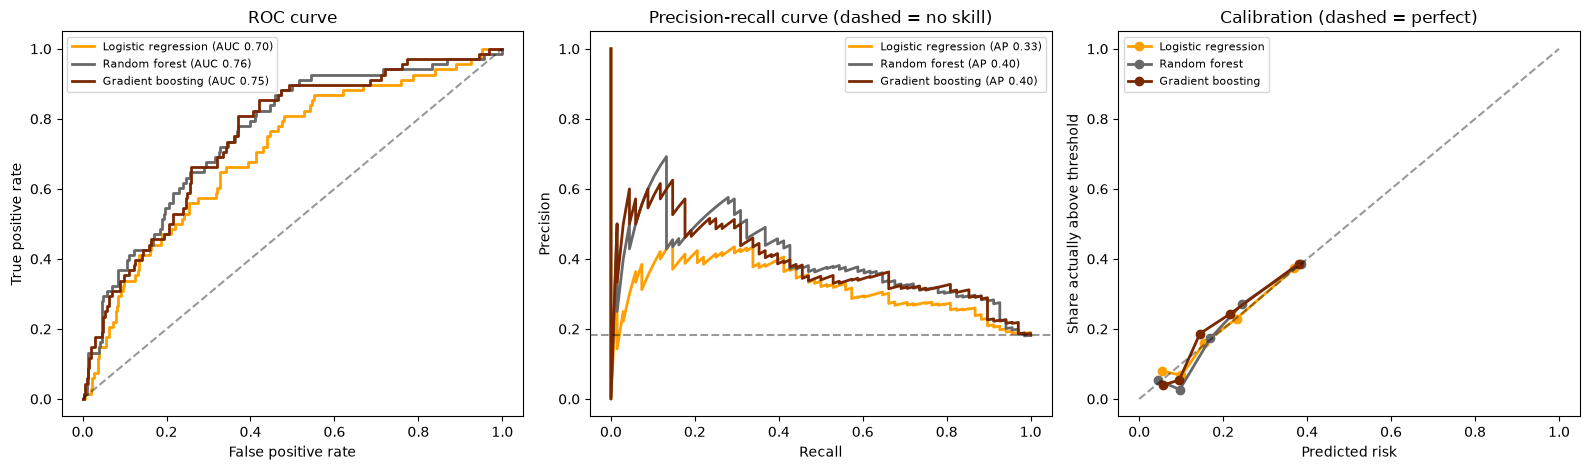

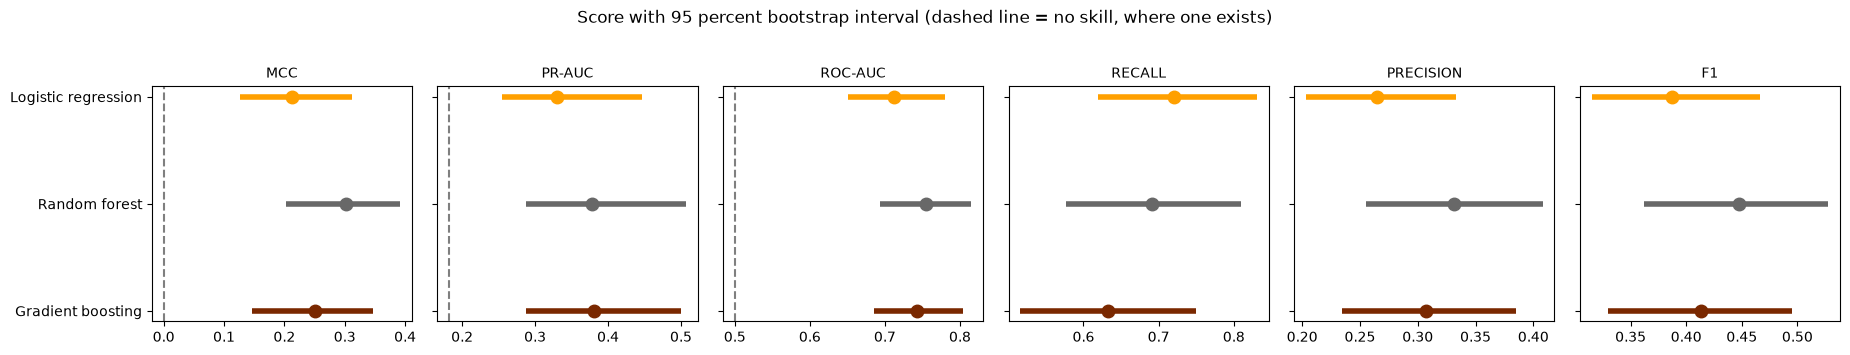

In [54]:
viz = ModelVisualizer(evaluator, tuner, X, y)   # uses the out-of-fold predictions and the tuned final models

viz.curves()              # ROC, precision-recall, and calibration
viz.metric_intervals()    # every model's score with its 95 percent interval

**How to read these.** In the ROC and precision-recall curves, higher is better, and each dashed line is no skill, so a curve hugging it is a model that cannot tell the groups apart. In the calibration panel, points on the diagonal mean predicted risks match reality, while points below it mean the model is overconfident. In the interval plot, a bar that crosses the dashed line is a score that could be chance.

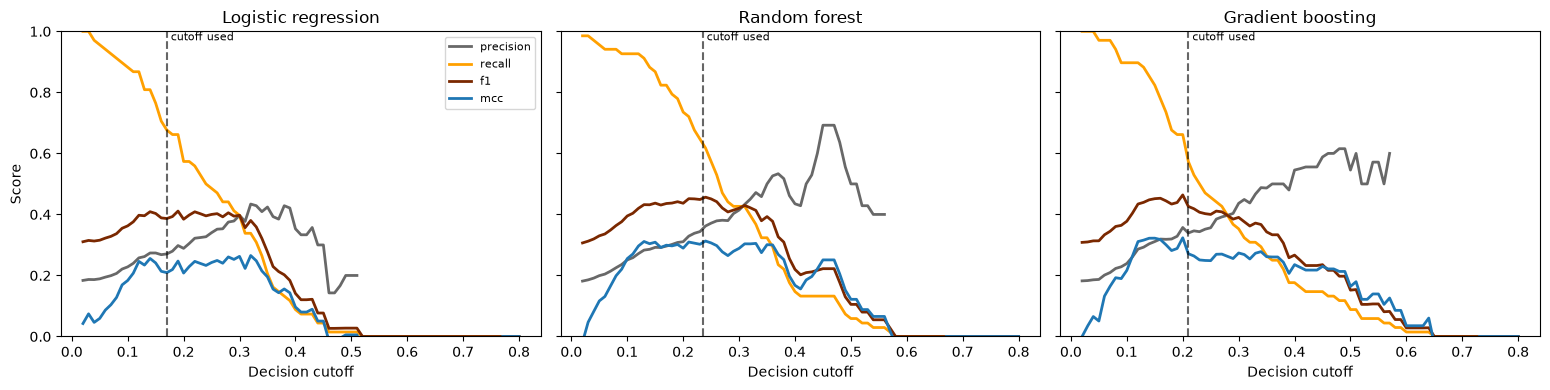

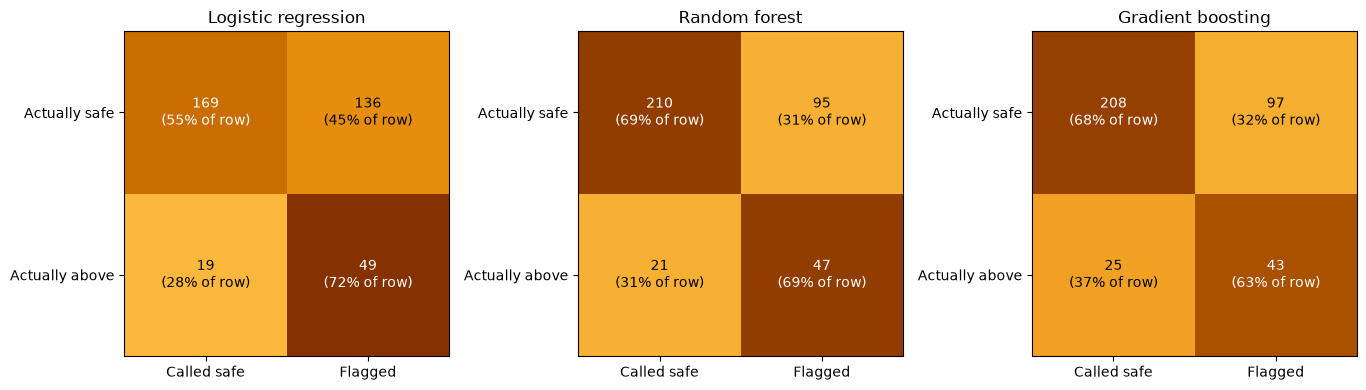

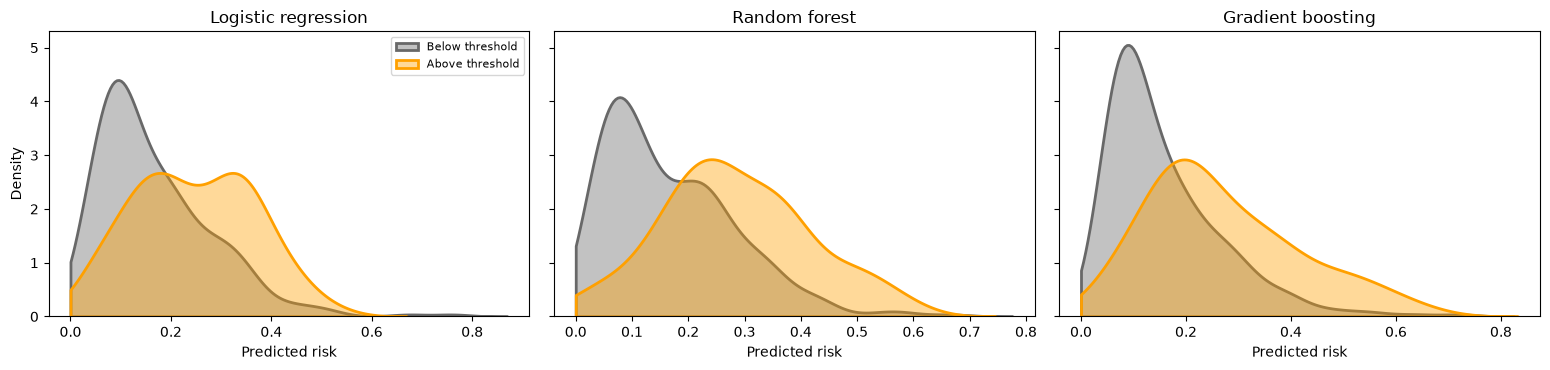

In [55]:
viz.threshold_tradeoff()   # what the decision cutoff costs and buys
viz.confusion_matrices()   # counts of right and wrong calls
viz.risk_distributions()   # how well safe and contaminated wells separate

**How to read these.** Moving the cutoff right flags fewer wells: precision tends to rise and recall falls. The dashed line marks the cutoff actually used. In the confusion matrices, the right-hand cell of the bottom row is the share of contaminated wells caught (recall). In the distributions, the less the amber and gray shapes overlap, the better separated the groups are. Heavy overlap is the visual form of "this is a hard prediction problem."

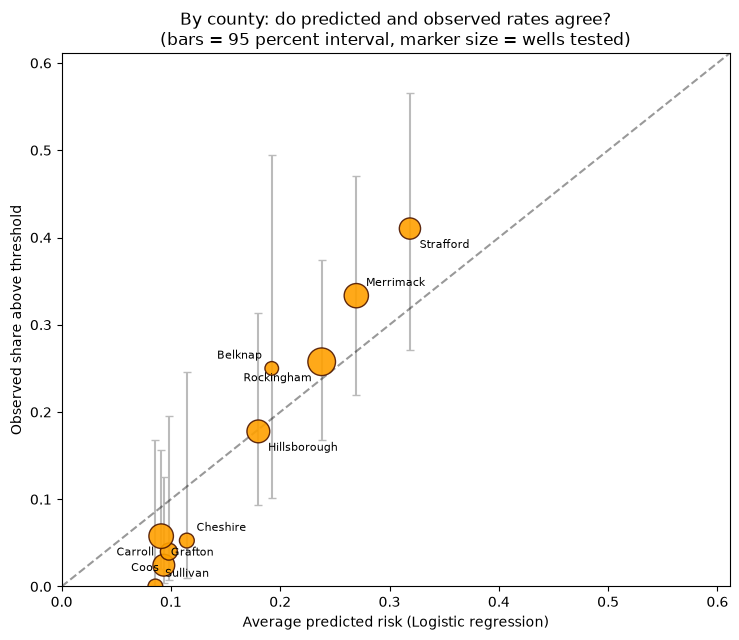

      county  n  k  predicted  observed
     Belknap 16  4     0.1920    0.2500
     Carroll 41  1     0.0940    0.0240
    Cheshire 19  1     0.1150    0.0530
        Coos 25  1     0.0980    0.0400
     Grafton 52  3     0.0910    0.0580
Hillsborough 45  8     0.1800    0.1780
   Merrimack 51 17     0.2700    0.3330
  Rockingham 66 17     0.2380    0.2580
   Strafford 39 16     0.3190    0.4100
    Sullivan 19  0     0.0860    0.0000


In [56]:
if validation_report["has_county"]:
    county_table = viz.county_calibration(df, model=best_model_name)   # observed vs. predicted rate by county, for the model that section 20 selected
    print(county_table.round(3).to_string(index=False))
else:
    print("[skipped] this dataset has no County column.")

**How to read this.** Each dot is a county, sized by how many wells it has. A dot on the diagonal means the model's average risk matches that county's real rate. The gray bars are 95 percent intervals on the observed rate, and they are wide for counties with few wells, which is data suppression made visible. If the dots spread out vertically but stay bunched horizontally, the model predicts nearly the same risk everywhere while real county rates differ, so county-level differences are not being captured by these predictors.

**What this shows.** For the selected model (logistic regression), predicted and observed rates move together: the three highest counties by predicted risk (Strafford, Merrimack, Rockingham) are also the three highest observed. The model under-predicts the top (Strafford 32% predicted against 41% observed) and over-predicts the bottom (Carroll 9% against 2%, Sullivan 9% against 0%), which is the compression described in section 22. The gray bars are wide for the smaller counties (Belknap, Cheshire, Sullivan have 16 to 19 wells each), so differences there should not be over-read.

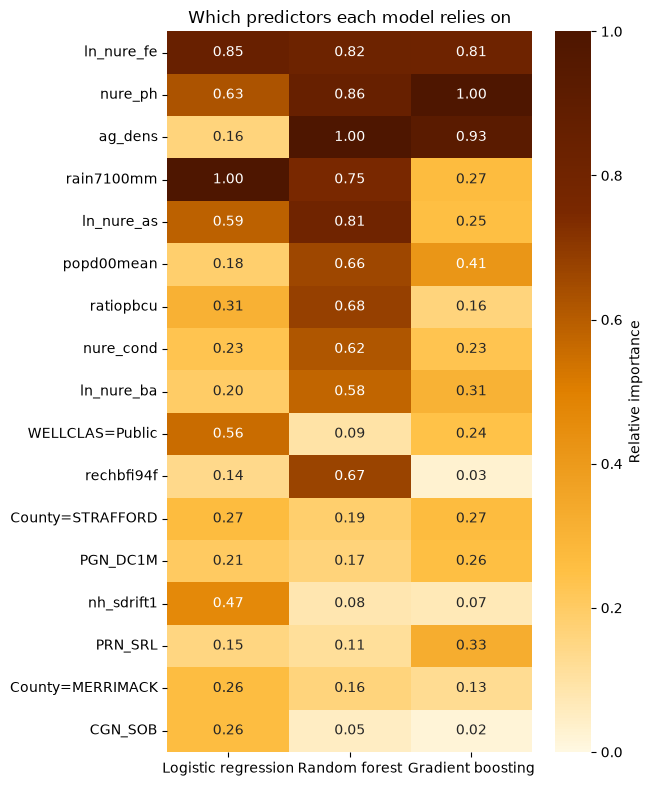

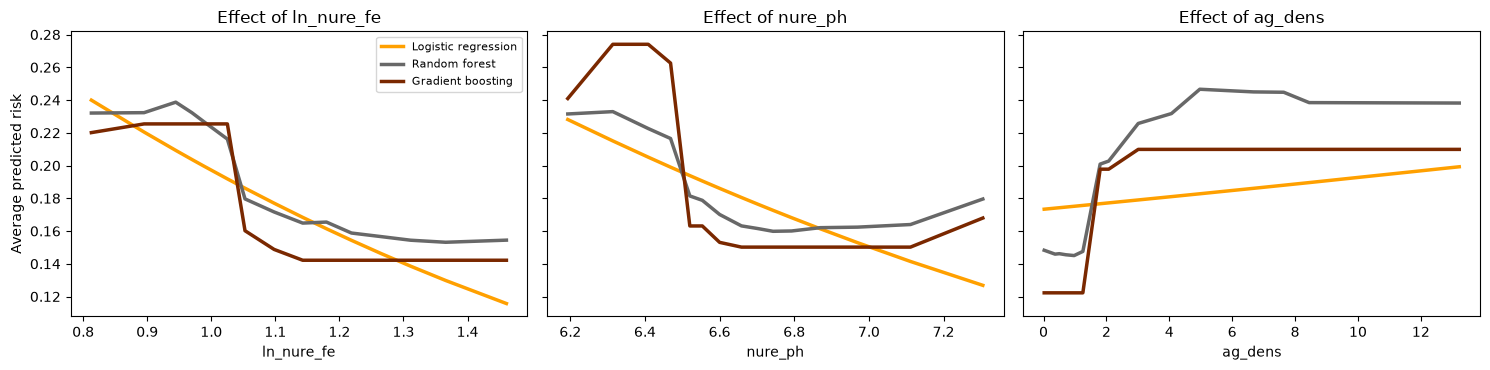

In [57]:
importance = viz.importance_heatmap()   # predictor importance for each tuned model, scaled so each model's top feature is 1
pdp_features = viz.partial_dependence() # how risk changes as each of the top predictors moves

In [58]:
# Do the models and the earlier statistical screening point at the same predictors?
if HAS_SCIPY:
    survivors = set(screening_results.loc[screening_results["significant_after_fdr"], "predictor"])      # survived the FDR correction in section 10
    top_of_each = {name: set(importance[name].sort_values(ascending=False).index[:10]) for name in importance.columns}
    in_all_models = set.intersection(*top_of_each.values())                                               # in every model's top 10
    print("In the top 10 of all three models:", sorted(in_all_models))
    print("Survived the FDR correction in section 10:", sorted(survivors))
    print("Both:", sorted(in_all_models & survivors))

In the top 10 of all three models: ['ln_nure_as', 'ln_nure_fe', 'nure_ph', 'rain7100mm']
Survived the FDR correction in section 10: ['County', 'PGN_DC1M', 'PRN_SRL', 'WELLCLAS', 'ag_class', 'ag_dens', 'ln_nure_as', 'ln_nure_fe', 'nure_cond', 'nure_ph', 'ratiopbcu']
Both: ['ln_nure_as', 'ln_nure_fe', 'nure_ph']


**How to read these.** The heatmap compares models on one scale: each model's top feature is 1, and for logistic regression the importance is the coefficient times the feature's standard deviation, so 0/1 flags and continuous predictors are measured fairly. A predictor that is dark in all three columns, and also survived the FDR correction in section 10, has been picked out by four different methods, which is much stronger evidence than any one of them. In the partial dependence plots, logistic regression draws a smooth curve by construction, while the tree models draw steps. Where the trees follow the smooth curve, the straight-line assumption is fine. Where they bend away, the effect is nonlinear.

Tree importances (the random forest and boosting columns) tend to favor continuous predictors with many distinct values, so read small differences between them cautiously.

## 22. What We Can Conclude

These conclusions come from this run. Each one states the number it rests on, so the wording can be checked against the tables above. Intervals are 95 percent bootstrap intervals.

**1. Is there real signal? Yes, but a modest one.** The selected model, logistic regression, reaches a PR-AUC of 0.330 (interval 0.255 to 0.447). A model with no skill scores 0.182, the share of contaminated wells, so the whole interval sits above no-skill and the score is about 1.8 times that baseline. The other two models are also clearly above no-skill (random forest 0.378, gradient boosting 0.371). Geology and geochemistry therefore carry real information about which wells exceed 5 µg/L, but not enough to be decisive: the ROC-AUC is 0.71.

**2. Which model? Logistic regression, chosen by a rule fixed in advance.** Random forest had the highest PR-AUC, but its lead over logistic regression (+0.049, interval −0.020 to +0.116) includes zero. No pair of models differs clearly on PR-AUC or MCC, and McNemar's test on the contaminated wells gives p between 0.48 and 0.82 for every pair. With 373 wells the data cannot tell the three models apart, so the simplest one wins. A more flexible model did not earn its extra complexity here.

**3. What does a flagged well mean?** At its chosen cutoff, logistic regression catches about 72 of every 100 contaminated wells, and correctly clears about 55 of every 100 safe wells, but only about 26 of every 100 flagged wells are truly above the threshold. About three flags in four are false alarms. That trade (find most contaminated wells, at the cost of many extra tests) suits deciding which wells to test first. It does not suit declaring a particular well unsafe.

**4. Are the predicted risks trustworthy as numbers? Only roughly.** The Brier score is 0.138 against 0.149 for no skill, a modest improvement. Use the risks to *rank* wells, not as exact percentages. The county view shows the same pattern: the model orders the ten counties very closely to the real rates (rank agreement 0.93), but compresses them, predicting 9% to 32% where the real rates run from 0% to 41%.

**5. Which predictors matter, and in which direction?**
- Three predictors are picked out by every method: `ln_nure_as`, `ln_nure_fe` and `nure_ph` are in the top 10 of all three models and also survived the false-discovery correction in section 10. `rain7100mm` is in all three models' top 10 as well, but did not survive the screening on its own.
- In the inferential model (McFadden's R² of 0.12), three effects are clearly distinguishable from none. A higher `ln_nure_as` raises the odds (odds ratio 1.60 per standard deviation, interval 1.18 to 2.17), while more rainfall (0.45, interval 0.29 to 0.72) and a mapped stratified-drift aquifer (0.40, interval 0.20 to 0.79) lower them.
- `ln_nure_fe` points the expected way (iron binding arsenic, odds ratio 0.63), but its interval just reaches 1 (0.40 to 1.01). `ratiopbcu` (1.24, interval 0.78 to 1.96) shows no clear effect.
- `nure_ph` points the *opposite* way from the usual expectation that a higher pH mobilizes arsenic (odds ratio 0.74, interval 0.52 to 1.06), though its interval includes 1. The data dictionary describes it as coming from the NURE groundwater survey, so check the dataset's metadata file (`Testing_data.xml`) to see whether it is a regional value or a measurement at each well before reading anything into the sign. Treat it as unresolved.
- `County` is the strongest categorical association in the screening (Cramér's V 0.35, with one sparse cell, so interpret it cautiously). `ag_dens` and `ag_class` also survive, but they overlap heavily with each other (VIF 13 and 10), so read them as one land-use signal, not two.
- The p-values here are exploratory (see section 18).

**6. Did tuning matter? Barely.** Logistic regression chose C = 0.1 in 8 of 10 folds, and gradient boosting chose 100 rounds in 7 of 10. The gradient boosting search did flag its best `n_estimators` as sitting at the edge of the grid. But even if that row kept improving at 500 rounds, a gain of a few thousandths of log-loss would be far smaller than the fold-to-fold spread of about 0.03, so widening the grid would not change these conclusions.

**What this analysis cannot establish, whatever the numbers say:**
- It is association, not cause. A predictor that flags wells is not necessarily what puts arsenic in them.
- The wells are a USGS testing set, not a random sample of New Hampshire wells, so exceedance rates here are not the statewide share of contaminated wells.
- It describes the water in a well, not any person's exposure or health.
- With 373 wells and 68 contaminated ones, wide intervals are the honest result, not a flaw to fix by reporting a single number.
- The tuned models used for sections 18 and 21 were fit on all wells, so their explanatory plots describe this dataset, not new wells. Only section 19's numbers estimate performance on wells the models have not seen.

## 23. How This Ties Back to the Capstone

The capstone asks whether New Hampshire's high cancer incidence reflects real disease burden or a masking effect, where higher income brings more screening and therefore more *detected* cases. Arsenic matters to that question because it is a **true exposure**, and an exposure can raise incidence whether or not anyone is screening more.

**Why this speaks mostly to bladder cancer.** Bladder cancer has no organized screening program, so screening intensity is a weaker explanation for a high rate there than it would be for breast cancer. A documented, region-specific carcinogen in drinking water is a plausible competing explanation, and this notebook builds the tool to map it.

**What this project adds to the paradox.**
- A county-level estimate of well-water arsenic risk, with honest uncertainty, that the capstone dashboard did not have. Section 21's county plot shows how much of the county-to-county variation the models capture, and the intervals show how much the data can say about counties with few wells.
- A way to test whether arsenic is a **confounder**. If the counties with the highest arsenic risk are also the higher-income ones (check this against the capstone's own county income data), then income and exposure travel together. The masking effect and a true exposure effect then become two explanations for the same county pattern, and separating them is the capstone's real question.

**The next analysis.** Join each county's exceedance rate, with its interval, to the capstone's county bladder cancer incidence and income. With only 10 counties this supports a careful, descriptive comparison (rank correlations and plots), not strong inference. The hierarchical model planned in section 24 would help by pulling the rates of counties with few tested wells toward the state average instead of trusting them at face value.

**Limits to state out loud.**
- This is an ecological comparison: a pattern across counties does not show that individuals in those counties were harmed.
- These wells were sampled in 2004 to 2006, and bladder cancer typically appears decades after exposure, so the timing is plausible but unproven.
- The data does not say what share of each county's residents actually drink from private wells, which is needed to turn well-water risk into population exposure.
- It predicts arsenic in water, not bladder cancer. Individual-level cancer data for this population is restricted, so the link to cancer rests on the published epidemiology, not on anything computed here.

## 24. What's Next

Sections 13 to 21 built, tuned, selected, and explained the models. These remain, each to be added and tested the same way as the classes above.

**A hierarchical model for small groups.** This dataset was chosen to work with small, suppressed data, and the tools above only *show* that problem (wide county intervals, rare flags merged). A hierarchical model *treats* it. Instead of trusting a county's raw rate when it has few wells, it blends that rate with the overall rate. In its simplest form, the estimate for group $j$ with $n_j$ wells is

$$\hat p_j=\frac{n_j}{n_j+k}\,\bar p_j+\frac{k}{n_j+k}\,\bar p_{\text{all}}$$

where $\bar p_j$ is the group's own rate and $k$ reflects how much real variation exists between groups. A group with many wells keeps nearly its own rate. A group with few is pulled toward the state average. This is a more principled version of the instinct behind data suppression rules: adjust for how little is known rather than simply hiding the number.

**Joining the county results to the capstone data**, as described in section 23.

**A continuous statewide risk surface.** The maps in section 9 summarize results by county because that is what the well data supports directly. A further step would use a trained model to predict arsenic risk across a continuous grid covering all of New Hampshire, the approach USGS itself used in a related 2011 study. That needs additional statewide layers (bedrock geology, geochemistry, precipitation), not just this table of wells.

**An interactive website** where someone could see the map, get a model's prediction with its uncertainty range, and compare it against the published USGS benchmark directly.

In [59]:
# Save the cleaned dataset and the model results for the next phase.
df_z.to_csv(OUTPUT_DIR / "nh_arsenic_cleaned.csv", index=False)
evaluator.summary().to_csv(OUTPUT_DIR / "model_evaluation_summary.csv")
evaluator.cv_spread().to_csv(OUTPUT_DIR / "model_cv_spread.csv")
if "report" in globals():
    report.table_.to_csv(OUTPUT_DIR / "odds_ratios.csv", index=False)

print(f"Cleaned dataset saved to {OUTPUT_DIR / 'nh_arsenic_cleaned.csv'}")
print(f"Model results saved under {OUTPUT_DIR.resolve()}")

Cleaned dataset saved to outputs\nh_arsenic_cleaned.csv
Model results saved under C:\Users\f003cc3\Documents\hds\HSE 751 Programming for HDS\Final Project\Final\Final_Project\outputs


## 25. Audit: What This Notebook Generated, and Whether It Meets the Brief

A last pass that checks the notebook against itself. It has two parts.

**Part A lists every file the notebook should have produced,** with its size and the section that made it. A file shows as `MISSING` if it should exist and does not, and as `SKIPPED` if it depends on an optional package (`scipy` or `geopandas`) that is not installed.

**Part B checks each requirement of the brief against live evidence** from this run, not against a claim. For example, it re-runs the error handling on deliberately bad input to confirm the right error is raised. Statuses:
- `PASS`: the evidence was found and it checks out.
- `FAIL`: something is missing or does not match. Fix it before submitting.
- `SKIPPED`: an optional package is absent, so the item could not run here.
- `MANUAL`: it can only be judged by reading (comments, LaTeX, workflow), so look at it yourself.

Everything saved is under the `outputs/` folder. Every figure shown in the notebook is also archived in `outputs/figures/`.

In [60]:
def _raises(error, function, *args):
    """True if calling function(*args) raises exactly the kind of error we expect."""
    try:
        function(*args)
    except error:
        return True
    except Exception:
        return False
    return False

def run_audit():
    """List every generated file, then check each requirement of the brief against live evidence."""
    expected = [
        ("data_profile.csv", "automatic profile of the uploaded file", "section 2", True),
        ("data_dictionary.csv", "every predictor with its confidence level", "section 4", True),
        ("data_quality_report.txt", "missing values, impossible values, outliers, rare flags", "section 5", True),
        ("01_class_balance.png", "class balance chart", "section 8", True),
        ("02_numeric_distributions.png", "distributions of the numeric predictors", "section 8", True),
        ("03_correlation_heatmap.png", "correlation heatmap", "section 8", True),
        ("05_county_choropleth.png", "bivariate county map (exceedance by testing coverage)", "section 9", HAS_GEO),
        ("06_well_dot_density_map.png", "approximate well-location map", "section 9", HAS_GEO),
        ("statistical_screening.csv", "one significance test per predictor, FDR-corrected", "section 10", HAS_SCIPY),
        ("vif_table.csv", "multicollinearity check", "section 10", True),
        ("pipeline_plan.json", "the settings the data and goal produced", "section 12", True),
        ("model_selection_report.txt", "selected model, justification, interpretation", "section 20", True),
        ("model_evaluation_summary.csv", "every metric for every model, with intervals", "section 24", True),
        ("model_cv_spread.csv", "how much each score moves between repeats", "section 24", True),
        ("odds_ratios.csv", "odds ratios with confidence intervals", "section 24", "report" in globals()),
        ("nh_arsenic_cleaned.csv", "cleaned dataset with standardized columns", "section 24", True),
    ]
    print("PART A. FILES THIS NOTEBOOK GENERATED\n")
    missing = 0
    for name, purpose, where, needed in expected:
        path = OUTPUT_DIR / name
        if path.exists():
            status = f"PRESENT ({path.stat().st_size / 1024:.1f} KB)"
        elif not needed:
            status = "SKIPPED (optional)"
        else:
            status, missing = "MISSING", missing + 1
        print(f"  {status:<30} {name:<32} {purpose} [{where}]")
    n_figures = len(list(FIGURE_DIR.glob("*.png")))
    print(f"  {'PRESENT' if n_figures else 'MISSING':<30} {'figures/ (' + str(n_figures) + ' images)':<32} every figure shown in the notebook, archived")
    print(f"\n  {len(expected) - missing} of {len(expected)} expected files present; {n_figures} figures archived.")

    error_tests = {
        "a missing file raises DataLoadError": _raises(DataLoadError, pick_file, "no_such_file_anywhere.csv"),
        "an unsupported file type raises DataLoadError": _raises(DataLoadError, read_table, io.BytesIO(b"x"), "notes.txt"),
        "an empty table raises DataValidationError": _raises(DataValidationError, validate_user_dataframe, pd.DataFrame()),
        "an unknown metric raises ValueError": _raises(ValueError, select_best_model, evaluator, "not_a_metric", USER_GOAL),
    }
    results = []
    def check(item, requirement, function):
        try:
            ok, evidence = function()
            results.append((item, requirement, evidence, "PASS" if ok else "FAIL"))
        except Exception as exc:
            results.append((item, requirement, f"could not check ({type(exc).__name__}: {exc})", "FAIL"))
    def manual(item, requirement, evidence):
        results.append((item, requirement, evidence, "MANUAL"))

    check("1.1", "Upload a dataset from the local environment", lambda: (len(raw_df) > 0, f"read '{upload_name}' ({len(raw_df)} rows) from {INPUT_SOURCE['how']}"))
    check("1.2", "Automated profiling and basic validation", lambda: (len(data_profile) == raw_df.shape[1] and validation_report["passed"], f"{len(data_profile)} columns profiled; validation passed with {len(validation_report['warnings'])} warning(s)"))
    check("1.3", "Confirm successful upload and validation", lambda: (validation_report["passed"], "confirmation printed in section 2"))
    check("2.1", "Clean and pre-process the dataset", lambda: (bool(quality_report_text) and len(demo.feature_names_) > 0, f"{len(df.columns)} columns audited; {len(demo.feature_names_)} model-ready features; {len(demo.rare_cols_)} rare flag(s) merged; {len(demo.constant_cols_)} constant column(s) dropped"))
    check("2.2", "Generate descriptive statistics", lambda: (descriptive.shape[0] > 0, f"{descriptive.shape[0]} numeric columns summarized (mean, SD, skew, kurtosis, % missing)"))
    check("2.3", "Exploratory visualizations (at least two)", lambda: (all((OUTPUT_DIR / f).exists() for f in ["01_class_balance.png", "02_numeric_distributions.png", "03_correlation_heatmap.png"]), "class balance, distributions, correlation heatmap"))
    if HAS_GEO:
        check("2.4", "NH county maps", lambda: (all((OUTPUT_DIR / f).exists() for f in ["05_county_choropleth.png", "06_well_dot_density_map.png"]), "bivariate county map and dot-density well map"))
    else:
        results.append(("2.4", "NH county maps", "geopandas/shapely are not installed here, so the maps were skipped", "SKIPPED"))
    def inferential():
        methods = sorted(set(screening_results["test"])) if HAS_SCIPY else []
        if "report" in globals():
            methods += ["Wald test", "likelihood-ratio test"]
        methods += ["bootstrap intervals", "McNemar's test"]
        return len(methods) >= 2 and bool(evaluator.boot_), ", ".join(methods) + "; Benjamini-Hochberg correction"
    check("3.1", "At least two inferential statistical methods", inferential)
    manual("3.2", "A relevant formula in LaTeX, explained", "see the math in sections 7, 10, 14 to 16, 18, 19 and 20 (it renders in the markdown)")
    check("3.3", "Supervised classification models", lambda: (len(specs) >= 3 and all(s.name in cv_results["probabilities"] for s in specs), ", ".join(s.name for s in specs)))
    check("3.4", "Conditional logic that adapts the pipeline", lambda: (suite.n_splits == plan["n_splits"] and suite.n_repeats == plan["n_repeats"] and tuner.n_splits == plan["n_splits"],
          f"folds, repeats, and inference predictors come from plan_pipeline(); the goal '{USER_GOAL}' set the metric; {len(plan['notes'])} adaptation note(s) for this data"))
    check("4.1", "Report accuracy, recall, precision, F1 (and more)", lambda: (all(m in evaluator.METRICS for m in ["accuracy", "recall", "precision", "f1"]) and not evaluator.summary().empty, f"{len(evaluator.METRICS)} metrics, each with a bootstrap interval"))
    check("4.2", "Clear interpretation of results", lambda: (len(selection["lines"]) >= 5 and (OUTPUT_DIR / "model_selection_report.txt").exists(), "plain-language interpretation printed and saved in section 20"))
    check("4.3", "Best model chosen by a predefined primary metric, with justification", lambda: (selection["primary_metric"] == PRIMARY_METRIC == plan["primary_metric"], f"metric '{PRIMARY_METRIC}' fixed in section 2 from goal '{USER_GOAL}'; selected: {selection['chosen']}"))
    classes = ["ArsenicDataset", "DataQualityAuditor", "StatisticalScreener", "EDAVisualizer", "BivariateMapVisualizer", "Preprocessor", "ModelSpec", "HyperparameterTuner", "ModelSuite", "ModelEvaluator", "ModelVisualizer", "InferentialReport"]
    check("5.1", "Modular functions and classes", lambda: (all(c in globals() for c in classes), f"{len(classes)} classes, each with one job, plus helper functions"))
    manual("5.2", "Clear inline comments", "read the code cells: each class and function has a docstring, and non-obvious lines have a side comment")
    check("5.3", "Error handling and input validation", lambda: (all(error_tests.values()), "; ".join(f"{k}: {'ok' if v else 'FAILED'}" for k, v in error_tests.items())))
    manual("5.4", "A logical, structured workflow", "Part 1 input, Part 2 processing, Part 3 analysis, Part 4 evaluation")

    print("\nPART B. REQUIREMENTS CHECKED AGAINST LIVE EVIDENCE\n")
    for item, requirement, evidence, status in results:
        print(f"  [{status:<7}] {item}  {requirement}\n             {evidence}")
    counts = {s: sum(1 for r in results if r[3] == s) for s in ("PASS", "FAIL", "SKIPPED", "MANUAL")}
    print(f"\n  Summary: {counts['PASS']} PASS, {counts['FAIL']} FAIL, {counts['SKIPPED']} SKIPPED, {counts['MANUAL']} to check by reading.")
    table = pd.DataFrame(results, columns=["item", "requirement", "evidence", "status"])
    table.to_csv(OUTPUT_DIR / "audit_checklist.csv", index=False)
    print(f"  Saved: {OUTPUT_DIR / 'audit_checklist.csv'}")
    return table

print("run_audit defined.")

run_audit defined.


In [61]:
audit = run_audit()   # prints the file checklist and the requirements checklist, and saves the second as audit_checklist.csv

PART A. FILES THIS NOTEBOOK GENERATED

  PRESENT (1.6 KB)               data_profile.csv                 automatic profile of the uploaded file [section 2]
  PRESENT (4.8 KB)               data_dictionary.csv              every predictor with its confidence level [section 4]
  PRESENT (1.8 KB)               data_quality_report.txt          missing values, impossible values, outliers, rare flags [section 5]
  PRESENT (16.8 KB)              01_class_balance.png             class balance chart [section 8]
  PRESENT (216.3 KB)             02_numeric_distributions.png     distributions of the numeric predictors [section 8]
  PRESENT (47.6 KB)              03_correlation_heatmap.png       correlation heatmap [section 8]
  PRESENT (118.2 KB)             05_county_choropleth.png         bivariate county map (exceedance by testing coverage) [section 9]
  PRESENT (211.1 KB)             06_well_dot_density_map.png      approximate well-location map [section 9]
  PRESENT (4.6 KB)               sta